# Example 5.8 — Clustered selectivity heat map and R-groups of the imatinib core

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:56:07Z
- **Contents:** 1 exchange · 8 tool calls · 3 figures · 1 code cell

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/`, the figures in `figures/` and the analysis code the notebook imports (`selectivity_heatmap.py`). With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/5.8-scaffold-selectivity-clustering-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 5.8-scaffold-selectivity-clustering-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 5.8-scaffold-selectivity-clustering-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/5.8-scaffold-selectivity-clustering-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 5.8-scaffold-selectivity-clustering-notebook-rerun.ipynb 5.8-scaffold-selectivity-clustering-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed. Code cells hold the analysis code the model wrote; they run as written (reading the results with `replay.result(n)`, the result of Call n) and draw their figures again, which are not compared.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Find the compounds that contain the 2-anilino-4-(3-pyridyl)pyrimidine substructure, the core scaffold of imatinib and nilotinib. Build a hierarchically clustered heat map of their binding affinities across the kinase targets they've been tested against, so I can see how the analogs group by selectivity profile. Distinguish the type of binding affinity in the heat map. If there are multiple measurements, use the median affinity. Choose the compounds and targets so the matrix is informative rather than mostly empty. Note any caveats about data coverage. Then create an R-group decomposition and list the compounds in the same order as in the heatmap.

In [ ]:
# Call 1 · search_compounds · ran 2026-11-24 04:55:56 UTC
await replay.call(1, 'search_compounds', {'query': 'imatinib', 'limit': 3},
                  sha256='1f2a50bf819de48009ec8144d0b21eef4aca07d81ee80cd8718d9c5f2d42211d')

**Call 1** · `search_compounds` · recorded result · sha256 `1f2a50bf819d…`

_3 rows_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 13530 | BDBM13530 | Gleevec | KTUFNOKKBVMGRW-UHFFFAOYSA-N | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 493.26 | 1156 | 459 | Imatinib |
| 31341 | BDBM31341 | IMATINIB | KTUFNOKKBVMGRW-UHFFFAOYSA-N | Cc1ccc(cc1Nc2nccc(n2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C |  | 0 | 0 | IMATINIB |
| 50434581 | BDBM50434581 | imatinib-CD3 | KTUFNOKKBVMGRW-BMSJAHLVSA-N | \[2H\]C(\[2H\])(\[2H\])N5CCN(Cc4ccc(C(=O)Nc3ccc(C)c(Nc2nccc(c1cccnc1)n2)c3)cc4)CC5 | 496.58 | 2 | 2 | imatinib-CD3 |


In [ ]:
# Call 2 · search_compounds · ran 2026-11-24 04:55:56 UTC
await replay.call(2, 'search_compounds', {'query': 'nilotinib', 'limit': 3},
                  sha256='ac3861dbb71b53628fbe24fbba2020f6f21474b63a1d04bda6bbd311c2e49fa5')

**Call 2** · `search_compounds` · recorded result · sha256 `ac3861dbb71b…`

_1 row_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50237710 | BDBM50237710 | NILOTINIB | HHZIURLSWUIHRB-UHFFFAOYSA-N | Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc(c1)C(F)(F)F | 529.18 | 614 | 409 | NILOTINIB |


In [ ]:
# Call 3 · substructure_search · ran 2026-11-24 04:56:05 UTC
await replay.call(3, 'substructure_search', {'query': 'c1ccc(Nc2nccc(-c3cccnc3)n2)cc1', 'count_only': True},
                  sha256='bd808d64938931c9b65154c476b1988ff3c7c2c3c4862eb90bb9679758345ec1')

**Call 3** · `substructure_search` · recorded result · sha256 `bd808d649389…`

| name | smiles |
| --- | --- |
| query | c1ccc(Nc2nccc(-c3cccnc3)n2)cc1 |

```json
{
  "query": {
    "input": "c1ccc(Nc2nccc(-c3cccnc3)n2)cc1",
    "interpreted_as": "smiles",
    "canonical": "c1ccc(Nc2nccc(-c3cccnc3)n2)cc1"
  },
  "n_matching_compounds": 460,
  "compounds_searched": 1466457,
  "compounds_indexed": 1466457
}
```


In [ ]:
# Call 4 · substructure_search · ran 2026-11-24 04:56:05 UTC
await replay.call(4, 'substructure_search', {'query': 'c1ccc(Nc2nccc(-c3cccnc3)n2)cc1', 'limit': 500},
                  sha256='0b090e45c7968102e501ab2e4ef5d53796c765d6f4d252c20962176ddb0c0294')

**Call 4** · `substructure_search` · recorded result · sha256 `0b090e45c796…`

| name | smiles |
| --- | --- |
| query | c1ccc(Nc2nccc(-c3cccnc3)n2)cc1 |

```json
{
  "query": {
    "input": "c1ccc(Nc2nccc(-c3cccnc3)n2)cc1",
    "interpreted_as": "smiles",
    "canonical": "c1ccc(Nc2nccc(-c3cccnc3)n2)cc1"
  },
  "compounds_searched": 1466457,
  "search_set_size": 1466457
}
```

_460 rows_

| monomerid | bdbm_id | name | smiles | mol_weight | n_activities | n_targets |
| --- | --- | --- | --- | --- | --- | --- |
| 13530 | BDBM13530 | Gleevec | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 493.26 | 1156 | 459 |
| 50237710 | BDBM50237710 | NILOTINIB | Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc(c1)C(F)(F)F | 529.18 | 614 | 409 |
| 86734 | BDBM86734 | Gleevec | Cc3ccc(NC(=O)c2ccc(CN1CCN(C)CC1)cc2)cc3Nc5nccc(c4cccnc4)n5 | 493.26 | 66 | 10 |
| 86633 | BDBM86633 | JNK-IN-8 | CN(C)C\\C=C\\C(=O)Nc1cccc(c1)C(=O)Nc1ccc(Nc2nccc(n2)-c2cccnc2)c(C)c1 | 507.24 | 27 | 3 |
| 86632 | BDBM86632 | JNK-IN-7 | CN(C)C\\C=C\\C(=O)Nc1cccc(c1)C(=O)Nc1ccc(Nc2nccc(n2)-c2cccnc2)cc1 | 493.22 | 22 | 5 |
| 50175493 | BDBM50175493 | N-\[3-(4-Pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | O=C(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)c1ccccc1 | 367.14 | 20 | 9 |
| 50175491 | BDBM50175491 | 4-Methyl-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Cc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 395.17 | 19 | 8 |
| 397156 | BDBM397156 | US9987276, Compound I-56 | Cc1ccc(NC(=O)C=C)cc1Nc1nccc(n1)-c1cccnc1 | 331.14 | 18 | 6 |
| 50240407 | BDBM50240407 | N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccccc2)cc1Nc1nccc(n1)-c1cccnc1 | 381.16 | 17 | 9 |
| 50287097 | BDBM50287097 | 4-Methyl-N\*3\*-(4-pyridin-3-yl-pyrimidin-2-yl)-benzene-1,3-diamine | Cc1ccc(N)cc1Nc1nccc(n1)-c1cccnc1 | 277.324 | 15 | 9 |
| 50240406 | BDBM50240406 | N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)acetamide | CC(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 319.14 | 14 | 8 |
| 50287090 | BDBM50287090 | 4-Chloro-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Cc1ccc(NC(=O)c2ccc(Cl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 415.875 | 14 | 8 |
| 50287091 | BDBM50287091 | Naphthalene-2-carboxylic acid \[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | Cc1ccc(NC(=O)c2ccc3ccccc3c2)cc1Nc1nccc(n1)-c1cccnc1 | 431.489 | 14 | 8 |
| 50287096 | BDBM50287096 | 2-Methoxy-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | COc1ccccc1C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 411.456 | 14 | 8 |
| 50425385 | BDBM50425385 | CHEMBL2311807 | Cc1cn(cn1)-c1cc(F)cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 479.51 | 14 | 8 |
| 50425386 | BDBM50425386 | CHEMBL2311808 | Cc1cn(cn1)-c1cccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 461.52 | 14 | 8 |
| 50425387 | BDBM50425387 | CHEMBL2311806 | Cc1cn(cn1)-c1cc(C)cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 475.54 | 14 | 8 |
| 50290422 | BDBM50290422 | 4-(4-Methyl-piperazin-1-ylmethyl)-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2cccc(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 479.576 | 12 | 11 |
| 86627 | BDBM86627 | JNK-IN-2 | CN(C)C\\C=C\\C(=O)Nc1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 493.22 | 11 | 3 |
| 50290417 | BDBM50290417 | 2-Amino-pyrimidine, 19 | O=C(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)c1cccnc1 | 368.391 | 10 | 10 |
| 86626 | BDBM86626 | JNK-IN-1 | CN(C)C\\C=C\\C(=O)Nc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 507.24 | 9 | 3 |
| 481131 | BDBM481131 | US10906896, Cpd 832 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccn(C)n3)c2)CC1 | 573.3 | 9 | 3 |
| 481135 | BDBM481135 | BDBM481139 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccns3)c2)CC1 | 576.24 | 9 | 3 |
| 50045528 | BDBM50045528 | N-(4-Pyridin-3-yl-pyrimidin-2-yl)-benzene-1,3-diamine | Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 263.12 | 9 | 9 |
| 50045481 | BDBM50045481 | (3-Imidazol-1-yl-phenyl)-(4-pyridin-3-yl-pyrimidin-2-yl)-amine | N(c1cccc(c1)-n1ccnc1)c1nccc(n1)-c1cccnc1 | 314.13 | 8 | 8 |
| 50045485 | BDBM50045485 | (3-Chloro-phenyl)-(4-pyridin-3-yl-pyrimidin-2-yl)-amine | Clc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 282.07 | 8 | 8 |
| 50045526 | BDBM50045526 | \[3-(2-Imidazol-1-yl-ethoxy)-phenyl\]-(4-pyridin-3-yl-pyrimidin-2-yl)-amine | C(Cn1ccnc1)Oc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 358.15 | 8 | 8 |
| 50290411 | BDBM50290411 | 4-Cyano-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | O=C(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)c1ccc(cc1)C#N | 392.413 | 8 | 8 |
| 50290421 | BDBM50290421 | N-\[3-(4-Pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-isonicotinamide | O=C(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)c1ccncc1 | 368.391 | 8 | 8 |
| 50290423 | BDBM50290423 | (3-Nitro-phenyl)-(4-pyridin-3-yl-pyrimidin-2-yl)-amine | \[O-\]\[N+\](=O)c1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 293.28 | 8 | 8 |
| 50290429 | BDBM50290429 | 2-Methoxy-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | COc1ccccc1C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 397.429 | 8 | 8 |
| 50045424 | BDBM50045424 | Phenyl-(4-pyridin-3-yl-pyrimidin-2-yl)-amine | N(c1ccccc1)c1nccc(n1)-c1cccnc1 | 248.11 | 7 | 7 |
| 106562 | BDBM106562 | US8586600, III-14 | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(NC(=O)CCl)c(c1)C(F)(F)F | 540.13 | 6 | 3 |
| 120388 | BDBM120388 | US8703771, 1 | CN1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 519.27 | 6 | 3 |
| 481127 | BDBM481127 | US10906896, Cpd 806 | Cc1cc(on1)-c1cncc(c1)-c1ccnc(Nc2cc(NC(=O)c3ccc(CN4CCNCC4)cc3)ccc2C)n1 | 560.26 | 6 | 3 |
| 481128 | BDBM481128 | US10906896, Cpd 809 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3oncc3C)c2)CC1 | 574.28 | 6 | 3 |
| 481129 | BDBM481129 | US10906896, Cpd 820 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccc(C)cn3)c2)CC1 | 584.3 | 6 | 3 |
| 481130 | BDBM481130 | US10906896, Cpd 830 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cc(C)ccn3)c2)CC1 | 584.3 | 6 | 3 |
| 481132 | BDBM481132 | US10906896, Cpd 880 | Cc1ccc(NC(=O)c2ccc(CN3CCNCC3)cc2)cc1Nc1nccc(n1)-c1cncc(c1)-c1ccccn1 | 556.27 | 6 | 3 |
| 481133 | BDBM481133 | US10906896, Cpd 8120 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nnco3)c2)CC1 | 561.26 | 6 | 3 |
| 481134 | BDBM481134 | US10906896, Cpd 8130 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nnc(C)o3)c2)CC1 | 575.28 | 6 | 3 |
| 481136 | BDBM481136 | US10906896, Cpd 8180 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3sncc3C)c2)CC1 | 590.26 | 6 | 3 |
| 481137 | BDBM481137 | US10906896, Cpd 8190 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cc(C)ns3)c2)CC1 | 590.26 | 6 | 3 |
| 481138 | BDBM481138 | US10906896, Cpd 8200 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cnsc3)c2)CC1 | 576.24 | 6 | 3 |
| 481140 | BDBM481140 | US10906896, Cpd 8240 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3snnc3C)c2)CC1 | 591.25 | 6 | 3 |
| 481141 | BDBM481141 | US10906896, Cpd 8250 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nncs3)c2)CC1 | 577.24 | 6 | 3 |
| 481142 | BDBM481142 | US10906896, Cpd 8260 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nnc(C)s3)c2)CC1 | 591.25 | 6 | 3 |
| 481143 | BDBM481143 | US10906896, Cpd 8270 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nccs3)c2)CC1 | 576.24 | 6 | 3 |
| 481144 | BDBM481144 | US10906896, Cpd 8280 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ncc(C)s3)c2)CC1 | 590.26 | 6 | 3 |
| 481145 | BDBM481145 | US10906896, Cpd 8290 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nc(C)cs3)c2)CC1 | 590.26 | 6 | 3 |
| 612772 | BDBM612772 | US11725005, Compound 113 | Cc1cc(-c2cncc(-c3ccnc(Nc4cc(NC(=O)c5ccc(CN6CCN(C)CC6)cc5)ccc4C)n3)c2)\[nH\]n1 | 573.3 | 6 | 3 |
| 50083641 | BDBM50083641 | Aminopyrimidine (Scaffold II) | COc1cc(Nc2nccc(n2)-c2ccc(NCCN)nc2)cc(OC)c1OC | 396.19 | 6 | 6 |
| 50256927 | BDBM50256927 | N-(2-aminophenyl)-4-((4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenylamino)methyl)benzamide | Cc1ccc(NCc2ccc(cc2)C(=O)Nc2ccccc2N)cc1Nc1nccc(n1)-c1cccnc1 | 501.582 | 6 | 4 |
| 50287093 | BDBM50287093 | (2-Methyl-5-nitro-phenyl)-(4-pyridin-3-yl-pyrimidin-2-yl)-amine | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)\[N+\](\[O-\])=O | 307.307 | 6 | 6 |
| 50290410 | BDBM50290410 | 3-(4-Pyridin-3-yl-pyrimidin-2-ylamino)-benzoic acid | OC(=O)c1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 292.292 | 6 | 6 |
| 50290412 | BDBM50290412 | 4-Fluoro-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Fc1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 385.394 | 6 | 6 |
| 50290419 | BDBM50290419 | Cyclohexanecarboxylic acid \[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | O=C(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)C1CCCCC1 | 373.451 | 6 | 6 |
| 50290430 | BDBM50290430 | 4-Methyl-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Cc1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 381.43 | 6 | 6 |
| 50290431 | BDBM50290431 | Hexanoic acid \[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | CCCCCC(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 361.44 | 6 | 6 |
| 50384864 | BDBM50384864 | CHEMBL2035045 | CN1C\\C=C\\COCc2cncc(c2)-c2ccnc(Nc3cccc(C1)c3)n2 \|t:3\| | 373.19 | 6 | 6 |
| 50384865 | BDBM50384865 | CHEMBL2035046 | C1OCc2cccc(Nc3nccc(n3)-c3cncc(COC\\C=C\\1)c3)c2 \|t:24\| | 360.16 | 6 | 6 |
| 50384870 | BDBM50384870 | CHEMBL2035051 | C(CN1CCCC1)Oc1ccc2Nc3nccc(n3)-c3cncc(COC\\C=C\\COCc1c2)c3 \|t:29\| | 473.24 | 6 | 6 |
| 106561 | BDBM106561 | US8586600, III-6 | CN(C)C\\C=C\\C(=O)Nc1ccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1C(F)(F)F | 575.23 | 5 | 3 |
| 50083639 | BDBM50083639 | {4-\[6-((S)-3-Ethyl-piperazin-1-yl)-pyridin-3-yl\]-pyrimidin-2-yl}-(3,4,5-trimethoxy-phenyl)-amine | CC\[C@H\]1CN(CCN1)c1ccc(cn1)-c1ccnc(Nc2cc(OC)c(OC)c(OC)c2)n1 | 450.24 | 5 | 5 |
| 50083643 | BDBM50083643 | (4-Pyridin-3-yl-pyrimidin-2-yl)-(3,4,5-trimethoxy-phenyl)-amine | COc1cc(Nc2nccc(n2)-c2cccnc2)cc(OC)c1OC | 338.14 | 5 | 5 |
| 50083644 | BDBM50083644 | \[4-(6-Piperazin-1-yl-pyridin-3-yl)-pyrimidin-2-yl\]-(3,4,5-trimethoxy-phenyl)-amine | COc1cc(Nc2nccc(n2)-c2ccc(nc2)N2CCNCC2)cc(OC)c1OC | 422.21 | 5 | 5 |
| 50256928 | BDBM50256928 | (E)-N-hydroxy-3-(4-((4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenylamino)methyl)phenyl)acrylamide | Cc1ccc(NCc2ccc(\\C=C\\C(=O)NO)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 452.508 | 5 | 5 |
| 50256929 | BDBM50256929 | N1-(2-aminophenyl)-N4-(3-(methyl(4-(pyridin-3-yl)pyrimidin-2-yl)amino)phenyl)terephthalamide | CN(C(=O)c1ccc(cc1)C(=O)Nc1ccccc1N)c1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 515.565 | 5 | 5 |
| 50287088 | BDBM50287088 | N-\[4-Methoxy-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | COc1ccc(NC(=O)c2ccccc2)cc1Nc1nccc(n1)-c1cccnc1 | 397.429 | 5 | 5 |
| 50287089 | BDBM50287089 | N-Methyl-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | CN(C(=O)c1ccccc1)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 395.456 | 5 | 5 |
| 50287092 | BDBM50287092 | N-Benzoyl-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)N(C(=O)c1ccccc1)C(=O)c1ccccc1 | 485.536 | 5 | 5 |
| 50287094 | BDBM50287094 | N-\[4-Chloro-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Clc1ccc(NC(=O)c2ccccc2)cc1Nc1nccc(n1)-c1cccnc1 | 401.848 | 5 | 5 |
| 50287095 | BDBM50287095 | 4,N\*1\*-Dimethyl-N\*3\*-(4-pyridin-3-yl-pyrimidin-2-yl)-benzene-1,3-diamine | CNc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 291.35 | 5 | 5 |
| 50287098 | BDBM50287098 | N-{4-Methyl-3-\[4-(1-oxy-pyridin-3-yl)-pyrimidin-2-ylamino\]-phenyl}-benzamide | Cc1ccc(NC(=O)c2ccccc2)cc1Nc1nccc(n1)-c1ccc\[n+\](\[O-\])c1 | 397.429 | 5 | 5 |
| 50290414 | BDBM50290414 | N-\[3-(4-Pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-phthalamic acid | OC(=O)c1ccccc1C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 411.413 | 5 | 5 |
| 50290418 | BDBM50290418 | 3-(4-Pyridin-3-yl-pyrimidin-2-ylamino)-benzoic acid methyl ester | COC(=O)c1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 306.319 | 5 | 5 |
| 50290427 | BDBM50290427 | Thiophene-2-carboxylic acid \[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | O=C(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)c1cccs1 | 373.431 | 5 | 5 |
| 50290428 | BDBM50290428 | Pyridine-2-carboxylic acid \[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | O=C(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)c1ccccn1 | 368.391 | 5 | 5 |
| 50434582 | BDBM50434582 | CHEMBL2386594 | Cc1ccc(NC(=O)c2ccc(CN3CCNCC3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 575.68 | 5 | 2 |
| 50462213 | BDBM50462213 | CHEMBL4247298 | CN(C)CCN(Cc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)C(=O)c1cccnc1 | 586.7 | 5 | 5 |
| 50564790 | BDBM50564790 | CHEMBL4781627 | CC(=O)c1c(C)c2ccc(Nc3nccc(n3)-c3cccnc3)cc2oc1=O | 372.38 | 5 | 4 |
| 414520 | BDBM414520 | N-(5-(5-chloro-4-(1-methyl-1H-pyrrolo\[2,3-b\]pyridin-5-yl)pyrimidin-2-amino)-2-((2-(dimethylamino)ethyl)methylamino)-4-methoxyphenyl)acrylamide | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(Cl)c(n1)-c1cnc2n(C)ccc2c1 | 534.23 | 4 | 2 |
| 414522 | BDBM414522 | N-(2-(4-(dimethylamino)piperidin-1-yl)-4-methoxy-5-(4-(1-methyl-1H-pyrazolo\[3,4-b\]pyridin-5-yl)pyrimidin-2-ylamino)phenyl)acrylamide | COc1cc(N2CCC(CC2)N(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ccc2c1 | 526.28 | 4 | 2 |
| 414525 | BDBM414525 | N-(2-((2-(dimethylamino)ethyl)(methyl)amino)-4-methoxy-5-((4-(1-methyl-1H-pyrrolo\[2,3-b\]pyridin-5-yl)pyrimidin-2-yl)amino)phenyl)acrylamide | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ccc2c1 | 500.26 | 4 | 2 |
| 414544 | BDBM414544 | US10435400, Compound comparative | COc1cc(N2CCC(CC2)N(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cccnc1 | 473.25 | 4 | 2 |
| 50290415 | BDBM50290415 | N-(3-Amino-propyl)-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-benzamide | NCCCNC(=O)c1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 348.402 | 4 | 4 |
| 50308199 | BDBM50308199 | 2-(4-Ethoxyanilino)-5,7-dihydro-6H-pyrido\[4,3-b\]pyrimido\[4,5-d\]azepin-6-one | CCOc1ccc(Nc2ncc3CC(=O)Nc4ccncc4-c3n2)cc1 | 347.371 | 4 | 3 |
| 50421671 | BDBM50421671 | CHEMBL5266831 | CN1CCN(CC1)c1ccc(Nc2nccc(n2)-c2cccnc2)cc1C(F)(F)F | 414.44 | 4 | 2 |
| 50500700 | BDBM50500700 | CHEMBL3752481 | Cc1ccc-2c(SCc3cnc(Nc4ccc(cc4)S(N)(=O)=O)nc-23)n1 | 385.47 | 4 | 4 |
| 50500708 | BDBM50500708 | CHEMBL3754807 | NS(=O)(=O)c1ccc(Nc2ncc3CSc4ncccc4-c3n2)cc1 | 371.45 | 4 | 4 |
| 86629 | BDBM86629 | JNK-IN-4 | CN(C)C\\C=C\\C(=O)NCc1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 507.24 | 3 | 3 |
| 86630 | BDBM86630 | JNK-IN-5 | C=CC(=O)Nc1cccc(c1)C(=O)Nc1ccc(Nc2nccc(n2)-c2cccnc2)cc1 | 436.16 | 3 | 3 |
| 106553 | BDBM106553 | US8586600, II-2 | Cc1ccc(NC(=O)c2ccc(NC(=O)C=C)c(c2)C(F)(F)F)cc1Nc1nccc(n1)-c1cccnc1 | 518.17 | 3 | 3 |
| 106558 | BDBM106558 | US8586600, II-53 | Cc1ccc(NC(=O)c2ccc(NC(=O)CCl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 472.14 | 3 | 2 |
| 106560 | BDBM106560 | US8586600, II-55 | CN(C)C\\C=C\\C(=O)Nc1ccc(cc1C(F)(F)F)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 575.23 | 3 | 3 |
| 120389 | BDBM120389 | US8703771, 2 | Cc1ccc(NC(=O)c2ccc3C(CCc3c2)N2CCN(CC2)C(=O)OC(C)(C)C)cc1Nc1nccc(n1)-c1cccnc1 | 605.31 | 3 | 3 |
| 120390 | BDBM120390 | US8703771, 3 | Cc1ccc(NC(=O)c2ccc3C(CCc3c2)N2CCNCC2)cc1Nc1nccc(n1)-c1cccnc1 | 505.26 | 3 | 3 |
| 120391 | BDBM120391 | US8703771, 4 | CCN1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 533.29 | 3 | 3 |
| 120392 | BDBM120392 | US8703771, 5 | CC(C)N1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 547.31 | 3 | 3 |
| 120393 | BDBM120393 | US8703771, 6 | Cc1ccc(NC(=O)c2ccc3C(CCc3c2)N2CCN(CCO)CC2)cc1Nc1nccc(n1)-c1cccnc1 | 549.29 | 3 | 3 |
| 120394 | BDBM120394 | US8703771, 7 | CC(=O)N1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 547.27 | 3 | 3 |
| 120396 | BDBM120396 | US8703771, 9 | CN(C)C1CCN(C1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 533.29 | 3 | 3 |
| 120397 | BDBM120397 | US8703771, 10 | CN(C)\[C@@H\]1CCN(C1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 \|r\| | 533.29 | 3 | 3 |
| 120398 | BDBM120398 | US8703771, 11 | CN1CCN(CC1)\[C@H\]1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 \|r\| | 519.27 | 3 | 3 |
| 481104 | BDBM481104 | US10906896, Cpd 101 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cccnc4)C3)c2)n1 | 679.31 | 3 | 3 |
| 481105 | BDBM481105 | US10906896, Cpd 102 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4ccccn4)C3)c2)n1 | 679.31 | 3 | 3 |
| 481106 | BDBM481106 | US10906896, Cpd 103 | Cc1cc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)ccn1 | 693.33 | 3 | 3 |
| 481107 | BDBM481107 | US10906896, Cpd 107 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4ccn\[nH\]4)C3)c2)n1 | 668.31 | 3 | 3 |
| 481108 | BDBM481108 | US10906896, Cpd 108 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4\[nH\]ncc4C)C3)c2)n1 | 682.32 | 3 | 3 |
| 481109 | BDBM481109 | US10906896, Cpd 113 | Cc1cc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)\[nH\]n1 | 682.32 | 3 | 3 |
| 481110 | BDBM481110 | US10906896, Cpd 114 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cc(C(=O)O)n\[nH\]4)C3)c2)n1 | 712.3 | 3 | 3 |
| 481111 | BDBM481111 | US10906896, Cpd 115 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cc(C(N)=O)n\[nH\]4)C3)c2)n1 | 711.31 | 3 | 3 |
| 481112 | BDBM481112 | US10906896, Cpd 116 | CNC(=O)c1cc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)\[nH\]n1 | 725.33 | 3 | 3 |
| 481113 | BDBM481113 | US10906896, Cpd 117 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cc(C(=O)N(C)C)n\[nH\]4)C3)c2)n1 | 739.35 | 3 | 3 |
| 481114 | BDBM481114 | US10906896, Cpd 118 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cn\[nH\]c4)C3)c2)n1 | 668.31 | 3 | 3 |
| 481115 | BDBM481115 | US10906896, Cpd 119 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cn\[nH\]c4C)C3)c2)n1 | 682.32 | 3 | 3 |
| 481116 | BDBM481116 | US10906896, Cpd 201 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4ncco4)C3)c2)n1 | 669.29 | 3 | 3 |
| 481117 | BDBM481117 | US10906896, Cpd 202 | Cc1coc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)n1 | 683.31 | 3 | 3 |
| 481118 | BDBM481118 | US10906896, Cpd 203 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4nc(C(N)=O)co4)C3)c2)n1 | 712.3 | 3 | 3 |
| 481119 | BDBM481119 | US10906896, Cpd 207 | Cc1cc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)on1 | 683.31 | 3 | 3 |
| 481120 | BDBM481120 | US10906896, Cpd 303 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)C4N=CC=N4)C3)c2)n1 | 653.3 | 3 | 3 |
| 481121 | BDBM481121 | US10906896, Cpd 305 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)N4CCCC4)C3)c2)n1 | 656.33 | 3 | 3 |
| 481122 | BDBM481122 | US10906896, Cpd 309 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4ccccc4)C3)c2)n1 | 678.32 | 3 | 3 |
| 481123 | BDBM481123 | US10906896, Cpd 401 | Cc1cccc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)c1 | 692.33 | 3 | 3 |
| 481124 | BDBM481124 | US10906896, Cpd 402 | Cc1ccc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)cc1 | 692.33 | 3 | 3 |
| 481125 | BDBM481125 | US10906896, Cpd 404 | COc1cccc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)c1 | 708.33 | 3 | 3 |
| 481126 | BDBM481126 | US10906896, Cpd 405 | COc1ccc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)cc1 | 708.33 | 3 | 3 |
| 557265 | BDBM557265 | US11352354, Example V-c-17 | COc1ccc(C(=O)Nc2cccc(C(F)(F)F)c2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 504.15 | 3 | 1 |
| 612739 | BDBM612739 | US11725005, Compound 101 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cccnc3)c2)CC1 | 570.29 | 3 | 3 |
| 612740 | BDBM612740 | US11725005, Compound 102 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccccn3)c2)CC1 | 570.29 | 3 | 3 |
| 612741 | BDBM612741 | US11725005, Compound 103 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccncc3)c2)CC1 | 570.29 | 3 | 3 |
| 612764 | BDBM612764 | US11725005, Compound 107 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3ccn\[nH\]3)c2)n1 | 559.28 | 3 | 3 |
| 612767 | BDBM612767 | US11725005, Compound 108 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3\[nH\]ncc3C)c2)n1 | 573.3 | 3 | 3 |
| 612775 | BDBM612775 | US11725005, Compound 114 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cc(C(N)=O)n\[nH\]3)c2)n1 | 602.29 | 3 | 3 |
| 612779 | BDBM612779 | US11725005, Compound 116 | CNC(=O)c1cc(-c2cncc(-c3ccnc(Nc4cc(NC(=O)c5ccc(CN6CCN(C)CC6)cc5)ccc4C)n3)c2)\[nH\]n1 | 616.3 | 3 | 3 |
| 612783 | BDBM612783 | US11725005, Compound 117 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cc(C(=O)N(C)C)n\[nH\]3)c2)n1 | 630.32 | 3 | 3 |
| 612784 | BDBM612784 | US11725005, Compound 118 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cn\[nH\]c3)c2)n1 | 559.28 | 3 | 3 |
| 612785 | BDBM612785 | US11725005, Compound 119 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cn\[nH\]c3C)c2)n1 | 573.3 | 3 | 3 |
| 612786 | BDBM612786 | US11725005, Compound 201 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ncco3)c2)CC1 | 560.26 | 3 | 3 |
| 612789 | BDBM612789 | US11725005, Compound 202 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nc(C)co3)c2)CC1 | 574.28 | 3 | 3 |
| 612790 | BDBM612790 | US11725005, Compound 203 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nc(co3)C(N)=O)c2)CC1 | 603.27 | 3 | 3 |
| 612791 | BDBM612791 | US11725005, Compound 207 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cc(C)no3)c2)CC1 | 574.28 | 3 | 3 |
| 612796 | BDBM612796 | US11725005, Compound 303 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-n3cccn3)c2)CC1 | 559.28 | 3 | 3 |
| 612798 | BDBM612798 | US11725005, Compound 305 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)N3CCCC3)c2)CC1 | 562.32 | 3 | 3 |
| 612799 | BDBM612799 | US11725005, Compound 309 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccccc3)c2)CC1 | 569.29 | 3 | 3 |
| 612807 | BDBM612807 | US11725005, Compound 401 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cccc(C)c3)c2)CC1 | 583.31 | 3 | 3 |
| 612811 | BDBM612811 | US11725005, Compound 402 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccc(C)cc3)c2)CC1 | 583.31 | 3 | 3 |
| 612837 | BDBM612837 | US11725005, Compound 404 | COc1cccc(c1)-c1cncc(c1)-c1ccnc(Nc2cc(NC(=O)c3ccc(CN4CCN(C)CC4)cc3)ccc2C)n1 | 599.3 | 3 | 3 |
| 612841 | BDBM612841 | US11725005, Compound 405 | COc1ccc(cc1)-c1cncc(c1)-c1ccnc(Nc2cc(NC(=O)c3ccc(CN4CCN(C)CC4)cc3)ccc2C)n1 | 599.3 | 3 | 3 |
| 612865 | BDBM612865 | US11725005, Compound 8230 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cnns3)c2)CC1 | 577.24 | 3 | 3 |
| 612893 | BDBM612893 | US11725005, Compound 8300 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cnn(C)c3)c2)CC1 | 573.3 | 3 | 3 |
| 50132709 | BDBM50132709 | 4-amino-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(N)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 396.17 | 3 | 3 |
| 50155557 | BDBM50155557 | 1-(4-Diethylamino-phenyl)-3-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-urea | CCN(CC)c1ccc(NC(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 467.24 | 3 | 3 |
| 50155559 | BDBM50155559 | 1-(4-Dimethylamino-phenyl)-3-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-urea | CN(C)c1ccc(NC(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 439.21 | 3 | 3 |
| 50155562 | BDBM50155562 | 1-\[4-Methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-3-(3-pyrrolidin-1-yl-phenyl)-urea | Cc1ccc(NC(=O)Nc2cccc(c2)N2CCCC2)cc1Nc1nccc(n1)-c1cccnc1 | 465.23 | 3 | 3 |
| 50155565 | BDBM50155565 | Piperidine-1-carboxylic acid \[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | Cc1ccc(NC(=O)N2CCCCC2)cc1Nc1nccc(n1)-c1cccnc1 | 388.2 | 3 | 3 |
| 50155567 | BDBM50155567 | 1-(3-Dimethylamino-phenyl)-3-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-urea | CN(C)c1cccc(NC(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 439.21 | 3 | 3 |
| 50155568 | BDBM50155568 | 1-(3-Diethylamino-phenyl)-3-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-urea | CCN(CC)c1cccc(NC(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 467.24 | 3 | 3 |
| 50178611 | BDBM50178611 | 3-bromo-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2Br)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 571.17 | 3 | 3 |
| 50178615 | BDBM50178615 | N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)-3-(trifluoromethyl)benzamide | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 561.25 | 3 | 3 |
| 50178617 | BDBM50178617 | 3-fluoro-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2F)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 511.25 | 3 | 3 |
| 50215559 | BDBM50215559 | 4-(3,methylhydroxy3-methyltriaz-1-ene)-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | CN(CO)N=Nc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 468.2 | 3 | 3 |
| 50308197 | BDBM50308197 | 2-(4-Hydroxyanilino)-5,7-dihydro-6H-pyrido\[4,3-b\]pyrimido\[4,5-d\]azepin-6-one | Oc1ccc(Nc2ncc3CC(=O)Nc4ccncc4-c3n2)cc1 | 319.317 | 3 | 3 |
| 50308198 | BDBM50308198 | 2-(4-Methoxyanilino)-5,7-dihydro-6H-pyrido\[4,3-b\]pyrimido\[4,5-d\]azepin-6-one | COc1ccc(Nc2ncc3CC(=O)Nc4ccncc4-c3n2)cc1 | 333.344 | 3 | 3 |
| 50308200 | BDBM50308200 | 2-(3-Hydroxyanilino)-5,7-dihydro-6H-pyrido\[4,3-b\]pyrimido\[4,5-d\]azepin-6-one | Oc1cccc(Nc2ncc3CC(=O)Nc4ccncc4-c3n2)c1 | 319.317 | 3 | 3 |
| 50308201 | BDBM50308201 | 2-(3-Chloro-4-hydroxyanilino)-5,7-dihydro-6H-pyrido\[4,3-b\]pyrimido\[4,5-d\]azepin-6-one | Oc1ccc(Nc2ncc3CC(=O)Nc4ccncc4-c3n2)cc1Cl | 353.762 | 3 | 3 |
| 50323918 | BDBM50323918 | 1-(3-tert-butyl-1-p-tolyl-1H-pyrazol-5-yl)-3-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)urea | Cc1ccc(cc1)-n1nc(cc1NC(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)C(C)(C)C | 532.27 | 3 | 3 |
| 50341234 | BDBM50341234 | 4-(chloromethyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(CCl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 429.14 | 3 | 3 |
| 50341235 | BDBM50341235 | 4-(aminomethyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(CN)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 410.19 | 3 | 3 |
| 50341236 | BDBM50341236 | 4-((2-chloroacetamido)methyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(CNC(=O)CCl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 486.16 | 3 | 3 |
| 50341237 | BDBM50341237 | 4-(but-2-enamidomethyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | C\\C=C\\C(=O)NCc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 478.21 | 3 | 3 |
| 50341238 | BDBM50341238 | 4-(methacrylamidomethyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | CC(=C)C(=O)NCc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 478.21 | 3 | 3 |
| 50560735 | BDBM50560735 | CHEMBL4742169 | CC(C)N1\[C@H\](C)C(=O)N(C)c2ccc(Nc3nccc(n3)-c3cncc4ccccc34)cc12 \|r\| | 438.54 | 3 | 3 |
| 50666053 | BDBM50666053 | CHEMBL6177069 | Cc1cc(NC(=O)c2cccc(NC(=O)/C=CCN(C)C)c2)ccc1Nc1nccc(-c2cccnc2)n1 | 507.6 | 3 | 3 |
| 68207 | BDBM68207 | Type I progenitor, 1 | Cc1ccc(Cl)cc1Nc1nccc(n1)-c1cccnc1 | 296.08 | 2 | 1 |
| 68208 | BDBM68208 | Type II inhibitor, 2 | Cc1ccc(NC(=O)c2cccc(c2)C(F)(F)F)cc1Nc1nccc(n1)-c1cccnc1 | 449.15 | 2 | 1 |
| 68209 | BDBM68209 | Type II inhibitor, 3 | CN(C(=O)c1cccc(c1)C(F)(F)F)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 463.16 | 2 | 1 |
| 92355 | BDBM92355 | 2-Amino-pyrimidine, 18 | O=S(=O)(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)c1cccc2cnccc12 | 454.12 | 2 | 2 |
| 106559 | BDBM106559 | US8586600, II-54 | CC(Cl)C(=O)Nc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 486.16 | 2 | 2 |
| 106563 | BDBM106563 | US8586600, II-6 | Cc1ccc(NC(=O)c2ccc(CNC(=O)C=C)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 464.2 | 2 | 2 |
| 106564 | BDBM106564 | US8586600, II-23 | Cc1ccc(NC(=O)c2ccc(NS(=O)(=O)C=C)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 486.15 | 2 | 2 |
| 106565 | BDBM106565 | US8586600, II-45 | Cc1ccc(NC(=O)c2ccc3CN(CCc3c2)C(=O)C=C)cc1Nc1nccc(n1)-c1cccnc1 | 490.21 | 2 | 2 |
| 106566 | BDBM106566 | US8586600, II-52 | Cc1cc(nc(Nc2cc(NC(=O)c3ccc(NC(=O)C=C)cc3)ccc2C)n1)-c1cccnc1 | 464.2 | 2 | 2 |
| 245929 | BDBM245929 | US9433622, DMX- 1 | CN1CCC(CC1)NC(=O)c1cccc(Nc2nccc(n2)-c2cnc(N3CC\[C@H\](F)C3)c(c2)C#N)c1 \|r\| | 500.24 | 2 | 2 |
| 245930 | BDBM245930 | US9433622, DMX- 2 | NC(=O)c1cccc(Nc2nccc(n2)-c2cnc(N3CCCC3)c(c2)C#N)c1 | 385.17 | 2 | 2 |
| 245932 | BDBM245932 | US9433622, DMX- 4 | F\[C@H\]1CCN(C1)c1ncc(cc1C#N)-c1ccnc(Nc2cccc(c2)C(=O)N2CCNCC2)n1 \|r\| | 472.21 | 2 | 2 |
| 245933 | BDBM245933 | US9433622, DMX- 5 | N#Cc1cc(cnc1N1CCCC1)-c1ccnc(Nc2ccc(cc2)N2CCOCC2)n1 | 427.21 | 2 | 2 |
| 245934 | BDBM245934 | US9433622, DMX- 6 | CN1CCN(CC1)C(=O)c1cccc(Nc2nccc(n2)-c2cnc(N3CC\[C@H\](F)C3)c(c2)C#N)c1 \|r\| | 486.23 | 2 | 2 |
| 245939 | BDBM245939 | US9433622, DMX- 11 | F\[C@H\]1CCN(C1)c1ncc(cc1C#N)-c1ccnc(Nc2cccc(c2)C(=O)NC2CCNCC2)n1 \|r\| | 486.23 | 2 | 2 |
| 245940 | BDBM245940 | US9433622, DMX- 12 | CN1CCC(CC1)NC(=O)c1cccc(Nc2nccc(n2)-c2cnc(N3CC\[C@H\](O)C3)c(c2)C#N)c1 \|r\| | 498.25 | 2 | 2 |
| 245942 | BDBM245942 | US9433622, DMX- 14 | CN1CCC(CC1)NC(=O)c1cccc(Nc2nccc(n2)-c2cnc(N3CCC(F)(F)C3)c(c2)C#N)c1 | 518.24 | 2 | 2 |
| 245956 | BDBM245956 | US9433622, DMX- 28 | CN1CCC(CC1)NC(=O)c1ccc(Nc2ncc(F)c(n2)-c2cnc(N3CC\[C@H\](F)C3)c(c2)C#N)cc1 \|r\| | 518.24 | 2 | 2 |
| 245958 | BDBM245958 | US9433622, DMX- 30 | F\[C@H\]1CCN(C1)c1ncc(cc1C#N)-c1ccnc(Nc2ccc(CN3CCOCC3)cc2)n1 \|r\| | 459.22 | 2 | 2 |
| 245979 | BDBM245979 | US9433622, DMX- 76 | CN1Cc2ccc(Nc3nccc(n3)-c3cnc(N4CC\[C@H\](F)C4)c(c3)C#N)cc2C1 \|r\| | 415.19 | 2 | 2 |
| 246019 | BDBM246019 | US9433622, DMX- 115 | CN1CCC(CC1)NC(=O)c1cccc(Nc2nccc(n2)-c2cnc(NC3CCOC3)c(c2)C#N)c1 | 498.25 | 2 | 2 |
| 246021 | BDBM246021 | US9433622, DMX- 117 | O=C(NC1CCNCC1)c1cccc(Nc2nccc(n2)-c2cnc(NC3CCOC3)c(c2)C#N)c1 | 484.23 | 2 | 2 |
| 246029 | BDBM246029 | US9433622, DMX- 126 | F\[C@H\]1CCN(C1)c1ncc(cc1C#N)-c1ccnc(Nc2ccc3CNCc3c2)n1 \|r\| | 401.18 | 2 | 2 |
| 246030 | BDBM246030 | US9433622, DMX- 127 | COCCN1Cc2ccc(Nc3nccc(n3)-c3cnc(N4CC\[C@H\](F)C4)c(c3)C#N)cc2C1 \|r\| | 459.22 | 2 | 2 |
| 246032 | BDBM246032 | US9433622, DMX- 37 | NC(=O)c1ccc(Nc2nccc(n2)-c2cnc(N3CCCC3)c(c2)C#N)cc1 | 385.17 | 2 | 2 |
| 246043 | BDBM246043 | US9433622, DMX- 48 | OCCNC(=O)c1ccc(Nc2nccc(n2)-c2cnc(N3CC\[C@H\](F)C3)c(c2)C#N)cc1 \|r\| | 447.18 | 2 | 2 |
| 246044 | BDBM246044 | US9433622, DMX- 49 | O\[C@H\]1CCN(C1)c1ncc(cc1C#N)-c1ccnc(Nc2ccc(cc2)N2CCOCC2)n1 \|r\| | 443.21 | 2 | 2 |
| 380786 | BDBM380786 | N-(2-((2-(dimethylamino)ethyl)(methyl)amino)-4-methoxy-5-(4-(1-methyl-1H-pyrrolo\[2,3-b\]pyridin-5-yl)-7H-pyrrolo\[2,3-d\]pyrimidin-2-ylamino)phenyl)acrylamide | C=CC(=O)Nc1cc(Nc2nc(-c3cnc4c(ccn4C)c3)c3cc\[nH\]c3n2)c(OC)cc1N(C)CCN(C)C | 539.28 | 2 | 2 |
| 380788 | BDBM380788 | N-(2-((2-(dimethylamino)ethyl)(methyl)amino)-4-methoxy-5-(4-(pyridin-3-yl)-7H-pyrrolo\[2,3-d\]pyrimidin-2ylamino)phenyl)acrylamide | C=CC(=O)Nc1cc(Nc2nc(-c3cccnc3)c3cc\[nH\]c3n2)c(OC)cc1N(C)CCN(C)C | 486.25 | 2 | 2 |
| 414521 | BDBM414521 | N-(5-(5-chloro-4-(1-methyl-1H-pyrrolo\[2,3-b\]pyridin-5-yl)pyrimidin-2-amino)-2-(4-(dimethylamino)piperidin-1-yl)-4-methoxyphenyl)acrylamide | COc1cc(N2CCC(CC2)N(C)C)c(NC(=O)C=C)cc1Nc1ncc(Cl)c(n1)-c1cnc2n(C)ccc2c1 | 560.24 | 2 | 2 |
| 414523 | BDBM414523 | N-(4-methoxy-5-(4-(1-methyl-1H-pyrazolo\[3,4-b\]pyridin-5-yl)pyrimidin-2-ylamino)-2-(4-methylpiperazin-1-yl)phenyl)acrylamide | COc1cc(N2CCN(C)CC2)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ncc2c1 | 499.24 | 2 | 2 |
| 414524 | BDBM414524 | N-(2-((2-(dimethylamino)ethyl)(methyl)amino)-4-methoxy-5-(4-(1-methyl-1H-pyrazolo\[3,4-b\]pyridin-5-yl)pyrimidin-2-ylamino)phenyl)acrylamide | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ncc2c1 | 501.26 | 2 | 2 |
| 414526 | BDBM414526 | US10435400, Compound Z-20 | COc1cc(N(C)CCN(C)N)c(NC(=O)C=C)cc1Nc1ncc(F)c(n1)-c1cnc2n(C)ccc2c1 | 519.25 | 2 | 2 |
| 414528 | BDBM414528 | N-(2-((2-(dimethylamino)ethyl)(methyl)amino)-4-methoxy-5-((5-methoxy-4-(1-methyl-1H-pyrrolo\[2,3-b\]pyridin-5-yl)pyrimidin-2-yl)amino)phenyl)acrylamide | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(OC)c(n1)-c1cnc2n(C)ccc2c1 | 530.28 | 2 | 2 |
| 414529 | BDBM414529 | N-(2-((2-(dimethylamino)ethyl)(methyl)amino)-4-methoxy-5-((4-(1-methyl-1H-pyrrolo\[2,3-b\]pyridin-5-yl)-5-(trifluoromethyl)pyrimidin-2-yl)amino)phenyl)acrylamide | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(c(n1)-c1cnc2n(C)ccc2c1)C(F)(F)F | 568.25 | 2 | 2 |
| 414531 | BDBM414531 | US10435400, Compound Z-26 | COc1cc(N2CCN(C)CC2)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ccc2c1 | 498.25 | 2 | 2 |
| 414532 | BDBM414532 | US10435400, Compound Z-27 | COc1cc(N2CC(C2)N(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ccc2c1 | 498.25 | 2 | 2 |
| 414533 | BDBM414533 | US10435400, Compound Z-29 | COc1cc(N2CCC(CC2)N(C)C)c(NC(=O)C=C)cc1Nc1ncc(F)c(n1)-c1cnc2n(C)ccc2c1 | 544.27 | 2 | 2 |
| 414534 | BDBM414534 | US10435400, Compound Z-32 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(C(C)=O)c(n1)-c1cnc2n(C)ccc2c1 | 542.28 | 2 | 2 |
| 414535 | BDBM414535 | US10435400, Compound Z-37 | COc1cc(N2CCC(CC2)N(C)C)c(NC(=O)C=C)cc1Nc1ncc(F)c(n1)-c1cnc2n(C)ncc2c1 | 545.27 | 2 | 2 |
| 414536 | BDBM414536 | US10435400, Compound Z-38 | COc1cc(N2CCC(CC2)N(C)C)c(NC(=O)C=C)cc1Nc1ncc(OC)c(n1)-c1cnc2n(C)ncc2c1 | 557.29 | 2 | 2 |
| 414537 | BDBM414537 | US10435400, Compound Z-39 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(Cl)c(n1)-c1cnc2n(C)ncc2c1 | 535.22 | 2 | 2 |
| 414538 | BDBM414538 | US10435400, Compound Z-40 | COc1cc(N2CCC(CC2)N(C)C)c(NC(=O)C=C)cc1Nc1ncc(Cl)c(n1)-c1cnc2n(C)ncc2c1 | 561.24 | 2 | 2 |
| 414539 | BDBM414539 | US10435400, Compound Z-41 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(F)c(n1)-c1cnc2n(C)ncc2c1 | 519.25 | 2 | 2 |
| 414540 | BDBM414540 | US10435400, Compound Z-44 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(OC)c(n1)-c1cnc2n(C)ncc2c1 | 531.27 | 2 | 2 |
| 414541 | BDBM414541 | US10435400, Compound Z-54 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)cc(Cl)c2c1 | 534.23 | 2 | 2 |
| 414563 | BDBM414563 | US10435400, Compound Z-105 | CCN(C)CCN(C)c1cc(OC)c(Nc2nccc(n2)-c2cnc3n(C)ccc3c2)cc1NC(=O)C=C | 514.28 | 2 | 2 |
| 414564 | BDBM414564 | US10435400, Compound Z-106 | CNCCN(C)c1cc(OC)c(Nc2nccc(n2)-c2cnc3n(C)ccc3c2)cc1NC(=O)C=C | 486.25 | 2 | 2 |
| 414565 | BDBM414565 | US10435400, Compound Z-107 | CCN(CC)CCN(C)c1cc(OC)c(Nc2nccc(n2)-c2cnc3n(C)ccc3c2)cc1NC(=O)C=C | 528.3 | 2 | 2 |
| 414566 | BDBM414566 | US10435400, Compound Z-109 | CCN(C)CCN(C)c1cc(OC)c(Nc2ncc(Cl)c(n2)-c2cnc3n(C)ccc3c2)cc1NC(=O)C=C | 548.24 | 2 | 2 |
| 414567 | BDBM414567 | US10435400, Compound Z-110 | CCN(CC)CCN(C)c1cc(OC)c(Nc2ncc(Cl)c(n2)-c2cnc3n(C)ccc3c2)cc1NC(=O)C=C | 562.26 | 2 | 2 |
| 414568 | BDBM414568 | US10435400, Compound Z-112 | COc1cc(N(C)CCN2CCCC2)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ccc2c1 | 526.28 | 2 | 2 |
| 414569 | BDBM414569 | US10435400, Compound Z-113 | COc1cc(N2CC(C2)N(C)C)c(NC(=O)C=C)cc1Nc1ncc(Cl)c(n1)-c1cnc2n(C)ccc2c1 | 532.21 | 2 | 2 |
| 414570 | BDBM414570 | US10435400, Compound Z-114 | COc1cc(N(C)CCCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(Cl)c(n1)-c1cnc2n(C)ccc2c1 | 548.24 | 2 | 2 |
| 414571 | BDBM414571 | US10435400, Compound Z-115 | COc1cc(N(C)CCN(C)C(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ccc2c1 | 528.3 | 2 | 2 |
| 414572 | BDBM414572 | US10435400, Compound Z-116 | CNCCN(C)c1cc(OC)c(Nc2ncc(Cl)c(n2)-c2cnc3n(C)ccc3c2)cc1NC(=O)C=C | 520.21 | 2 | 2 |
| 414573 | BDBM414573 | US10435400, Compound Z-117 | COc1cc(OCCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ccc2c1 | 487.23 | 2 | 2 |
| 414574 | BDBM414574 | US10435400, Compound Z-118 | COc1cc(OCCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(F)c(n1)-c1cnc2n(C)ccc2c1 | 505.22 | 2 | 2 |
| 414575 | BDBM414575 | US10435400, Compound Z-121 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(Cl)c(n1)-c1cnc2n(C)cc(Cl)c2c1 | 568.19 | 2 | 2 |
| 414576 | BDBM414576 | US10435400, Compound Z-122 | COc1cc(N2CCC(CC2)N(C)C)c(NC(=O)C=C)cc1Nc1ncc(F)c(n1)-c1cnc2n(C)cc(Cl)c2c1 | 578.23 | 2 | 2 |
| 414577 | BDBM414577 | US10435400, Compound Z-123 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(F)c(n1)-c1cnc2n(C)cc(Cl)c2c1 | 552.22 | 2 | 2 |
| 414578 | BDBM414578 | US10435400, Compound Z-124 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(ccc2c1)C(C)C | 528.3 | 2 | 2 |
| 414579 | BDBM414579 | US10435400, Compound Z-125 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(Cl)c(n1)-c1cnc2n(ccc2c1)C(C)C | 562.26 | 2 | 2 |
| 414580 | BDBM414580 | US10435400, Compound Z-126 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(Cl)c(n1)-c1cnc2n(ccc2c1)C1CC1 | 560.24 | 2 | 2 |
| 517814 | BDBM517814 | N-(2-((2-(dimethylamino)ethyl)(methyl)amino)-5-((4-(1-isopropyl-2-methyl-1H-imidazo\[4,5-b\]pyridine-6-yl)pyrimidin-2-yl)amino)-4-methoxyphenyl)acrylamide | COc1cc(N(C)CCN(C)C)c(NCC=C)cc1Nc1nccc(n1)-c1cnc2nc(C)n(C(C)C)c2c1 | 529.33 | 2 | 2 |
| 517815 | BDBM517815 | N1-(2-(2-(dimethylamino)ethyl)(methyl)amino)-5-((4-(1-isopropyl-2-methoxy-1H-imidazo\[4,5-b\]pyridine-6-yl)pyrimidin-2-yl)amino)-4-methoxyphenyl)acrylamide | COc1nc2ncc(cc2n1C(C)C)-c1ccnc(Nc2cc(NCC=C)c(cc2OC)N(C)CCN(C)C)n1 | 545.32 | 2 | 2 |
| 517820 | BDBM517820 | N-(2-((2-(dimethylamino)ethyl)(methyl)amino)-5-((4-(8-fluoro-3-isopropyl-2-methylimidazo\[1,2-a\]pyridine-6-yl)pyrimidin-2-yl)amino)-4-methoxyphenyl)acrylamide | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cc(F)c2nc(C)c(C(C)C)n2c1 | 560.3 | 2 | 2 |
| 517821 | BDBM517821 | N-(2-((2-(dimethylamino)ethyl)(methyl)amino)-5-((4-(8-fluoro-2-methylimidazo\[1,2-a\]pyridine-6-yl)pyrimidin-2-yl)amino)-4-methoxyphenyl)acrylamide | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cc(F)c2nc(C)cn2c1 | 518.26 | 2 | 2 |
| 517826 | BDBM517826 | N-(2-((2-(dimethylamino)ethyl)(methyl)amino)-5-((5-fluoro-4-(8-fluoro-3-isopropyl-2-m ethylimidazo\[1,2-a\]pyridine-6-yl)pyrimidin-2-yl)amino)-4-methoxyphenyl)acrylamide | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(F)c(n1)-c1cc(F)c2nc(C)c(C(C)C)n2c1 | 578.29 | 2 | 2 |
| 517848 | BDBM517848 | US11111233, Example 56 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(F)c(n1)-c1cc(F)c2nc(C)c(C(C)=C)n2c1 | 576.28 | 2 | 2 |
| 517849 | BDBM517849 | US11111233, Example 57 | COc1cc(ccc1Nc1ncc(F)c(n1)-c1cc(F)c2nc(C)c(C(C)=C)n2c1)N1CCN(C)CC1 | 505.24 | 2 | 2 |
| 517850 | BDBM517850 | US11111233, Example 58 | COc1cc(ccc1Nc1ncc(F)c(n1)-c1cc(F)c2nc(C)cn2c1)N1CCN(C)CC1 | 465.21 | 2 | 2 |
| 517851 | BDBM517851 | US11111233, Example 59 | COc1cc(ccc1Nc1ncc(F)c(n1)-c1cc(F)c2nc(C)c(C(C)C)n2c1)N1CCN(C)CC1 | 507.26 | 2 | 2 |
| 557267 | BDBM557267 | US11352354, Example V-c-19 | Cc1ccc(NC(=O)c2cccc(C(F)(F)F)c2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 488.16 | 2 | 1 |
| 50132705 | BDBM50132705 | 4-Amino-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Nc1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 382.15 | 2 | 2 |
| 50132707 | BDBM50132707 | 4-3,3-dimethyltriaz-1-ene-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | CN(C)\\N=N\\c1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 452.21 | 2 | 2 |
| 50132708 | BDBM50132708 | 4-(3,ethylchloro3-methyltriaz-1-ene)-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | CN(CCCl)\\N=N\\c1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 500.18 | 2 | 2 |
| 50155560 | BDBM50155560 | 1-(3-Chloro-phenyl)-3-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-urea | Cc1ccc(NC(=O)Nc2cccc(Cl)c2)cc1Nc1nccc(n1)-c1cccnc1 | 430.13 | 2 | 2 |
| 50155561 | BDBM50155561 | 4-Methyl-piperazine-1-carboxylic acid \[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | CN1CCN(CC1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 403.21 | 2 | 2 |
| 50155575 | BDBM50155575 | 1-\[4-Methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-3-(2-pyrrolidin-1-yl-ethyl)-urea | Cc1ccc(NC(=O)NCCN2CCCC2)cc1Nc1nccc(n1)-c1cccnc1 | 417.23 | 2 | 2 |
| 50313640 | BDBM50313640 | N-(4-methyl-3-(4-(6-methylpyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3ccc(C)nc3)c2)CC1 | 507.629 | 2 | 2 |
| 50323922 | BDBM50323922 | 1-(4-chloro-3-(trifluoromethyl)phenyl)-3-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)urea | Cc1ccc(NC(=O)Nc2ccc(Cl)c(c2)C(F)(F)F)cc1Nc1nccc(n1)-c1cccnc1 | 498.12 | 2 | 2 |
| 50382805 | BDBM50382805 | CHEMBL2023199 | O=C(Nc1cccc(Nc2nc(-c3ccc(F)nc3)c3\[nH\]cnc3n2)c1)N1CCCC1 | 418.17 | 2 | 2 |
| 50434581 | BDBM50434581 | imatinib-CD3 | \[2H\]C(\[2H\])(\[2H\])N5CCN(Cc4ccc(C(=O)Nc3ccc(C)c(Nc2nccc(c1cccnc1)n2)c3)cc4)CC5 | 496.58 | 2 | 2 |
| 50509978 | BDBM50509978 | CHEMBL4584918 | COc1cc(Nc2ncc3CSc4ncccc4-c3n2)cc(OC)c1OC | 382.45 | 2 | 1 |
| 50560736 | BDBM50560736 | CHEMBL4757918 | CC(C)N1\[C@H\](C)C(=O)N(C)c2ccc(Nc3ncc(F)c(n3)-c3cncc4ccccc34)cc12 \|r\| | 456.53 | 2 | 2 |
| 50560737 | BDBM50560737 | CHEMBL4783301 | CC(C)N1\[C@H\](C)C(=O)N(C)c2ccc(Nc3ncc(Cl)c(n3)-c3cncc4ccccc34)cc12 \|r\| | 472.98 | 2 | 2 |
| 50560738 | BDBM50560738 | CHEMBL4800119 | CC(C)N1\[C@H\](C)C(=O)N(C)c2ccc(Nc3ncc(C)c(n3)-c3cncc4ccccc34)cc12 \|r\| | 452.56 | 2 | 2 |
| 50584625 | BDBM50584625 | CHEMBL5082973 | N#Cc1c(nc(Nc2ccccc2)nc1-c1cccnc1)-c1ccccc1 | 349.4 | 2 | 2 |
| 50599039 | BDBM50599039 | CHEMBL5208448 | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ncc(s1)C(=O)Nc1c(C)cccc1Cl | 556.05 | 2 | 1 |
| 50599045 | BDBM50599045 | CHEMBL5207077 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(Nc4nccc(n4)-c4cccnc4)c3)cc2C(F)(F)F)CC1 | 561.61 | 2 | 1 |
| 50600441 | BDBM50600441 | CHEMBL5180210 | CCOP(=O)(OCC)C(Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)c1scnc1C | 524.59 | 2 | 2 |
| 50600442 | BDBM50600442 | CHEMBL5200042 | CCOP(=O)(OCC)C(Nc1ccc(C)c(Nc2nccc(-c3cccnc3)n2)c1)c1ccn\[nH\]1 | 493.51 | 2 | 2 |
| 50600443 | BDBM50600443 | CHEMBL5173220 | CCOP(=O)(OCC)C(Nc1ccc(C)c(Nc2nccc(-c3cccnc3)n2)c1)c1ccc\[nH\]1 | 492.52 | 2 | 2 |
| 50612664 | BDBM50612664 | CHEMBL5269226 | CN(C)CCCNC(=O)c1cc2cc(Nc3nccc(-c4cccnc4)n3)ccc2\[nH\]1 | 415.5 | 2 | 1 |
| 50634633 | BDBM50634633 |  | \[2H\]C(\[2H\])(\[2H\])N5CCN(Cc4ccc(C(=O)Nc3ccc(C)c(Nc2nccc(c1cccnc1)n2)c3)cc4)CC5 | 496.28 | 2 | 1 |
| 50635863 | BDBM50635863 | CHEMBL5560052 | Cc1ccc(NC(=O)c2cn(CCNS(=O)(=O)c3ccccc3)nn2)cc1Nc1nccc(-c2cccnc2)n1 | 555.62 | 2 | 2 |
| 50635864 | BDBM50635864 | CHEMBL5557177 | Cc1ccc(NC(=O)c2cn(CCNS(=O)(=O)c3ccc(F)cc3C)nn2)cc1Nc1nccc(-c2cccnc2)n1 | 587.64 | 2 | 2 |
| 50649915 | BDBM50649915 | CHEMBL5624526 | CCN1CCN(c2ccc(Nc3ncc(F)c(-c4cnc5cnn(C(C)C)c5c4)n3)cc2OC)CC1 | 490.59 | 2 | 2 |
| 50665118 | BDBM50665118 | CHEMBL6175521 | CCN1CCN(c2ccc(Nc3ncc(F)c(-c4cnc5cnn(C(C)C)c5c4)n3)cc2)CC1 | 460.56 | 2 | 2 |
| 50665119 | BDBM50665119 | CHEMBL6162969 | CCN1CCN(c2ccc(Nc3ncc(F)c(-c4cnc5cnn(C(C)C)c5c4)n3)cc2F)CC1 | 478.55 | 2 | 2 |
| 50666838 | BDBM50666838 | CHEMBL6164759 | O=C(NCCN1CCOCC1)c1ccc2cc1OCCCCCCOc1cncc(c1)-c1nc(ncc1F)N2 | 536.61 | 2 | 2 |
| 50666839 | BDBM50666839 | CHEMBL6177527 | CC(=O)N1CCC(NC(=O)c2ccc3cc2OCCCCCCOc2cncc(c2)-c2nc(ncc2F)N3)CC1 | 548.62 | 2 | 2 |
| 50666840 | BDBM50666840 | CHEMBL6177471 | O=C(NC1CCN(C2CCOC2)CC1)c1ccc2cc1OCCCCCCOc1cncc(c1)-c1nc(ncc1F)N2 | 576.67 | 2 | 2 |
| 50666841 | BDBM50666841 | CHEMBL6175860 | O=C(NC1CCN(C2CC2)CC1)c1ccc2cc1OCCCCCCOc1cncc(c1)-c1nc(ncc1F)N2 | 546.65 | 2 | 2 |
| 86631 | BDBM86631 | JNK-IN-6 | CCC(=O)Nc1cccc(c1)C(=O)Nc1ccc(Nc2nccc(n2)-c2cccnc2)cc1 | 438.18 | 1 | 1 |
| 86634 | BDBM86634 | JNK-IN-9 | CN(C)C\\C=C\\C(=O)Nc1ccc(C)c(c1)C(=O)Nc1ccc(Nc2nccc(n2)-c2cccnc2)cc1 | 507.24 | 1 | 1 |
| 86635 | BDBM86635 | JNK-IN-10 | CN(C)C\\C=C\\C(=O)Nc1cc(ccc1C)C(=O)Nc1ccc(Nc2nccc(n2)-c2cccnc2)cc1 | 507.24 | 1 | 1 |
| 106555 | BDBM106555 | US8586600, II-40 | Cc1ccc(NC(=O)c2ccc(NS(=O)(=O)c3cnccc3Cl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 571.12 | 1 | 1 |
| 106556 | BDBM106556 | US8586600, II-41 | Cc1ccc(NC(=O)c2ccc(NS(=O)(=O)c3ccc(Cl)nc3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 571.12 | 1 | 1 |
| 106567 | BDBM106567 | US8586600, II-1 | Cc1ccc(NC(=O)c2ccc(NC(=O)C=C)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 450.18 | 1 | 1 |
| 106568 | BDBM106568 | US8586600, II-8 | Cc1ccc(NC(=O)c2ccc(CN3C(=O)C=CC3=O)cc2)cc1Nc1nccc(n1)-c1cccnc1 \|c:16\| | 490.18 | 1 | 1 |
| 111448 | BDBM111448 | N-(3-chloro-4-fluorophenyl)-4-methyl-3-(4-(pyridin- 3-yl)pyrimidin-2-ylamino)benzamide (A1) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(F)c(Cl)c1 | 433.11 | 1 | 1 |
| 111449 | BDBM111449 | 4-Methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino)-N-(3-(trifluoro methyl) phenyl) benzamide (A2) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cccc(c1)C(F)(F)F | 449.15 | 1 | 1 |
| 111450 | BDBM111450 | N-(3, 4-dichlorophenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-yl amino) benzamide (A3) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(Cl)c(Cl)c1 | 449.08 | 1 | 1 |
| 111451 | BDBM111451 | N-(4-methoxyphenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-yl amino) benzamide (A4) | COc1ccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 411.17 | 1 | 1 |
| 111452 | BDBM111452 | N-(4-bromophenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A5) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(Br)cc1 | 459.07 | 1 | 1 |
| 111453 | BDBM111453 | N-(2-fluorophenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A6) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccccc1F | 399.15 | 1 | 1 |
| 111454 | BDBM111454 | N-(3-fluorophenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A7) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cccc(F)c1 | 399.15 | 1 | 1 |
| 111455 | BDBM111455 | N-(3,5-bis(trifluoromethyl) phenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A8) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cc(cc(c1)C(F)(F)F)C(F)(F)F | 517.13 | 1 | 1 |
| 111456 | BDBM111456 | N-(3-bromo-5-(trifluoromethyl) phenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A9) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cc(Br)cc(c1)C(F)(F)F | 527.06 | 1 | 1 |
| 111457 | BDBM111457 | 4-Methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino)-N-p-tolyl benzamide (A10) | Cc1ccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 395.17 | 1 | 1 |
| 111459 | BDBM111459 | N-(2, 6-dimethylphenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-yl amino) benzamide (A12) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1c(C)cccc1C | 409.19 | 1 | 1 |
| 111460 | BDBM111460 | N-(3-acetylphenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A13) | COCc1cccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 425.19 | 1 | 1 |
| 111461 | BDBM111461 | N-(3-methoxyphenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-yl amino) benzamide (A14) | COc1cccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 411.17 | 1 | 1 |
| 111462 | BDBM111462 | 4-Methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino)-N- (pyridin-4-yl) benzamide (A15) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)NCc1ccncc1 | 396.17 | 1 | 1 |
| 111463 | BDBM111463 | 4-Methyl-N-(pyridin-3-yl)-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A16) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)NCc1cccnc1 | 396.17 | 1 | 1 |
| 111464 | BDBM111464 | 4-Methyl-N-(pyridin-2-yl)-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A17) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)NCc1ccccn1 | 396.17 | 1 | 1 |
| 111465 | BDBM111465 | N-(5-chloropyridin-2-yl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-yl amino) benzamide (A18) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)NCc1ccc(Cl)cn1 | 430.13 | 1 | 1 |
| 111466 | BDBM111466 | 4-Methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino)-N-(pyrimidin-2-yl) benzamide (A19) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)NCc1ncccn1 | 397.17 | 1 | 1 |
| 111467 | BDBM111467 | 4-Methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino)-N-(thiazol-2-yl) benzamide (A20) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)NCc1nccs1 | 402.13 | 1 | 1 |
| 111468 | BDBM111468 | N-(4-(3-(dimethylamino)propoxy) phenyl)-4-methyl- 3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A21) | CN(C)CCCOc1ccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 482.24 | 1 | 1 |
| 111469 | BDBM111469 | N-(4-(2-(dimethylamino)ethoxy)phenyl)-4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)benzamide (A22) | CN(C)CCCCOc1ccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 496.26 | 1 | 1 |
| 111470 | BDBM111470 | N-(4-(2-(diethylamino)ethoxy)phenyl)-4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)benzamide (A23) | CCN(CC)CCCOc1ccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 510.27 | 1 | 1 |
| 111471 | BDBM111471 | 4-Methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino)-N- (4-(2-(pyrrolidin-1-yl) ethoxy) phenyl) benzamide (A24) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCCN2CCCC2)cc1 | 508.26 | 1 | 1 |
| 111472 | BDBM111472 | 4-Methyl-N-(4-(2-(piperidin-1-yl) ethoxy) phenyl)-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A25) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCCN2CCCCC2)cc1 | 522.27 | 1 | 1 |
| 111473 | BDBM111473 | 4-Methyl-N-(4-(2-morpholinoethoxy) phenyl)-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A26) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCCN2CCOCC2)cc1 | 524.25 | 1 | 1 |
| 111474 | BDBM111474 | 4-Methyl-N-(4-(3-morpholinopropoxy) phenyl)-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A27) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCCCN2CCOCC2)cc1 | 538.27 | 1 | 1 |
| 243363 | BDBM243363 | 4-{5-\[3-(4-Pyridin-3-yl- pyrimidin-2-ylamino)- phenyl\]-oxazol-2-yl}-4,7- diaza-spiro\[2.5\]octan-8- one | O=C5NCCN(c4ncc(c3cccc(Nc2nccc(c1cccnc1)n2)c3)o4)C56CC6 | 439.18 | 1 | 1 |
| 346016 | BDBM346016 | \[6-Methyl-2-(3- trifluoromethyl- phenyl)-3H- benzoimidazol-5-yl- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccc(C(F)(F)F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 446.15 | 1 | 1 |
| 346023 | BDBM346023 | \[6-Methyl-2-(3- morpholin-4- ylmethyl-5- trifluoromethyl- phenyl)-3H- benzoimidazol-5-yl- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cc(CN4CCOCC4)cc(C(F)(F)F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 545.22 | 1 | 1 |
| 346024 | BDBM346024 | \[6-Methyl-2-(3- pyrrolidin-1-ylmethyl- 5-trifluoromethyl- phenyl)-3H- benzoimidazol-5-yl\]- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cc(CN4CCCC4)cc(C(F)(F)F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 529.22 | 1 | 1 |
| 346025 | BDBM346025 | \[2-(3-Difluoromethyl- phenyl)-6-methyl- 3H-benzoimidazol-5- yl\]-(4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccc(C(F)F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 428.16 | 1 | 1 |
| 346026 | BDBM346026 | \[2-(3-Chloro-phenyl)- 6-methyl-3H- benzoimidazol-5-yl\]- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccc(Cl)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 412.12 | 1 | 1 |
| 346030 | BDBM346030 | \[6-Methyl-2-(3- piperidin-1-ylmethyl- 5-trifluoromethyl- phenyl)-3H- benzoimidazol-5-yl\]- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cc(CN4CCCCC4)cc(C(F)(F)F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 543.24 | 1 | 1 |
| 346031 | BDBM346031 | \[6-Methyl-2-(4- methyl-3- trifluoromethyl- phenyl)-3H- benzoimidazol-5-yl\]- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3ccc(C)c(C(F)(F)F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 460.16 | 1 | 1 |
| 346114 | BDBM346114 | {6-Methyl-2-\[4-(4- methyl-piperazin-1- ylmethyl)-phenyl\]- 3H-benzoimidazol-5- yl}-(4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3ccc(CN4CCN(C)CC4)cc3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 490.26 | 1 | 1 |
| 346115 | BDBM346115 | (6-Methyl-2-m-tolyl- 3H-benzoimidazol-5- yl)-(4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cccc(-c2nc3cc(C)c(Nc4nccc(-c5cccnc5)n4)cc3\[nH\]2)c1 | 392.17 | 1 | 1 |
| 346116 | BDBM346116 | 3-\[5-Methyl-6-(4- pyridin-3-yl- pyrimidin-2- ylamino)-1H- benzoimidazol-2-yl\]- benzonitrile | Cc1cc2nc(-c3cccc(C#N)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 403.15 | 1 | 1 |
| 346117 | BDBM346117 | (6-Methyl-2-pyridin- 3-yl-3H- benzoimidazol-5-yl)- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccnc3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 379.15 | 1 | 1 |
| 346118 | BDBM346118 | {6-Methyl-2-\[3-(4- methyl-piperazin-1- yl)-phenyl\]-3H- benzoimidazol-5-yl}- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccc(N4CCN(C)CC4)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 476.24 | 1 | 1 |
| 346119 | BDBM346119 | {2-\[3-(2- Dimethylamino- ethoxy)-phenyl\]-6- methyl-3H- benzoimidazo1-5-yl}- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccc(OCCN(C)C)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 465.23 | 1 | 1 |
| 346120 | BDBM346120 | (6-Methyl-2-quinolin- 3-yl-3H- benzoimidazol-5-yl)- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cnc4ccccc4c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 429.17 | 1 | 1 |
| 346121 | BDBM346121 | \[6-Methyl-2-(3- morpholin-4- ylmethyl-phenyl)-3H- benzoimidazol-5-yl\]- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccc(CN4CCOCC4)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 477.23 | 1 | 1 |
| 346122 | BDBM346122 | \[2-(3-Fluoro-phenyl)- 6-methyl-3H- benzoimidazol-5-yl\]- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccc(F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 396.15 | 1 | 1 |
| 346127 | BDBM346127 | \[6-Methyl-2-(4- trifluoromethyl- phenyl)-3H- benzoimidazol-5-yl\]- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3ccc(C(F)(F)F)cc3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 446.15 | 1 | 1 |
| 346128 | BDBM346128 | {2-\[5-tert-Butyl-2-(2- dimethylamino- ethoxy)-phenyl\]-6- methyl-3H- benzoimidazol-5-yl}- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cc(C(C)(C)C)ccc3OCCN(C)C)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 521.29 | 1 | 1 |
| 346129 | BDBM346129 | \[6-Methyl-2-(3- trifluoromethoxy- phenyl)-3H- benzoimidazol-5-yl\]- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccc(OC(F)(F)F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 462.14 | 1 | 1 |
| 346130 | BDBM346130 | Synthetic Approach of Example 038 | Cc1cc2nc(-c3cccc(S(C)(=O)=O)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 456.14 | 1 | 1 |
| 346131 | BDBM346131 | {6-Methyl-2-\[3-(4- methyl-piperazin-1- ylmethyl)-5-oxazol- 5-yl-phenyl\]-3H- benzoimidazol-5-yl}- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cc(CN4CCN(C)CC4)cc(-c4cnco4)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 557.27 | 1 | 1 |
| 346132 | BDBM346132 | {6-Methyl-2-\[3-(4- methyl-piperazin-1- ylmethyl)-5- trifluoromethyl- phenyl\]-3H- benzoimidazol-5-yl}- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cc(CN4CCN(C)CC4)cc(C(F)(F)F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 558.25 | 1 | 1 |
| 346133 | BDBM346133 | \[6-Methyl-2-(5- trifluoromethyl- pyridin-3-yl)-3H- benzoimidazol-5-yl\]- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cncc(C(F)(F)F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 447.14 | 1 | 1 |
| 346134 | BDBM346134 | {6-Methyl-2-\[3-(4- methyl-piperazin-1- ylmethyl)-phenyl\]- 3H-benzoimidazol-5- yl}-(4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccc(CN4CCN(C)CC4)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 490.26 | 1 | 1 |
| 464093 | BDBM464093 | US10787436, Compound I-29 | CN(C)C/C=C/C(=O)Nc1ccc(C(=O)Nc2cccc(Nc3ncc(Cl)c(-c4cnc5\[nH\]ccc5c4)n3)c2)cc1 | 566.19 | 1 | 1 |
| 534715 | BDBM534715 | US11230524, Compound ST48 | Nc1ccccc1NC(=O)\\C=C\\c1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 408.17 | 1 | 1 |
| 557256 | BDBM557256 | US11352354, Example V-c-1 | CS(=O)(=O)Nc1cccc(Nc2nc(-c3cccnc3)c3\[nH\]ccc3n2)c1 | 380.11 | 1 | 1 |
| 557257 | BDBM557257 | US11352354, Example V-c-2 | c1cncc(-c2nc(Nc3cc(N4CCOCC4)cc(N4CCOCC4)c3)nc3cc\[nH\]c23)c1 | 457.22 | 1 | 1 |
| 557258 | BDBM557258 | US11352354, Example V-c-10 | Cc1cn(-c2cc(NC(=O)c3ccc(C)c(Nc4nc(-c5cccnc5)c5\[nH\]ccc5n4)c3)cc(C(F)(F)F)c2)cn1 | 568.19 | 1 | 1 |
| 557259 | BDBM557259 | US11352354, Example V-c-11 | Cc1ccc(C(=O)Nc2ccc(CN3CCN(C)CC3)c(C(F)(F)F)c2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 600.26 | 1 | 1 |
| 557260 | BDBM557260 | US11352354, Example V-c-12 | COc1ccc(C(F)(F)F)cc1NC(=O)c1ccc(C)c(Nc2nc(-c3cccnc3)c3\[nH\]ccc3n2)c1 | 518.17 | 1 | 1 |
| 557261 | BDBM557261 | US11352354, Example V-c-13 | Cc1ccc(C(=O)Nc2cc(C(F)(F)F)ccc2F)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 506.15 | 1 | 1 |
| 557262 | BDBM557262 | US11352354, Example V-c-14 | Cc1ccc(C(=O)Nc2cc(C(F)(F)F)ccc2Cl)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 522.12 | 1 | 1 |
| 557263 | BDBM557263 | US11352354, Example V-c-15 | Cc1ccc(NC(=O)Nc2cccc(C(F)(F)F)c2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 503.17 | 1 | 1 |
| 557264 | BDBM557264 | US11352354, Example V-c-16 | Cc1ccc(NC(=S)Nc2cccc(C(F)(F)F)c2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 519.15 | 1 | 1 |
| 557266 | BDBM557266 | US11352354, Example V-c-18 | O=C(Nc1cccc(Nc2nc(-c3cccnc3)c3\[nH\]ccc3n2)c1)c1cccc(C(F)(F)F)c1 | 474.14 | 1 | 1 |
| 557268 | BDBM557268 | US11352354, Example V-c-20 | Cc1ccc(NS(=O)(=O)c2cccc(C(F)(F)F)c2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 524.12 | 1 | 1 |
| 557269 | BDBM557269 | US11352354, Example V-c-21 | Cc1ccc(NC(=O)c2cc(C(F)(F)F)cc(C(F)(F)F)c2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 556.14 | 1 | 1 |
| 557270 | BDBM557270 | US11352354, Example V-c-22 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)c(C(F)(F)F)c2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 600.26 | 1 | 1 |
| 557271 | BDBM557271 | US11352354, Example V-c-23 | Cc1ccc(NC(=O)c2ccc(C(F)(F)F)cc2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 488.16 | 1 | 1 |
| 557272 | BDBM557272 | US11352354, Example V-c-24 | Cc1cc(NC(=O)c2cccc(C(F)(F)F)c2)ccc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 488.16 | 1 | 1 |
| 557275 | BDBM557275 | US11352354, Example V-c-4 | O=C(Nc1cccc(C(F)(F)F)c1)c1cccc(Nc2nc(-c3cccnc3)c3\[nH\]ccc3n2)c1 | 474.14 | 1 | 1 |
| 557276 | BDBM557276 | US11352354, Example V-c-40 | Cc1ccc(NC(=O)c2cccc(c2)C(F)(F)F)cc1Nc1nc(-c2cccnc2)c2n(C)ccc2n1 | 502.17 | 1 | 1 |
| 557283 | BDBM557283 | US11352354, Example V-c-6 | Cc1ccc(C(=O)Nc2cccc(NS(C)(=O)=O)c2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 513.16 | 1 | 1 |
| 557287 | BDBM557287 | US11352354, Example V-c-8 | Cc1ccc(C(=O)Nc2cccc(OC(F)(F)F)c2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 504.15 | 1 | 1 |
| 557288 | BDBM557288 | US11352354, Example V-c-9 | Cc1ccc(C(=O)Nc2cc(C(F)(F)F)cc(C(F)(F)F)c2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 556.14 | 1 | 1 |
| 50076748 | BDBM50076748 | (2-Bromo-4,6-dimethoxy-phenyl)-ethyl-(4-methyl-6-pyridin-3-yl-pyrimidin-2-yl)-amine | CCN(c1nc(C)cc(n1)-c1cccnc1)c1c(Br)cc(OC)cc1OC | 428.08 | 1 | 1 |
| 50076773 | BDBM50076773 | (2-Bromo-4-isopropyl-6-methyl-phenyl)-ethyl-\[4-methyl-6-(2,4,6-trimethyl-pyridin-3-yl)-pyrimidin-2-yl\]-amine | CCN(c1nc(C)cc(n1)-c1c(C)cc(C)nc1C)c1c(C)cc(cc1Br)C(C)C | 466.17 | 1 | 1 |
| 50083638 | BDBM50083638 | (S)-4-(6-(3-methylpiperazin-1-yl)pyridin-3-yl)-N-(3,4,5-trimethoxyphenyl)pyrimidin-2-amine | COc1cc(Nc2nccc(n2)-c2ccc(nc2)N2CCN\[C@@H\](C)C2)cc(OC)c1OC \|r\| | 436.22 | 1 | 1 |
| 50083640 | BDBM50083640 | \[4-(6-\[1,4\]Diazepan-1-yl-pyridin-3-yl)-pyrimidin-2-yl\]-(3,4,5-trimethoxy-phenyl)-amine | COc1cc(Nc2nccc(n2)-c2ccc(nc2)N2CCCNCC2)cc(OC)c1OC | 436.22 | 1 | 1 |
| 50083642 | BDBM50083642 | {4-\[6-((S)-3-Isopropyl-piperazin-1-yl)-pyridin-3-yl\]-pyrimidin-2-yl}-(3,4,5-trimethoxy-phenyl)-amine | COc1cc(Nc2nccc(n2)-c2ccc(nc2)N2CCN\[C@H\](C2)C(C)C)cc(OC)c1OC | 464.25 | 1 | 1 |
| 50083645 | BDBM50083645 | \[4-(6-Morpholin-4-yl-pyridin-3-yl)-pyrimidin-2-yl\]-(3,4,5-trimethoxy-phenyl)-amine | COc1cc(Nc2nccc(n2)-c2ccc(nc2)N2CCOCC2)cc(OC)c1OC | 423.19 | 1 | 1 |
| 50083646 | BDBM50083646 | {4-\[6-((R)-3-Methyl-piperazin-1-yl)-pyridin-3-yl\]-pyrimidin-2-yl}-(3,4,5-trimethoxy-phenyl)-amine | COc1cc(Nc2nccc(n2)-c2ccc(nc2)N2CCN\[C@H\](C)C2)cc(OC)c1OC | 436.22 | 1 | 1 |
| 50083647 | BDBM50083647 | {4-\[6-(4-Ethyl-piperazin-1-yl)-pyridin-3-yl\]-pyrimidin-2-yl}-(3,4,5-trimethoxy-phenyl)-amine | CCN1CCN(CC1)c1ccc(cn1)-c1ccnc(Nc2cc(OC)c(OC)c(OC)c2)n1 | 450.24 | 1 | 1 |
| 50083648 | BDBM50083648 | {4-\[6-(4-Methyl-piperazin-1-yl)-pyridin-3-yl\]-pyrimidin-2-yl}-(3,4,5-trimethoxy-phenyl)-amine | COc1cc(Nc2nccc(n2)-c2ccc(nc2)N2CCN(C)CC2)cc(OC)c1OC | 436.22 | 1 | 1 |
| 50083649 | BDBM50083649 | {4-\[6-(3-Methyl-piperazin-1-yl)-pyridin-3-yl\]-pyrimidin-2-yl}-(3,4,5-trimethoxy-phenyl)-amine | COc1cc(Nc2nccc(n2)-c2ccc(nc2)N2CCNC(C)C2)cc(OC)c1OC | 436.22 | 1 | 1 |
| 50083650 | BDBM50083650 | \[4-(3,4,5,6-Tetrahydro-2H-\[1,2'\]bipyridinyl-5'-yl)-pyrimidin-2-yl\]-(3,4,5-trimethoxy-phenyl)-amine | COc1cc(Nc2nccc(n2)-c2ccc(nc2)N2CCCCC2)cc(OC)c1OC | 421.21 | 1 | 1 |
| 50132704 | BDBM50132704 | 4-\[3-(2-methoxyethyl)triazanyl\]-N-\[3-(4-pyridin-3-ylpyrimidineamino)phenyl\]benzamide | COCCN=NNc1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 \|w:4.3\| | 468.2 | 1 | 1 |
| 50132706 | BDBM50132706 | N-{3-\[(1Z)-3-(2-methoxyethyl)triaz-1-enyl\]phenyl}-4-pyridin-3-ylpyrimidin-2-amine | COCCN=NNc1cccc(Nc2nccc(n2)-c2cccnc2)c1 \|w:4.3\| | 349.17 | 1 | 1 |
| 50132711 | BDBM50132711 | N-{3-\[(1Z)-3-(2-morpholin)triaz-1-enyl\]phenyl}-4-pyridin-3-ylpyrimidin-2-amine | C(CN1CCOCC1)N=NNc1cccc(Nc2nccc(n2)-c2cccnc2)c1 \|w:8.8\| | 404.21 | 1 | 1 |
| 50155563 | BDBM50155563 | 1-{2-\[(Cyclohexyl-methyl-amino)-methyl\]-phenyl}-3-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-urea | CN(Cc1ccccc1NC(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)C1CCCCC1 | 521.29 | 1 | 1 |
| 50155574 | BDBM50155574 | 1-\[4-Methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-3-pyridin-3-yl-urea | Cc1ccc(NC(=O)Nc2cccnc2)cc1Nc1nccc(n1)-c1cccnc1 | 397.17 | 1 | 1 |
| 50215557 | BDBM50215557 | 4-amino-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-3-(trifluoromethyl)benzamide | Cc1ccc(NC(=O)c2ccc(N)c(c2)C(F)(F)F)cc1Nc1nccc(n1)-c1cccnc1 | 464.16 | 1 | 1 |
| 50215558 | BDBM50215558 | 4-(bis(2-chloroethyl)amino)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(cc2)N(CCCl)CCCl)cc1Nc1nccc(n1)-c1cccnc1 | 520.15 | 1 | 1 |
| 50215560 | BDBM50215560 | 4-((bis(2-chloroethyl)amino)methyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(CN(CCCl)CCCl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 534.17 | 1 | 1 |
| 50215561 | BDBM50215561 | 3-chloro-N-(4-methyl-3-{\[4-(pyridin-3-yl)pyrimidin-2-yl\]amino}phenyl)-4-(3-methyltriaz-1-en-1-yl)benzamide | CN=NNc1ccc(cc1Cl)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 \|w:1.0\| | 472.15 | 1 | 1 |
| 50215562 | BDBM50215562 | 4-\[3-(hydroxymethyl)-3-methyltriaz-1-en-1-yl\]-N-(4-methyl-3-{\[4-(pyridin-3-yl)pyrimidin-2-yl\]amino}phenyl)-3-(trifluoromethyl)benzamide | CN(CO)N=Nc1ccc(cc1C(F)(F)F)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 536.19 | 1 | 1 |
| 50215563 | BDBM50215563 | 4-(3,3-dimethyltriaz-1-en-1-yl)-N-(4-methyl-3-{\[4-(pyridin-3-yl)pyrimidin-2-yl\]amino}phenyl)-3-(trifluoromethyl)benzamide | CN(C)N=Nc1ccc(cc1C(F)(F)F)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 520.19 | 1 | 1 |
| 50215564 | BDBM50215564 | 4-(((2-chloroethyl)(methyl)amino)methyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | CN(CCCl)Cc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 486.19 | 1 | 1 |
| 50215565 | BDBM50215565 | N-(4-methyl-3-{\[4-(pyridin-3-yl)pyrimidin-2-yl\]amino}phenyl)-4-(3-methyltriaz-1-en-1-yl)-3-(trifluoromethyl)benzamide | CN=NNc1ccc(cc1C(F)(F)F)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 \|w:1.0\| | 506.18 | 1 | 1 |
| 50255915 | BDBM50255915 | N-(2-aminophenyl)-4-(4-(pyridin-3-yl)pyrimidin-2-ylamino)benzamide | Nc1ccccc1NC(=O)c1ccc(Nc2nccc(n2)-c2cccnc2)cc1 | 382.418 | 1 | 1 |
| 50358831 | BDBM50358831 | CHEMBL1923084 | Cc1ccc(NC(=O)c2ccc(N)c(N)c2)cc1Nc1nccc(n1)-c1cccnc1 | 411.18 | 1 | 1 |
| 50358832 | BDBM50358832 | CHEMBL1923082 | CSc1cccc(c1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 427.15 | 1 | 1 |
| 50432859 | BDBM50432859 | CHEMBL2376503 | Sc1ccccc1C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 399.47 | 1 | 1 |
| 50432860 | BDBM50432860 | CHEMBL2376633 | CCCCCCC(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 375.47 | 1 | 1 |
| 50432865 | BDBM50432865 | CHEMBL203071 | CN1CCN(Cc2ccc(cc2I)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 619.5 | 1 | 1 |
| 50432866 | BDBM50432866 | CHEMBL382605 | CN1CCN(Cc2ccc(cc2Cl)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 528.05 | 1 | 1 |
| 50432867 | BDBM50432867 | CHEMBL2376497 | Cc1ccc(NC(=O)NCc2cccc(Cl)c2)cc1Nc1nccc(n1)-c1cccnc1 | 444.92 | 1 | 1 |
| 50432868 | BDBM50432868 | CHEMBL2376501 | COCCN(C)\\N=N\\c1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 482.54 | 1 | 1 |
| 50432869 | BDBM50432869 | CHEMBL2376500 | C(Cc1cccc(Nc2nccc(n2)-c2cccnc2)c1)N1CCOCC1 | 361.44 | 1 | 1 |
| 50432872 | BDBM50432872 | CHEMBL327907 | Cc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 262.31 | 1 | 1 |
| 50432873 | BDBM50432873 | CHEMBL2376502 | NCCCCNC(=O)c1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 362.43 | 1 | 1 |
| 50433223 | BDBM50433223 | CHEMBL2375890 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cccc(c1)C(F)(F)F | 465.43 | 1 | 1 |
| 50433224 | BDBM50433224 | CHEMBL2375898 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccncc1 | 398.42 | 1 | 1 |
| 50433225 | BDBM50433225 | CHEMBL2375975 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCN2CCCCC2)cc1 | 524.61 | 1 | 1 |
| 50433226 | BDBM50433226 | CHEMBL2375974 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCN2CCCC2)cc1 | 510.59 | 1 | 1 |
| 50433227 | BDBM50433227 | CHEMBL2375901 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1nccs1 | 404.45 | 1 | 1 |
| 50433228 | BDBM50433228 | CHEMBL2375976 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCN2CCOCC2)cc1 | 526.59 | 1 | 1 |
| 50433229 | BDBM50433229 | CHEMBL2375895 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cccc(Cl)c1 | 431.87 | 1 | 1 |
| 50433230 | BDBM50433230 | CHEMBL2375977 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCCN2CCOCC2)cc1 | 540.61 | 1 | 1 |
| 50433231 | BDBM50433231 | CHEMBL2375891 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(Br)cc1 | 476.33 | 1 | 1 |
| 50433232 | BDBM50433232 | CHEMBL2375889 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(F)c(Cl)c1 | 449.86 | 1 | 1 |
| 50433233 | BDBM50433233 | CHEMBL2375900 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ncccn1 | 399.41 | 1 | 1 |
| 50433234 | BDBM50433234 | CHEMBL2375892 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cccc(F)c1 | 415.42 | 1 | 1 |
| 50433235 | BDBM50433235 | CHEMBL2375972 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCN(C)C)cc1 | 484.55 | 1 | 1 |
| 50433236 | BDBM50433236 | CHEMBL2375973 | CCN(CC)CCOc1ccc(NC(=O)c2ccc(OC)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 512.6 | 1 | 1 |
| 50433237 | BDBM50433237 | CHEMBL2375971 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCCN(C)C)cc1 | 498.58 | 1 | 1 |
| 50443911 | BDBM50443911 | CHEMBL3091557 | Cc1cccc(C)c1NC(=O)c1ccc(Nc2ncc(C)c(n2)-c2cccnc2)cc1 | 409.48 | 1 | 1 |
| 50444656 | BDBM50444656 | CHEMBL3098614 | Cc1ccc(NC(=O)c2ccc(CN3CCN(Cc4ccc(I)cc4)CC3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 695.6 | 1 | 1 |
| 50444657 | BDBM50444657 | CHEMBL3098615 | Cc1ccc(NC(=O)c2ccc(CN3CCN(CCO)CC3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 523.63 | 1 | 1 |
| 50444658 | BDBM50444658 | CHEMBL3098616 | Cc1ccc(NC(=O)c2ccc(CN3CCN(CCF)CC3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 525.62 | 1 | 1 |
| 50467679 | BDBM50467679 | CHEMBL4281817 | Cc1ccc(NC(=O)c2ccc(Br)cc2OCCCCn2ccnc2)cc1Nc1nccc(n1)-c1cccnc1 | 598.51 | 1 | 1 |
| 50467680 | BDBM50467680 | CHEMBL4288599 | Cc1ccc(NC(=O)c2cccc(OCCCCn3ccnc3)c2)cc1Nc1nccc(n1)-c1cccnc1 | 519.61 | 1 | 1 |
| 50467681 | BDBM50467681 | CHEMBL4294145 | COc1ccc(cc1OCCCCn1ccnc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 549.64 | 1 | 1 |
| 50467682 | BDBM50467682 | CHEMBL4277944 | Cc1ccc(NC(=O)c2ccc(OCCCCn3ccnc3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 519.61 | 1 | 1 |
| 50467683 | BDBM50467683 | CHEMBL4286253 | Cc1ccc(NC(=O)c2ccc(c(OCCCCn3ccnc3)c2)\[N+\](\[O-\])=O)cc1Nc1nccc(n1)-c1cccnc1 | 564.61 | 1 | 1 |
| 50467684 | BDBM50467684 | CHEMBL4278359 | Cc1ccc(NC(=O)c2ccc(I)cc2OCCCCn2ccnc2)cc1Nc1nccc(n1)-c1cccnc1 | 645.51 | 1 | 1 |
| 50467685 | BDBM50467685 | CHEMBL4282448 | COc1cc(ccc1OCCCCn1ccnc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 549.64 | 1 | 1 |
| 50467686 | BDBM50467686 | CHEMBL4289670 | Cc1ccc(NC(=O)c2ccc(OCCCCn3ccnc3)c(Br)c2)cc1Nc1nccc(n1)-c1cccnc1 | 598.51 | 1 | 1 |
| 50467687 | BDBM50467687 | CHEMBL4278991 | Cc1ccc(NC(=O)c2ccc(OCCCCn3ccnc3)c(I)c2)cc1Nc1nccc(n1)-c1cccnc1 | 645.51 | 1 | 1 |
| 50467688 | BDBM50467688 | CHEMBL4279418 | Cc1ccc(NC(=O)c2cc(Br)cc(OCCCCn3ccnc3)c2)cc1Nc1nccc(n1)-c1cccnc1 | 598.51 | 1 | 1 |
| 50467689 | BDBM50467689 | CHEMBL4290101 | COc1ccc(C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c(OCCCCn2ccnc2)c1 | 549.64 | 1 | 1 |
| 50467690 | BDBM50467690 | CHEMBL4289687 | Cc1ccc(OCCCCn2ccnc2)c(c1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 533.64 | 1 | 1 |
| 50467691 | BDBM50467691 | CHEMBL4286268 | Cc1ccc(NC(=O)c2cc(I)ccc2OCCCCn2ccnc2)cc1Nc1nccc(n1)-c1cccnc1 | 645.51 | 1 | 1 |
| 50467692 | BDBM50467692 | CHEMBL4293078 | Cc1ccc(NC(=O)c2ccccc2OCCCCn2ccnc2)cc1Nc1nccc(n1)-c1cccnc1 | 519.61 | 1 | 1 |
| 50509975 | BDBM50509975 | CHEMBL4453147 | Fc1cccc(Nc2ncc3CSc4ncccc4-c3n2)c1 | 310.36 | 1 | 1 |
| 50509976 | BDBM50509976 | CHEMBL4448243 | COc1cccc(Nc2ncc3CSc4ncccc4-c3n2)c1 | 322.39 | 1 | 1 |
| 50509977 | BDBM50509977 | CHEMBL4463108 | COc1ccc(Nc2ncc3CSc4ncccc4-c3n2)cc1OC | 352.42 | 1 | 1 |
| 50509979 | BDBM50509979 | CHEMBL4441332 | C1Sc2ncccc2-c2nc(Nc3ccccc3)ncc12 | 292.37 | 1 | 1 |
| 50509980 | BDBM50509980 | CHEMBL4582099 | COc1ccc(Nc2ncc3CSc4ncccc4-c3n2)cc1 | 322.39 | 1 | 1 |
| 50533531 | BDBM50533531 | CHEMBL4555071 | CS(=O)(=O)N1CCN(CC1)C(=O)c1ccc(Nc2nc(cc(n2)-c2cnc(N)cc2C(F)(F)F)N2CCOCC2)cc1 | 606.63 | 1 | 1 |
| 50566594 | BDBM50566594 | CHEMBL4875177 | COc1cc2CCN(CCc3ccc(NC(=O)c4ccc(C)c(Nc5nccc(n5)-c5cccnc5)c4)cc3)Cc2cc1OC | 600.72 | 1 | 1 |
| 50573935 | BDBM50573935 | CHEMBL4849528 | CC(=O)c1c(N2CCOCC2)c2ccc(Nc3nccc(n3)-c3ccc4nccn4c3)cc2oc1=O | 482.5 | 1 | 1 |
| 50593434 | BDBM50593434 | CHEMBL5183850 | Cc1ccc(NC(=O)NNc2cc(-c3ccc(F)cc3)c3cnn(C)c3n2)cc1Nc1nccc(n1)-c1cccnc1 | 560.6 | 1 | 1 |
| 50598058 | BDBM50598058 | CHEMBL5182944 | CCN1C(=O)COc2c(CN3CCOCC3)cc(Nc3nccc(n3)-c3cccnc3)cc12 | 446.51 | 1 | 1 |
| 50612375 | BDBM50612375 | CHEMBL5287588 | Cc1ccc(NC(=O)\[C@H\]2CC\[C@H\](CN3CCN(C)CC3)CC2)cc1Nc1nccc(-c2cccnc2)n1 | 499.66 | 1 | 1 |
| 50612376 | BDBM50612376 | CHEMBL5275489 | CN1CCN(C\[C@H\]2CC\[C@H\](C2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 \|r\| | 485.64 | 1 | 1 |
| 50612377 | BDBM50612377 | CHEMBL5273946 | Cc1ccc(NC(=O)\[C@H\]2C\[C@@H\](CN3CCN(C)CC3)C2)cc1Nc1nccc(-c2cccnc2)n1 | 471.61 | 1 | 1 |
| 50612378 | BDBM50612378 | CHEMBL5282860 | Cc1ccc(NC(=O)\[C@H\]2C\[C@H\](CN3CCN(C)CC3)C2)cc1Nc1nccc(-c2cccnc2)n1 | 471.61 | 1 | 1 |
| 50612379 | BDBM50612379 | CHEMBL5281225 | CN1CCN(C\[C@@H\]2C\[C@H\]2C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 \|r\| | 457.58 | 1 | 1 |
| 50612380 | BDBM50612380 | CHEMBL5271953 | CN1CCN(C\[C@H\]2C\[C@@H\]2C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 \|r\| | 457.58 | 1 | 1 |
| 50612381 | BDBM50612381 | CHEMBL5279557 | CN1CCN(CC23CC(C2)(C3)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 483.62 | 1 | 1 |
| 50612382 | BDBM50612382 | CHEMBL5269948 | CN1CCN(CCCCC(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 459.6 | 1 | 1 |
| 50612383 | BDBM50612383 | CHEMBL5266376 | CN1CCN(CCCCCC(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 473.63 | 1 | 1 |
| 50617736 | BDBM50617736 | CHEMBL5423653 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 \|r\| | 694.86 | 1 | 1 |
| 50617737 | BDBM50617737 | CHEMBL5426587 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)S(=O)(=O)c1ccc(N)cc1 \|r\| | 679.85 | 1 | 1 |
| 50617738 | BDBM50617738 | CHEMBL5405409 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1cc(F)cc(F)c1)NC(=O)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 \|r\| | 730.84 | 1 | 1 |
| 50617739 | BDBM50617739 | CHEMBL5415174 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1cc(F)cc(F)c1)NC(=O)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)S(=O)(=O)c1ccc(N)cc1 \|r\| | 715.83 | 1 | 1 |
| 50622731 | BDBM50622731 | CHEMBL5398492 | CN(C)CCCNC(=O)c1cc2ccc(Nc3nccc(-c4cccnc4)n3)cc2\[nH\]1 | 415.5 | 1 | 1 |
| 50668888 | BDBM50668888 | CHEMBL6192206 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6cccnc6)n5)c4)ccc23)cn1 | 555.64 | 1 | 1 |
| 31341 | BDBM31341 | IMATINIB | Cc1ccc(cc1Nc2nccc(n2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C |  | 0 | 0 |
| 120399 | BDBM120399 | US8703771, 12 | CN1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 |  | 0 | 0 |
| 414530 | BDBM414530 | US10435400, Compound Z-25 | COc1cc(N2CCC(CC2)N(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ccc2c1 |  | 0 | 0 |
| 414542 | BDBM414542 | US10435400, Compound Z-87 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ccc2c1 |  | 0 | 0 |
| 414543 | BDBM414543 | US10435400, Compound Z-88 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(Cl)c(n1)-c1cnc2n(C)ccc2c1 |  | 0 | 0 |
| 481139 | BDBM481139 | US10906896, Cpd 8230 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccns3)c2)CC1 |  | 0 | 0 |
| 481146 | BDBM481146 | US10906896, Cpd 8300 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccn(C)n3)c2)CC1 |  | 0 | 0 |


In [ ]:
# Call 5 · run_sql · ran 2026-11-24 04:56:05 UTC
sql = """
    WITH hits AS (SELECT unnest([13530,31341,68207,68208,68209,86626,86627,86629,86630,86631,86632,86633,86634,86635,86734,92355,106553,106555,106556,106558,106559,106560,106561,106562,106563,106564,106565,106566,106567,106568,111448,111449,111450,111451,111452,111453,111454,111455,111456,111457,111459,111460,111461,111462,111463,111464,111465,111466,111467,111468,111469,111470,111471,111472,111473,111474,120388,120389,120390,120391,120392,120393,120394,120396,120397,120398,120399,243363,245929,245930,245932,245933,245934,245939,245940,245942,245956,245958,245979,246019,246021,246029,246030,246032,246043,246044,346016,346023,346024,346025,346026,346030,346031,346114,346115,346116,346117,346118,346119,346120,346121,346122,346127,346128,346129,346130,346131,346132,346133,346134,380786,380788,397156,414520,414521,414522,414523,414524,414525,414526,414528,414529,414530,414531,414532,414533,414534,414535,414536,414537,414538,414539,414540,414541,414542,414543,414544,414563,414564,414565,414566,414567,414568,414569,414570,414571,414572,414573,414574,414575,414576,414577,414578,414579,414580,464093,481104,481105,481106,481107,481108,481109,481110,481111,481112,481113,481114,481115,481116,481117,481118,481119,481120,481121,481122,481123,481124,481125,481126,481127,481128,481129,481130,481131,481132,481133,481134,481135,481136,481137,481138,481139,481140,481141,481142,481143,481144,481145,481146,517814,517815,517820,517821,517826,517848,517849,517850,517851,534715,557256,557257,557258,557259,557260,557261,557262,557263,557264,557265,557266,557267,557268,557269,557270,557271,557272,557275,557276,557283,557287,557288,612739,612740,612741,612764,612767,612772,612775,612779,612783,612784,612785,612786,612789,612790,612791,612796,612798,612799,612807,612811,612837,612841,612865,612893,50045424,50045481,50045485,50045526,50045528,50076748,50076773,50083638,50083639,50083640,50083641,50083642,50083643,50083644,50083645,50083646,50083647,50083648,50083649,50083650,50132704,50132705,50132706,50132707,50132708,50132709,50132711,50155557,50155559,50155560,50155561,50155562,50155563,50155565,50155567,50155568,50155574,50155575,50175491,50175493,50178611,50178615,50178617,50215557,50215558,50215559,50215560,50215561,50215562,50215563,50215564,50215565,50237710,50240406,50240407,50255915,50256927,50256928,50256929,50287088,50287089,50287090,50287091,50287092,50287093,50287094,50287095,50287096,50287097,50287098,50290410,50290411,50290412,50290414,50290415,50290417,50290418,50290419,50290421,50290422,50290423,50290427,50290428,50290429,50290430,50290431,50308197,50308198,50308199,50308200,50308201,50313640,50323918,50323922,50341234,50341235,50341236,50341237,50341238,50358831,50358832,50382805,50384864,50384865,50384870,50421671,50425385,50425386,50425387,50432859,50432860,50432865,50432866,50432867,50432868,50432869,50432872,50432873,50433223,50433224,50433225,50433226,50433227,50433228,50433229,50433230,50433231,50433232,50433233,50433234,50433235,50433236,50433237,50434581,50434582,50443911,50444656,50444657,50444658,50462213,50467679,50467680,50467681,50467682,50467683,50467684,50467685,50467686,50467687,50467688,50467689,50467690,50467691,50467692,50500700,50500708,50509975,50509976,50509977,50509978,50509979,50509980,50533531,50560735,50560736,50560737,50560738,50564790,50566594,50573935,50584625,50593434,50598058,50599039,50599045,50600441,50600442,50600443,50612375,50612376,50612377,50612378,50612379,50612380,50612381,50612382,50612383,50612664,50617736,50617737,50617738,50617739,50622731,50634633,50635863,50635864,50649915,50665118,50665119,50666053,50666838,50666839,50666840,50666841,50668888]) AS monomerid)
    SELECT count(DISTINCT a.monomerid) compounds, count(*) measurements, count(DISTINCT coalesce('p'||a.polymerid,'c'||a.complexid)) targets,
     count(*) FILTER (WHERE regexp_matches(a.target_name,'(?i)kinase|growth factor receptor|Mast/stem cell')) kin_measurements, count(DISTINCT coalesce('p'||a.polymerid,'c'||a.complexid)) FILTER (WHERE regexp_matches(a.target_name,'(?i)kinase|growth factor receptor|Mast/stem cell')) kin_targets,
     count(DISTINCT a.monomerid) FILTER (WHERE regexp_matches(a.target_name,'(?i)kinase|growth factor receptor|Mast/stem cell')) kin_compounds,
     count(DISTINCT (a.monomerid, coalesce('p'||a.polymerid,'c'||a.complexid))) FILTER (WHERE regexp_matches(a.target_name,'(?i)kinase|growth factor receptor|Mast/stem cell')) kin_cells
    FROM activity a JOIN hits USING (monomerid) WHERE a.affinity_type IN ('Ki','Kd','IC50','EC50') AND a.unit='nM' AND a.value>0
    
"""
await replay.call(5, 'run_sql', {'sql': sql, 'limit': 200},
                  sha256='029b80e3bd439a41c52c9cbda72bb3d422c3037047e5b93780a4569fd62b1a02')

**Call 5** · `run_sql` · recorded result · sha256 `029b80e3bd43…`

_1 row_

| compounds | measurements | targets | kin_measurements | kin_targets | kin_compounds | kin_cells |
| --- | --- | --- | --- | --- | --- | --- |
| 453 | 3151 | 492 | 2810 | 397 | 397 | 1716 |


In [ ]:
# Call 6 · run_sql · ran 2026-11-24 04:56:05 UTC
sql = """
    WITH hits AS (SELECT unnest([13530,31341,68207,68208,68209,86626,86627,86629,86630,86631,86632,86633,86634,86635,86734,92355,106553,106555,106556,106558,106559,106560,106561,106562,106563,106564,106565,106566,106567,106568,111448,111449,111450,111451,111452,111453,111454,111455,111456,111457,111459,111460,111461,111462,111463,111464,111465,111466,111467,111468,111469,111470,111471,111472,111473,111474,120388,120389,120390,120391,120392,120393,120394,120396,120397,120398,120399,243363,245929,245930,245932,245933,245934,245939,245940,245942,245956,245958,245979,246019,246021,246029,246030,246032,246043,246044,346016,346023,346024,346025,346026,346030,346031,346114,346115,346116,346117,346118,346119,346120,346121,346122,346127,346128,346129,346130,346131,346132,346133,346134,380786,380788,397156,414520,414521,414522,414523,414524,414525,414526,414528,414529,414530,414531,414532,414533,414534,414535,414536,414537,414538,414539,414540,414541,414542,414543,414544,414563,414564,414565,414566,414567,414568,414569,414570,414571,414572,414573,414574,414575,414576,414577,414578,414579,414580,464093,481104,481105,481106,481107,481108,481109,481110,481111,481112,481113,481114,481115,481116,481117,481118,481119,481120,481121,481122,481123,481124,481125,481126,481127,481128,481129,481130,481131,481132,481133,481134,481135,481136,481137,481138,481139,481140,481141,481142,481143,481144,481145,481146,517814,517815,517820,517821,517826,517848,517849,517850,517851,534715,557256,557257,557258,557259,557260,557261,557262,557263,557264,557265,557266,557267,557268,557269,557270,557271,557272,557275,557276,557283,557287,557288,612739,612740,612741,612764,612767,612772,612775,612779,612783,612784,612785,612786,612789,612790,612791,612796,612798,612799,612807,612811,612837,612841,612865,612893,50045424,50045481,50045485,50045526,50045528,50076748,50076773,50083638,50083639,50083640,50083641,50083642,50083643,50083644,50083645,50083646,50083647,50083648,50083649,50083650,50132704,50132705,50132706,50132707,50132708,50132709,50132711,50155557,50155559,50155560,50155561,50155562,50155563,50155565,50155567,50155568,50155574,50155575,50175491,50175493,50178611,50178615,50178617,50215557,50215558,50215559,50215560,50215561,50215562,50215563,50215564,50215565,50237710,50240406,50240407,50255915,50256927,50256928,50256929,50287088,50287089,50287090,50287091,50287092,50287093,50287094,50287095,50287096,50287097,50287098,50290410,50290411,50290412,50290414,50290415,50290417,50290418,50290419,50290421,50290422,50290423,50290427,50290428,50290429,50290430,50290431,50308197,50308198,50308199,50308200,50308201,50313640,50323918,50323922,50341234,50341235,50341236,50341237,50341238,50358831,50358832,50382805,50384864,50384865,50384870,50421671,50425385,50425386,50425387,50432859,50432860,50432865,50432866,50432867,50432868,50432869,50432872,50432873,50433223,50433224,50433225,50433226,50433227,50433228,50433229,50433230,50433231,50433232,50433233,50433234,50433235,50433236,50433237,50434581,50434582,50443911,50444656,50444657,50444658,50462213,50467679,50467680,50467681,50467682,50467683,50467684,50467685,50467686,50467687,50467688,50467689,50467690,50467691,50467692,50500700,50500708,50509975,50509976,50509977,50509978,50509979,50509980,50533531,50560735,50560736,50560737,50560738,50564790,50566594,50573935,50584625,50593434,50598058,50599039,50599045,50600441,50600442,50600443,50612375,50612376,50612377,50612378,50612379,50612380,50612381,50612382,50612383,50612664,50617736,50617737,50617738,50617739,50622731,50634633,50635863,50635864,50649915,50665118,50665119,50666053,50666838,50666839,50666840,50666841,50668888]) AS monomerid)
    SELECT DISTINCT a.monomerid, coalesce('p'||a.polymerid,'c'||a.complexid) AS tkey
    FROM activity a JOIN hits USING (monomerid) WHERE a.affinity_type IN ('Ki','Kd','IC50','EC50') AND a.unit='nM' AND a.value>0 AND regexp_matches(a.target_name,'(?i)kinase|growth factor receptor|Mast/stem cell') AND a.monomerid < 50230000 ORDER BY a.monomerid, tkey
    
"""
await replay.call(6, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='918aed94613d98378924b6bd5efb3ad7e9f6664272b6998d435d59fb8f02f483')

**Call 6** · `run_sql` · recorded result · sha256 `918aed94613d…`

_1000 rows_

| monomerid | tkey |
| --- | --- |
| 13530 | c261 |
| 13530 | c50000008 |
| 13530 | c50000084 |
| 13530 | c50000193 |
| 13530 | c50000208 |
| 13530 | c50000561 |
| 13530 | c50000562 |
| 13530 | c81 |
| 13530 | c95 |
| 13530 | p1001 |
| 13530 | p1003 |
| 13530 | p1017 |
| 13530 | p10232 |
| 13530 | p10246 |
| 13530 | p10249 |
| 13530 | p10264 |
| 13530 | p1051 |
| 13530 | p10733 |
| 13530 | p10757 |
| 13530 | p1216 |
| 13530 | p13 |
| 13530 | p1325 |
| 13530 | p1358 |
| 13530 | p1385 |
| 13530 | p1386 |
| 13530 | p1387 |
| 13530 | p1388 |
| 13530 | p1389 |
| 13530 | p1390 |
| 13530 | p1391 |
| 13530 | p1392 |
| 13530 | p1393 |
| 13530 | p1394 |
| 13530 | p1395 |
| 13530 | p1402 |
| 13530 | p1592 |
| 13530 | p1612 |
| 13530 | p1622 |
| 13530 | p1653 |
| 13530 | p1662 |
| 13530 | p1663 |
| 13530 | p1699 |
| 13530 | p1701 |
| 13530 | p1706 |
| 13530 | p1707 |
| 13530 | p1709 |
| 13530 | p1710 |
| 13530 | p1744 |
| 13530 | p1747 |
| 13530 | p1846 |
| 13530 | p188 |
| 13530 | p195 |
| 13530 | p20 |
| 13530 | p2107 |
| 13530 | p2109 |
| 13530 | p2111 |
| 13530 | p2112 |
| 13530 | p2113 |
| 13530 | p2239 |
| 13530 | p264 |
| 13530 | p2700 |
| 13530 | p2702 |
| 13530 | p2711 |
| 13530 | p2712 |
| 13530 | p2732 |
| 13530 | p2734 |
| 13530 | p2737 |
| 13530 | p2740 |
| 13530 | p2741 |
| 13530 | p2742 |
| 13530 | p2744 |
| 13530 | p2750 |
| 13530 | p2762 |
| 13530 | p2853 |
| 13530 | p2857 |
| 13530 | p2863 |
| 13530 | p2869 |
| 13530 | p2871 |
| 13530 | p2875 |
| 13530 | p2933 |
| 13530 | p2939 |
| 13530 | p3207 |
| 13530 | p3413 |
| 13530 | p3422 |
| 13530 | p350 |
| 13530 | p359 |
| 13530 | p3667 |
| 13530 | p3672 |
| 13530 | p3674 |
| 13530 | p3678 |
| 13530 | p3688 |
| 13530 | p3735 |
| 13530 | p3877 |
| 13530 | p3881 |
| 13530 | p3907 |
| 13530 | p3911 |
| 13530 | p3913 |
| 13530 | p3933 |
| 13530 | p395 |
| 13530 | p3989 |
| 13530 | p4042 |
| 13530 | p4366 |
| 13530 | p4372 |
| 13530 | p4442 |
| 13530 | p4451 |
| 13530 | p4453 |
| 13530 | p4456 |
| 13530 | p4465 |
| 13530 | p4474 |
| 13530 | p4477 |
| 13530 | p4481 |
| 13530 | p4485 |
| 13530 | p4493 |
| 13530 | p4494 |
| 13530 | p4500 |
| 13530 | p4515 |
| 13530 | p4516 |
| 13530 | p4523 |
| 13530 | p4527 |
| 13530 | p4532 |
| 13530 | p4537 |
| 13530 | p4539 |
| 13530 | p4540 |
| 13530 | p4897 |
| 13530 | p49001113 |
| 13530 | p4904 |
| 13530 | p4906 |
| 13530 | p4916 |
| 13530 | p4917 |
| 13530 | p4918 |
| 13530 | p4919 |
| 13530 | p4981 |
| 13530 | p50000082 |
| 13530 | p50000347 |
| 13530 | p50000468 |
| 13530 | p50000507 |
| 13530 | p50000594 |
| 13530 | p50000938 |
| 13530 | p50000987 |
| 13530 | p50001101 |
| 13530 | p50001102 |
| 13530 | p50001146 |
| 13530 | p50001173 |
| 13530 | p50001175 |
| 13530 | p50001257 |
| 13530 | p50001306 |
| 13530 | p50001420 |
| 13530 | p50001628 |
| 13530 | p50001635 |
| 13530 | p50001750 |
| 13530 | p50001793 |
| 13530 | p50001795 |
| 13530 | p50001798 |
| 13530 | p50001898 |
| 13530 | p50002337 |
| 13530 | p50002511 |
| 13530 | p50002885 |
| 13530 | p50002896 |
| 13530 | p50003020 |
| 13530 | p50003021 |
| 13530 | p50003023 |
| 13530 | p50003048 |
| 13530 | p50003049 |
| 13530 | p50003050 |
| 13530 | p50003051 |
| 13530 | p50003053 |
| 13530 | p50003055 |
| 13530 | p50003058 |
| 13530 | p50003060 |
| 13530 | p50003061 |
| 13530 | p50003062 |
| 13530 | p50003068 |
| 13530 | p50003069 |
| 13530 | p50003070 |
| 13530 | p50003140 |
| 13530 | p50003549 |
| 13530 | p50003573 |
| 13530 | p50003585 |
| 13530 | p50003593 |
| 13530 | p50003596 |
| 13530 | p50003646 |
| 13530 | p50003654 |
| 13530 | p50003665 |
| 13530 | p50003671 |
| 13530 | p50003688 |
| 13530 | p50003691 |
| 13530 | p50003715 |
| 13530 | p50003716 |
| 13530 | p50003770 |
| 13530 | p50003772 |
| 13530 | p50003773 |
| 13530 | p50003781 |
| 13530 | p50003785 |
| 13530 | p50003788 |
| 13530 | p50003795 |
| 13530 | p50003796 |
| 13530 | p50003798 |
| 13530 | p50003809 |
| 13530 | p50003813 |
| 13530 | p50003818 |
| 13530 | p50003871 |
| 13530 | p50003919 |
| 13530 | p50003920 |
| 13530 | p50003922 |
| 13530 | p50003923 |
| 13530 | p50003928 |
| 13530 | p50003931 |
| 13530 | p50003960 |
| 13530 | p50003961 |
| 13530 | p50003962 |
| 13530 | p50003966 |
| 13530 | p50003969 |
| 13530 | p50003971 |
| 13530 | p50003979 |
| 13530 | p50004010 |
| 13530 | p50004018 |
| 13530 | p50004021 |
| 13530 | p50004022 |
| 13530 | p50004052 |
| 13530 | p50004056 |
| 13530 | p50004057 |
| 13530 | p50004072 |
| 13530 | p50004073 |
| 13530 | p50004089 |
| 13530 | p50004100 |
| 13530 | p50004126 |
| 13530 | p50004138 |
| 13530 | p50004139 |
| 13530 | p50004144 |
| 13530 | p50004145 |
| 13530 | p50004151 |
| 13530 | p50004173 |
| 13530 | p50004174 |
| 13530 | p50004188 |
| 13530 | p50004200 |
| 13530 | p50004205 |
| 13530 | p50004224 |
| 13530 | p50004235 |
| 13530 | p50004236 |
| 13530 | p50004243 |
| 13530 | p50004246 |
| 13530 | p50004292 |
| 13530 | p50004293 |
| 13530 | p50004323 |
| 13530 | p50004341 |
| 13530 | p50004346 |
| 13530 | p50004352 |
| 13530 | p50004380 |
| 13530 | p50004381 |
| 13530 | p50004433 |
| 13530 | p50004463 |
| 13530 | p50004550 |
| 13530 | p50004551 |
| 13530 | p50004552 |
| 13530 | p50004553 |
| 13530 | p50004554 |
| 13530 | p50004555 |
| 13530 | p50004556 |
| 13530 | p50004557 |
| 13530 | p50004559 |
| 13530 | p50004561 |
| 13530 | p50004562 |
| 13530 | p50004563 |
| 13530 | p50004564 |
| 13530 | p50004565 |
| 13530 | p50004566 |
| 13530 | p50004567 |
| 13530 | p50004748 |
| 13530 | p50004842 |
| 13530 | p50004843 |
| 13530 | p50004844 |
| 13530 | p50004845 |
| 13530 | p50004846 |
| 13530 | p50004847 |
| 13530 | p50004848 |
| 13530 | p50004851 |
| 13530 | p50004854 |
| 13530 | p50004855 |
| 13530 | p50004856 |
| 13530 | p50004858 |
| 13530 | p50004859 |
| 13530 | p50005048 |
| 13530 | p507 |
| 13530 | p5118 |
| 13530 | p5121 |
| 13530 | p513 |
| 13530 | p5143 |
| 13530 | p5183 |
| 13530 | p520 |
| 13530 | p5221 |
| 13530 | p5224 |
| 13530 | p5236 |
| 13530 | p5237 |
| 13530 | p5245 |
| 13530 | p5248 |
| 13530 | p527 |
| 13530 | p5399 |
| 13530 | p5403 |
| 13530 | p5404 |
| 13530 | p5405 |
| 13530 | p5413 |
| 13530 | p5420 |
| 13530 | p5421 |
| 13530 | p5424 |
| 13530 | p5429 |
| 13530 | p5463 |
| 13530 | p547 |
| 13530 | p5478 |
| 13530 | p5481 |
| 13530 | p5506 |
| 13530 | p5516 |
| 13530 | p5611 |
| 13530 | p5620 |
| 13530 | p5623 |
| 13530 | p5624 |
| 13530 | p5715 |
| 13530 | p575 |
| 13530 | p5758 |
| 13530 | p5778 |
| 13530 | p5809 |
| 13530 | p5811 |
| 13530 | p583 |
| 13530 | p586 |
| 13530 | p5923 |
| 13530 | p5974 |
| 13530 | p599 |
| 13530 | p603 |
| 13530 | p604 |
| 13530 | p605 |
| 13530 | p6207 |
| 13530 | p6211 |
| 13530 | p6213 |
| 13530 | p6217 |
| 13530 | p633 |
| 13530 | p6334 |
| 13530 | p6337 |
| 13530 | p6472 |
| 13530 | p6477 |
| 13530 | p6479 |
| 13530 | p6643 |
| 13530 | p6645 |
| 13530 | p6652 |
| 13530 | p6750 |
| 13530 | p6797 |
| 13530 | p6817 |
| 13530 | p6818 |
| 13530 | p690 |
| 13530 | p692 |
| 13530 | p694 |
| 13530 | p7063 |
| 13530 | p7285 |
| 13530 | p7374 |
| 13530 | p7381 |
| 13530 | p7407 |
| 13530 | p7547 |
| 13530 | p7571 |
| 13530 | p759 |
| 13530 | p763 |
| 13530 | p7735 |
| 13530 | p7798 |
| 13530 | p7806 |
| 13530 | p7838 |
| 13530 | p7874 |
| 13530 | p796 |
| 13530 | p799 |
| 13530 | p8039 |
| 13530 | p8061 |
| 13530 | p8068 |
| 13530 | p8119 |
| 13530 | p8138 |
| 13530 | p856 |
| 13530 | p8597 |
| 13530 | p8604 |
| 13530 | p8772 |
| 13530 | p8779 |
| 13530 | p8886 |
| 13530 | p8935 |
| 13530 | p8936 |
| 13530 | p8937 |
| 13530 | p9189 |
| 13530 | p919 |
| 13530 | p9670 |
| 13530 | p9671 |
| 13530 | p969 |
| 13530 | p995 |
| 13530 | p997 |
| 68207 | p4453 |
| 68208 | p4453 |
| 68209 | p4453 |
| 86626 | p1653 |
| 86626 | p1662 |
| 86626 | p1663 |
| 86627 | p1653 |
| 86627 | p1662 |
| 86627 | p1663 |
| 86629 | p1653 |
| 86629 | p1662 |
| 86629 | p1663 |
| 86630 | p1653 |
| 86630 | p1662 |
| 86630 | p1663 |
| 86631 | p1653 |
| 86632 | p1653 |
| 86632 | p1662 |
| 86632 | p1663 |
| 86632 | p5405 |
| 86632 | p7381 |
| 86633 | p1653 |
| 86633 | p1662 |
| 86633 | p1663 |
| 86634 | p1653 |
| 86635 | p1653 |
| 86734 | c261 |
| 86734 | p13 |
| 86734 | p359 |
| 86734 | p5221 |
| 86734 | p5481 |
| 86734 | p575 |
| 86734 | p5778 |
| 92355 | p1003 |
| 92355 | p5118 |
| 106553 | p359 |
| 106553 | p5778 |
| 106553 | p692 |
| 106555 | p359 |
| 106556 | p359 |
| 106558 | p359 |
| 106558 | p5778 |
| 106559 | p359 |
| 106559 | p5778 |
| 106560 | p359 |
| 106560 | p5778 |
| 106560 | p692 |
| 106561 | p359 |
| 106561 | p5778 |
| 106561 | p692 |
| 106562 | p359 |
| 106562 | p5778 |
| 106562 | p692 |
| 106563 | p5778 |
| 106563 | p692 |
| 106564 | p5778 |
| 106564 | p692 |
| 106565 | p5778 |
| 106565 | p692 |
| 106566 | p5778 |
| 106566 | p692 |
| 106567 | p5778 |
| 106568 | p5778 |
| 120388 | p359 |
| 120388 | p5221 |
| 120388 | p575 |
| 120389 | p359 |
| 120389 | p5221 |
| 120389 | p575 |
| 120390 | p359 |
| 120390 | p5221 |
| 120390 | p575 |
| 120391 | p359 |
| 120391 | p5221 |
| 120391 | p575 |
| 120392 | p359 |
| 120392 | p5221 |
| 120392 | p575 |
| 120393 | p359 |
| 120393 | p5221 |
| 120393 | p575 |
| 120394 | p359 |
| 120394 | p5221 |
| 120394 | p575 |
| 120396 | p359 |
| 120396 | p5221 |
| 120396 | p575 |
| 120397 | p359 |
| 120397 | p5221 |
| 120397 | p575 |
| 120398 | p359 |
| 120398 | p5221 |
| 120398 | p575 |
| 243363 | p763 |
| 245929 | p3207 |
| 245929 | p6797 |
| 245930 | p3207 |
| 245930 | p6797 |
| 245932 | p3207 |
| 245932 | p6797 |
| 245933 | p3207 |
| 245933 | p6797 |
| 245934 | p3207 |
| 245934 | p6797 |
| 245939 | p3207 |
| 245939 | p6797 |
| 245940 | p3207 |
| 245940 | p6797 |
| 245942 | p3207 |
| 245942 | p6797 |
| 245956 | p3207 |
| 245956 | p6797 |
| 245958 | p3207 |
| 245958 | p6797 |
| 245979 | p3207 |
| 245979 | p6797 |
| 246019 | p3207 |
| 246019 | p6797 |
| 246021 | p3207 |
| 246021 | p6797 |
| 246029 | p3207 |
| 246029 | p6797 |
| 246030 | p3207 |
| 246030 | p6797 |
| 246032 | p3207 |
| 246032 | p6797 |
| 246043 | p3207 |
| 246043 | p6797 |
| 246044 | p3207 |
| 246044 | p6797 |
| 346016 | p359 |
| 346023 | p359 |
| 346024 | p359 |
| 346025 | p359 |
| 346026 | p359 |
| 346030 | p359 |
| 346031 | p359 |
| 346114 | p359 |
| 346115 | p359 |
| 346116 | p359 |
| 346117 | p359 |
| 346118 | p359 |
| 346119 | p359 |
| 346120 | p359 |
| 346121 | p359 |
| 346122 | p359 |
| 346127 | p359 |
| 346128 | p359 |
| 346129 | p359 |
| 346130 | p359 |
| 346131 | p359 |
| 346132 | p359 |
| 346133 | p359 |
| 346134 | p359 |
| 380786 | p520 |
| 380786 | p60 |
| 380788 | p520 |
| 380788 | p60 |
| 397156 | p1846 |
| 397156 | p243 |
| 397156 | p4919 |
| 397156 | p520 |
| 397156 | p5623 |
| 397156 | p60 |
| 414520 | p520 |
| 414520 | p60 |
| 414521 | p520 |
| 414521 | p60 |
| 414522 | p520 |
| 414522 | p60 |
| 414523 | p520 |
| 414523 | p60 |
| 414524 | p520 |
| 414524 | p60 |
| 414525 | p520 |
| 414525 | p60 |
| 414526 | p520 |
| 414526 | p60 |
| 414528 | p520 |
| 414528 | p60 |
| 414529 | p520 |
| 414529 | p60 |
| 414531 | p520 |
| 414531 | p60 |
| 414532 | p520 |
| 414532 | p60 |
| 414533 | p520 |
| 414533 | p60 |
| 414534 | p520 |
| 414534 | p60 |
| 414535 | p520 |
| 414535 | p60 |
| 414536 | p520 |
| 414536 | p60 |
| 414537 | p520 |
| 414537 | p60 |
| 414538 | p520 |
| 414538 | p60 |
| 414539 | p520 |
| 414539 | p60 |
| 414540 | p520 |
| 414540 | p60 |
| 414541 | p520 |
| 414541 | p60 |
| 414544 | p520 |
| 414544 | p60 |
| 414563 | p520 |
| 414563 | p60 |
| 414564 | p520 |
| 414564 | p60 |
| 414565 | p520 |
| 414565 | p60 |
| 414566 | p520 |
| 414566 | p60 |
| 414567 | p520 |
| 414567 | p60 |
| 414568 | p520 |
| 414568 | p60 |
| 414569 | p520 |
| 414569 | p60 |
| 414570 | p520 |
| 414570 | p60 |
| 414571 | p520 |
| 414571 | p60 |
| 414572 | p520 |
| 414572 | p60 |
| 414573 | p520 |
| 414573 | p60 |
| 414574 | p520 |
| 414574 | p60 |
| 414575 | p520 |
| 414575 | p60 |
| 414576 | p520 |
| 414576 | p60 |
| 414577 | p520 |
| 414577 | p60 |
| 414578 | p520 |
| 414578 | p60 |
| 414579 | p520 |
| 414579 | p60 |
| 414580 | p520 |
| 414580 | p60 |
| 464093 | c112 |
| 481104 | p359 |
| 481104 | p50001306 |
| 481104 | p5221 |
| 481105 | p359 |
| 481105 | p50001306 |
| 481105 | p5221 |
| 481106 | p359 |
| 481106 | p50001306 |
| 481106 | p5221 |
| 481107 | p359 |
| 481107 | p50001306 |
| 481107 | p5221 |
| 481108 | p359 |
| 481108 | p50001306 |
| 481108 | p5221 |
| 481109 | p359 |
| 481109 | p50001306 |
| 481109 | p5221 |
| 481110 | p359 |
| 481110 | p50001306 |
| 481110 | p5221 |
| 481111 | p359 |
| 481111 | p50001306 |
| 481111 | p5221 |
| 481112 | p359 |
| 481112 | p50001306 |
| 481112 | p5221 |
| 481113 | p359 |
| 481113 | p50001306 |
| 481113 | p5221 |
| 481114 | p359 |
| 481114 | p50001306 |
| 481114 | p5221 |
| 481115 | p359 |
| 481115 | p50001306 |
| 481115 | p5221 |
| 481116 | p359 |
| 481116 | p50001306 |
| 481116 | p5221 |
| 481117 | p359 |
| 481117 | p50001306 |
| 481117 | p5221 |
| 481118 | p359 |
| 481118 | p50001306 |
| 481118 | p5221 |
| 481119 | p359 |
| 481119 | p50001306 |
| 481119 | p5221 |
| 481120 | p359 |
| 481120 | p50001306 |
| 481120 | p5221 |
| 481121 | p359 |
| 481121 | p50001306 |
| 481121 | p5221 |
| 481122 | p359 |
| 481122 | p50001306 |
| 481122 | p5221 |
| 481123 | p359 |
| 481123 | p50001306 |
| 481123 | p5221 |
| 481124 | p359 |
| 481124 | p50001306 |
| 481124 | p5221 |
| 481125 | p359 |
| 481125 | p50001306 |
| 481125 | p5221 |
| 481126 | p359 |
| 481126 | p50001306 |
| 481126 | p5221 |
| 481127 | p359 |
| 481127 | p50001306 |
| 481127 | p5221 |
| 481128 | p359 |
| 481128 | p50001306 |
| 481128 | p5221 |
| 481129 | p359 |
| 481129 | p50001306 |
| 481129 | p5221 |
| 481130 | p359 |
| 481130 | p50001306 |
| 481130 | p5221 |
| 481131 | p359 |
| 481131 | p50001306 |
| 481131 | p5221 |
| 481132 | p359 |
| 481132 | p50001306 |
| 481132 | p5221 |
| 481133 | p359 |
| 481133 | p50001306 |
| 481133 | p5221 |
| 481134 | p359 |
| 481134 | p50001306 |
| 481134 | p5221 |
| 481135 | p359 |
| 481135 | p50001306 |
| 481135 | p5221 |
| 481136 | p359 |
| 481136 | p50001306 |
| 481136 | p5221 |
| 481137 | p359 |
| 481137 | p50001306 |
| 481137 | p5221 |
| 481138 | p359 |
| 481138 | p50001306 |
| 481138 | p5221 |
| 481140 | p359 |
| 481140 | p50001306 |
| 481140 | p5221 |
| 481141 | p359 |
| 481141 | p50001306 |
| 481141 | p5221 |
| 481142 | p359 |
| 481142 | p50001306 |
| 481142 | p5221 |
| 481143 | p359 |
| 481143 | p50001306 |
| 481143 | p5221 |
| 481144 | p359 |
| 481144 | p50001306 |
| 481144 | p5221 |
| 481145 | p359 |
| 481145 | p50001306 |
| 481145 | p5221 |
| 517814 | p520 |
| 517814 | p60 |
| 517815 | p520 |
| 517815 | p60 |
| 517820 | p520 |
| 517820 | p60 |
| 517821 | p520 |
| 517821 | p60 |
| 517826 | p520 |
| 517826 | p60 |
| 517848 | p520 |
| 517848 | p60 |
| 517849 | p520 |
| 517849 | p60 |
| 517850 | p520 |
| 517850 | p60 |
| 517851 | p520 |
| 517851 | p60 |
| 557256 | p50000450 |
| 557257 | p50000450 |
| 557258 | p50000450 |
| 557259 | p50000450 |
| 557260 | p50000450 |
| 557261 | p50000450 |
| 557262 | p50000450 |
| 557263 | p50000450 |
| 557264 | p50000450 |
| 557265 | p50000450 |
| 557266 | p50000450 |
| 557267 | p50000450 |
| 557268 | p50000450 |
| 557269 | p50000450 |
| 557270 | p50000450 |
| 557271 | p50000450 |
| 557272 | p50000450 |
| 557275 | p50000450 |
| 557276 | p50000450 |
| 557283 | p50000450 |
| 557287 | p50000450 |
| 557288 | p50000450 |
| 612739 | p359 |
| 612739 | p50001306 |
| 612739 | p5221 |
| 612740 | p359 |
| 612740 | p50001306 |
| 612740 | p5221 |
| 612741 | p359 |
| 612741 | p50001306 |
| 612741 | p5221 |
| 612764 | p359 |
| 612764 | p50001306 |
| 612764 | p5221 |
| 612767 | p359 |
| 612767 | p50001306 |
| 612767 | p5221 |
| 612772 | p359 |
| 612772 | p50001306 |
| 612772 | p5221 |
| 612775 | p359 |
| 612775 | p50001306 |
| 612775 | p5221 |
| 612779 | p359 |
| 612779 | p50001306 |
| 612779 | p5221 |
| 612783 | p359 |
| 612783 | p50001306 |
| 612783 | p5221 |
| 612784 | p359 |
| 612784 | p50001306 |
| 612784 | p5221 |
| 612785 | p359 |
| 612785 | p50001306 |
| 612785 | p5221 |
| 612786 | p359 |
| 612786 | p50001306 |
| 612786 | p5221 |
| 612789 | p359 |
| 612789 | p50001306 |
| 612789 | p5221 |
| 612790 | p359 |
| 612790 | p50001306 |
| 612790 | p5221 |
| 612791 | p359 |
| 612791 | p50001306 |
| 612791 | p5221 |
| 612796 | p359 |
| 612796 | p50001306 |
| 612796 | p5221 |
| 612798 | p359 |
| 612798 | p50001306 |
| 612798 | p5221 |
| 612799 | p359 |
| 612799 | p50001306 |
| 612799 | p5221 |
| 612807 | p359 |
| 612807 | p50001306 |
| 612807 | p5221 |
| 612811 | p359 |
| 612811 | p50001306 |
| 612811 | p5221 |
| 612837 | p359 |
| 612837 | p50001306 |
| 612837 | p5221 |
| 612841 | p359 |
| 612841 | p50001306 |
| 612841 | p5221 |
| 612865 | p359 |
| 612865 | p50001306 |
| 612865 | p5221 |
| 612893 | p359 |
| 612893 | p50001306 |
| 612893 | p5221 |
| 50045424 | c50000008 |
| 50045424 | c50000561 |
| 50045424 | p13 |
| 50045424 | p520 |
| 50045424 | p5221 |
| 50045424 | p599 |
| 50045424 | p603 |
| 50045481 | c261 |
| 50045481 | c50000008 |
| 50045481 | c50000561 |
| 50045481 | p13 |
| 50045481 | p520 |
| 50045481 | p5221 |
| 50045481 | p599 |
| 50045481 | p603 |
| 50045485 | c261 |
| 50045485 | c50000008 |
| 50045485 | c50000561 |
| 50045485 | p13 |
| 50045485 | p520 |
| 50045485 | p5221 |
| 50045485 | p599 |
| 50045485 | p603 |
| 50045526 | c261 |
| 50045526 | c50000008 |
| 50045526 | c50000561 |
| 50045526 | p13 |
| 50045526 | p520 |
| 50045526 | p5221 |
| 50045526 | p599 |
| 50045526 | p603 |
| 50045528 | c261 |
| 50045528 | c50000008 |
| 50045528 | c50000208 |
| 50045528 | c50000561 |
| 50045528 | p13 |
| 50045528 | p520 |
| 50045528 | p5221 |
| 50045528 | p599 |
| 50045528 | p603 |
| 50083638 | p759 |
| 50083639 | c50000112 |
| 50083639 | p2869 |
| 50083639 | p507 |
| 50083639 | p520 |
| 50083639 | p759 |
| 50083640 | p759 |
| 50083641 | c50000112 |
| 50083641 | p2869 |
| 50083641 | p507 |
| 50083641 | p520 |
| 50083641 | p6797 |
| 50083641 | p759 |
| 50083642 | p759 |
| 50083643 | c50000112 |
| 50083643 | p2869 |
| 50083643 | p507 |
| 50083643 | p520 |
| 50083643 | p759 |
| 50083644 | c50000112 |
| 50083644 | p2869 |
| 50083644 | p507 |
| 50083644 | p520 |
| 50083644 | p759 |
| 50083645 | p759 |
| 50083646 | p759 |
| 50083647 | p759 |
| 50083648 | p759 |
| 50083649 | p759 |
| 50083650 | p759 |
| 50132704 | c50000208 |
| 50132705 | c261 |
| 50132705 | c50000208 |
| 50132706 | c50000208 |
| 50132707 | c261 |
| 50132707 | c50000208 |
| 50132708 | c261 |
| 50132708 | c50000208 |
| 50132709 | c261 |
| 50132709 | c50000208 |
| 50132709 | p5221 |
| 50132711 | c50000208 |
| 50155557 | c261 |
| 50155557 | p5221 |
| 50155559 | c261 |
| 50155559 | p5221 |
| 50155560 | p5221 |
| 50155561 | c261 |
| 50155562 | c261 |
| 50155562 | p5221 |
| 50155563 | p5221 |
| 50155565 | c261 |
| 50155565 | p5221 |
| 50155567 | c261 |
| 50155567 | p5221 |
| 50155568 | c261 |
| 50155568 | p5221 |
| 50155574 | p5221 |
| 50155575 | c261 |
| 50175491 | c261 |
| 50175491 | c50000008 |
| 50175491 | c50000561 |
| 50175491 | p13 |
| 50175491 | p520 |
| 50175491 | p5221 |
| 50175491 | p599 |
| 50175491 | p603 |
| 50175493 | c261 |
| 50175493 | c50000008 |
| 50175493 | c50000112 |
| 50175493 | c50000561 |
| 50175493 | p13 |
| 50175493 | p520 |
| 50175493 | p5221 |
| 50175493 | p599 |
| 50175493 | p603 |
| 50178611 | c261 |
| 50178611 | p5221 |
| 50178611 | p5481 |
| 50178615 | c261 |
| 50178615 | p5221 |
| 50178615 | p5481 |
| 50178617 | c261 |
| 50178617 | p5221 |
| 50178617 | p5481 |
| 50215557 | p5221 |
| 50215558 | p5221 |
| 50215559 | c261 |
| 50215559 | c50000208 |
| 50215559 | p5221 |
| 50215560 | p5221 |
| 50215561 | p5221 |
| 50215562 | p5221 |
| 50215563 | p5221 |
| 50215564 | p5221 |
| 50215565 | p5221 |


In [ ]:
# Call 7 · run_sql · ran 2026-11-24 04:56:05 UTC
sql = """
    WITH hits AS (SELECT unnest([13530,31341,68207,68208,68209,86626,86627,86629,86630,86631,86632,86633,86634,86635,86734,92355,106553,106555,106556,106558,106559,106560,106561,106562,106563,106564,106565,106566,106567,106568,111448,111449,111450,111451,111452,111453,111454,111455,111456,111457,111459,111460,111461,111462,111463,111464,111465,111466,111467,111468,111469,111470,111471,111472,111473,111474,120388,120389,120390,120391,120392,120393,120394,120396,120397,120398,120399,243363,245929,245930,245932,245933,245934,245939,245940,245942,245956,245958,245979,246019,246021,246029,246030,246032,246043,246044,346016,346023,346024,346025,346026,346030,346031,346114,346115,346116,346117,346118,346119,346120,346121,346122,346127,346128,346129,346130,346131,346132,346133,346134,380786,380788,397156,414520,414521,414522,414523,414524,414525,414526,414528,414529,414530,414531,414532,414533,414534,414535,414536,414537,414538,414539,414540,414541,414542,414543,414544,414563,414564,414565,414566,414567,414568,414569,414570,414571,414572,414573,414574,414575,414576,414577,414578,414579,414580,464093,481104,481105,481106,481107,481108,481109,481110,481111,481112,481113,481114,481115,481116,481117,481118,481119,481120,481121,481122,481123,481124,481125,481126,481127,481128,481129,481130,481131,481132,481133,481134,481135,481136,481137,481138,481139,481140,481141,481142,481143,481144,481145,481146,517814,517815,517820,517821,517826,517848,517849,517850,517851,534715,557256,557257,557258,557259,557260,557261,557262,557263,557264,557265,557266,557267,557268,557269,557270,557271,557272,557275,557276,557283,557287,557288,612739,612740,612741,612764,612767,612772,612775,612779,612783,612784,612785,612786,612789,612790,612791,612796,612798,612799,612807,612811,612837,612841,612865,612893,50045424,50045481,50045485,50045526,50045528,50076748,50076773,50083638,50083639,50083640,50083641,50083642,50083643,50083644,50083645,50083646,50083647,50083648,50083649,50083650,50132704,50132705,50132706,50132707,50132708,50132709,50132711,50155557,50155559,50155560,50155561,50155562,50155563,50155565,50155567,50155568,50155574,50155575,50175491,50175493,50178611,50178615,50178617,50215557,50215558,50215559,50215560,50215561,50215562,50215563,50215564,50215565,50237710,50240406,50240407,50255915,50256927,50256928,50256929,50287088,50287089,50287090,50287091,50287092,50287093,50287094,50287095,50287096,50287097,50287098,50290410,50290411,50290412,50290414,50290415,50290417,50290418,50290419,50290421,50290422,50290423,50290427,50290428,50290429,50290430,50290431,50308197,50308198,50308199,50308200,50308201,50313640,50323918,50323922,50341234,50341235,50341236,50341237,50341238,50358831,50358832,50382805,50384864,50384865,50384870,50421671,50425385,50425386,50425387,50432859,50432860,50432865,50432866,50432867,50432868,50432869,50432872,50432873,50433223,50433224,50433225,50433226,50433227,50433228,50433229,50433230,50433231,50433232,50433233,50433234,50433235,50433236,50433237,50434581,50434582,50443911,50444656,50444657,50444658,50462213,50467679,50467680,50467681,50467682,50467683,50467684,50467685,50467686,50467687,50467688,50467689,50467690,50467691,50467692,50500700,50500708,50509975,50509976,50509977,50509978,50509979,50509980,50533531,50560735,50560736,50560737,50560738,50564790,50566594,50573935,50584625,50593434,50598058,50599039,50599045,50600441,50600442,50600443,50612375,50612376,50612377,50612378,50612379,50612380,50612381,50612382,50612383,50612664,50617736,50617737,50617738,50617739,50622731,50634633,50635863,50635864,50649915,50665118,50665119,50666053,50666838,50666839,50666840,50666841,50668888]) AS monomerid)
    SELECT DISTINCT a.monomerid, coalesce('p'||a.polymerid,'c'||a.complexid) AS tkey
    FROM activity a JOIN hits USING (monomerid) WHERE a.affinity_type IN ('Ki','Kd','IC50','EC50') AND a.unit='nM' AND a.value>0 AND regexp_matches(a.target_name,'(?i)kinase|growth factor receptor|Mast/stem cell') AND a.monomerid >= 50230000 ORDER BY a.monomerid, tkey
    
"""
await replay.call(7, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='6d5f8cf68d53b619fdb435a9513ecacd7be3021cae86c1b5d703d98289377897')

**Call 7** · `run_sql` · recorded result · sha256 `6d5f8cf68d53…`

_716 rows_

| monomerid | tkey |
| --- | --- |
| 50237710 | c261 |
| 50237710 | p1001 |
| 50237710 | p1003 |
| 50237710 | p1017 |
| 50237710 | p10232 |
| 50237710 | p10246 |
| 50237710 | p10249 |
| 50237710 | p10264 |
| 50237710 | p10733 |
| 50237710 | p10757 |
| 50237710 | p1216 |
| 50237710 | p13 |
| 50237710 | p1325 |
| 50237710 | p1358 |
| 50237710 | p1402 |
| 50237710 | p1592 |
| 50237710 | p1612 |
| 50237710 | p1622 |
| 50237710 | p1653 |
| 50237710 | p1662 |
| 50237710 | p1663 |
| 50237710 | p1744 |
| 50237710 | p1747 |
| 50237710 | p1846 |
| 50237710 | p188 |
| 50237710 | p195 |
| 50237710 | p20 |
| 50237710 | p2107 |
| 50237710 | p2109 |
| 50237710 | p2111 |
| 50237710 | p2112 |
| 50237710 | p2113 |
| 50237710 | p2239 |
| 50237710 | p2700 |
| 50237710 | p2702 |
| 50237710 | p2711 |
| 50237710 | p2712 |
| 50237710 | p2732 |
| 50237710 | p2734 |
| 50237710 | p2737 |
| 50237710 | p2740 |
| 50237710 | p2741 |
| 50237710 | p2742 |
| 50237710 | p2744 |
| 50237710 | p2750 |
| 50237710 | p2762 |
| 50237710 | p2853 |
| 50237710 | p2857 |
| 50237710 | p2863 |
| 50237710 | p2869 |
| 50237710 | p2871 |
| 50237710 | p2875 |
| 50237710 | p2933 |
| 50237710 | p2939 |
| 50237710 | p3207 |
| 50237710 | p3413 |
| 50237710 | p3422 |
| 50237710 | p359 |
| 50237710 | p3667 |
| 50237710 | p3672 |
| 50237710 | p3674 |
| 50237710 | p3678 |
| 50237710 | p3688 |
| 50237710 | p3735 |
| 50237710 | p3877 |
| 50237710 | p3881 |
| 50237710 | p3907 |
| 50237710 | p3913 |
| 50237710 | p395 |
| 50237710 | p3989 |
| 50237710 | p4042 |
| 50237710 | p4366 |
| 50237710 | p4372 |
| 50237710 | p4442 |
| 50237710 | p4451 |
| 50237710 | p4456 |
| 50237710 | p4465 |
| 50237710 | p4474 |
| 50237710 | p4477 |
| 50237710 | p4481 |
| 50237710 | p4485 |
| 50237710 | p4493 |
| 50237710 | p4494 |
| 50237710 | p4500 |
| 50237710 | p4515 |
| 50237710 | p4516 |
| 50237710 | p4523 |
| 50237710 | p4527 |
| 50237710 | p4532 |
| 50237710 | p4537 |
| 50237710 | p4539 |
| 50237710 | p4540 |
| 50237710 | p4897 |
| 50237710 | p49001113 |
| 50237710 | p4904 |
| 50237710 | p4906 |
| 50237710 | p4916 |
| 50237710 | p4917 |
| 50237710 | p4918 |
| 50237710 | p4919 |
| 50237710 | p4981 |
| 50237710 | p50000082 |
| 50237710 | p50000347 |
| 50237710 | p50000468 |
| 50237710 | p50000507 |
| 50237710 | p50000594 |
| 50237710 | p50000938 |
| 50237710 | p50000987 |
| 50237710 | p50001101 |
| 50237710 | p50001102 |
| 50237710 | p50001146 |
| 50237710 | p50001173 |
| 50237710 | p50001257 |
| 50237710 | p50001306 |
| 50237710 | p50001420 |
| 50237710 | p50001628 |
| 50237710 | p50001635 |
| 50237710 | p50001793 |
| 50237710 | p50001795 |
| 50237710 | p50001798 |
| 50237710 | p50001898 |
| 50237710 | p50002337 |
| 50237710 | p50002511 |
| 50237710 | p50002885 |
| 50237710 | p50002896 |
| 50237710 | p50003020 |
| 50237710 | p50003021 |
| 50237710 | p50003023 |
| 50237710 | p50003048 |
| 50237710 | p50003049 |
| 50237710 | p50003050 |
| 50237710 | p50003051 |
| 50237710 | p50003053 |
| 50237710 | p50003055 |
| 50237710 | p50003058 |
| 50237710 | p50003060 |
| 50237710 | p50003061 |
| 50237710 | p50003062 |
| 50237710 | p50003068 |
| 50237710 | p50003069 |
| 50237710 | p50003070 |
| 50237710 | p50003140 |
| 50237710 | p50003549 |
| 50237710 | p50003573 |
| 50237710 | p50003585 |
| 50237710 | p50003593 |
| 50237710 | p50003596 |
| 50237710 | p50003646 |
| 50237710 | p50003654 |
| 50237710 | p50003665 |
| 50237710 | p50003671 |
| 50237710 | p50003688 |
| 50237710 | p50003691 |
| 50237710 | p50003715 |
| 50237710 | p50003716 |
| 50237710 | p50003770 |
| 50237710 | p50003772 |
| 50237710 | p50003773 |
| 50237710 | p50003781 |
| 50237710 | p50003785 |
| 50237710 | p50003788 |
| 50237710 | p50003795 |
| 50237710 | p50003796 |
| 50237710 | p50003798 |
| 50237710 | p50003809 |
| 50237710 | p50003813 |
| 50237710 | p50003818 |
| 50237710 | p50003871 |
| 50237710 | p50003919 |
| 50237710 | p50003920 |
| 50237710 | p50003922 |
| 50237710 | p50003923 |
| 50237710 | p50003928 |
| 50237710 | p50003931 |
| 50237710 | p50003960 |
| 50237710 | p50003961 |
| 50237710 | p50003962 |
| 50237710 | p50003966 |
| 50237710 | p50003969 |
| 50237710 | p50003971 |
| 50237710 | p50003979 |
| 50237710 | p50004010 |
| 50237710 | p50004018 |
| 50237710 | p50004021 |
| 50237710 | p50004022 |
| 50237710 | p50004052 |
| 50237710 | p50004056 |
| 50237710 | p50004057 |
| 50237710 | p50004072 |
| 50237710 | p50004073 |
| 50237710 | p50004089 |
| 50237710 | p50004100 |
| 50237710 | p50004126 |
| 50237710 | p50004138 |
| 50237710 | p50004139 |
| 50237710 | p50004144 |
| 50237710 | p50004145 |
| 50237710 | p50004151 |
| 50237710 | p50004173 |
| 50237710 | p50004174 |
| 50237710 | p50004188 |
| 50237710 | p50004200 |
| 50237710 | p50004205 |
| 50237710 | p50004224 |
| 50237710 | p50004235 |
| 50237710 | p50004236 |
| 50237710 | p50004243 |
| 50237710 | p50004246 |
| 50237710 | p50004292 |
| 50237710 | p50004293 |
| 50237710 | p50004323 |
| 50237710 | p50004341 |
| 50237710 | p50004346 |
| 50237710 | p50004352 |
| 50237710 | p50004380 |
| 50237710 | p50004381 |
| 50237710 | p50004433 |
| 50237710 | p50004463 |
| 50237710 | p50004550 |
| 50237710 | p50004551 |
| 50237710 | p50004552 |
| 50237710 | p50004553 |
| 50237710 | p50004554 |
| 50237710 | p50004555 |
| 50237710 | p50004556 |
| 50237710 | p50004557 |
| 50237710 | p50004559 |
| 50237710 | p50004561 |
| 50237710 | p50004562 |
| 50237710 | p50004563 |
| 50237710 | p50004564 |
| 50237710 | p50004565 |
| 50237710 | p50004566 |
| 50237710 | p50004567 |
| 50237710 | p50004748 |
| 50237710 | p50004842 |
| 50237710 | p50004843 |
| 50237710 | p50004844 |
| 50237710 | p50004845 |
| 50237710 | p50004846 |
| 50237710 | p50004847 |
| 50237710 | p50004848 |
| 50237710 | p50004851 |
| 50237710 | p50004854 |
| 50237710 | p50004855 |
| 50237710 | p50004856 |
| 50237710 | p50004858 |
| 50237710 | p50004859 |
| 50237710 | p50005048 |
| 50237710 | p507 |
| 50237710 | p5121 |
| 50237710 | p513 |
| 50237710 | p5143 |
| 50237710 | p5183 |
| 50237710 | p520 |
| 50237710 | p5221 |
| 50237710 | p5236 |
| 50237710 | p5237 |
| 50237710 | p5245 |
| 50237710 | p5248 |
| 50237710 | p527 |
| 50237710 | p5399 |
| 50237710 | p5403 |
| 50237710 | p5404 |
| 50237710 | p5405 |
| 50237710 | p5413 |
| 50237710 | p5420 |
| 50237710 | p5421 |
| 50237710 | p5424 |
| 50237710 | p5429 |
| 50237710 | p5463 |
| 50237710 | p5478 |
| 50237710 | p5481 |
| 50237710 | p5506 |
| 50237710 | p5516 |
| 50237710 | p5611 |
| 50237710 | p5620 |
| 50237710 | p5623 |
| 50237710 | p5624 |
| 50237710 | p5715 |
| 50237710 | p575 |
| 50237710 | p5758 |
| 50237710 | p5778 |
| 50237710 | p5809 |
| 50237710 | p5811 |
| 50237710 | p586 |
| 50237710 | p5923 |
| 50237710 | p5974 |
| 50237710 | p603 |
| 50237710 | p604 |
| 50237710 | p605 |
| 50237710 | p6207 |
| 50237710 | p6211 |
| 50237710 | p6213 |
| 50237710 | p6217 |
| 50237710 | p6334 |
| 50237710 | p6337 |
| 50237710 | p6472 |
| 50237710 | p6477 |
| 50237710 | p6479 |
| 50237710 | p6643 |
| 50237710 | p6645 |
| 50237710 | p6652 |
| 50237710 | p6750 |
| 50237710 | p6797 |
| 50237710 | p6817 |
| 50237710 | p6818 |
| 50237710 | p690 |
| 50237710 | p692 |
| 50237710 | p694 |
| 50237710 | p7063 |
| 50237710 | p7285 |
| 50237710 | p7374 |
| 50237710 | p7381 |
| 50237710 | p7407 |
| 50237710 | p7547 |
| 50237710 | p7571 |
| 50237710 | p759 |
| 50237710 | p763 |
| 50237710 | p7735 |
| 50237710 | p7798 |
| 50237710 | p7806 |
| 50237710 | p7838 |
| 50237710 | p7874 |
| 50237710 | p796 |
| 50237710 | p799 |
| 50237710 | p8039 |
| 50237710 | p8061 |
| 50237710 | p8068 |
| 50237710 | p8119 |
| 50237710 | p8138 |
| 50237710 | p856 |
| 50237710 | p8597 |
| 50237710 | p8604 |
| 50237710 | p8772 |
| 50237710 | p8779 |
| 50237710 | p8886 |
| 50237710 | p8935 |
| 50237710 | p8936 |
| 50237710 | p8937 |
| 50237710 | p9189 |
| 50237710 | p919 |
| 50237710 | p9670 |
| 50237710 | p9671 |
| 50237710 | p969 |
| 50237710 | p995 |
| 50237710 | p997 |
| 50240406 | c261 |
| 50240406 | c50000008 |
| 50240406 | c50000561 |
| 50240406 | p13 |
| 50240406 | p520 |
| 50240406 | p5221 |
| 50240406 | p599 |
| 50240406 | p603 |
| 50240407 | c261 |
| 50240407 | c50000008 |
| 50240407 | c50000112 |
| 50240407 | c50000561 |
| 50240407 | p13 |
| 50240407 | p520 |
| 50240407 | p5221 |
| 50240407 | p599 |
| 50240407 | p603 |
| 50256927 | p5221 |
| 50256927 | p575 |
| 50256927 | p692 |
| 50256928 | p5221 |
| 50256928 | p575 |
| 50256928 | p692 |
| 50256929 | p5221 |
| 50256929 | p575 |
| 50256929 | p692 |
| 50287088 | c50000008 |
| 50287088 | c50000561 |
| 50287088 | p520 |
| 50287088 | p599 |
| 50287088 | p603 |
| 50287089 | c50000008 |
| 50287089 | c50000561 |
| 50287089 | p520 |
| 50287089 | p599 |
| 50287089 | p603 |
| 50287090 | c261 |
| 50287090 | c50000008 |
| 50287090 | c50000561 |
| 50287090 | p13 |
| 50287090 | p520 |
| 50287090 | p5221 |
| 50287090 | p599 |
| 50287090 | p603 |
| 50287091 | c261 |
| 50287091 | c50000008 |
| 50287091 | c50000561 |
| 50287091 | p13 |
| 50287091 | p520 |
| 50287091 | p5221 |
| 50287091 | p599 |
| 50287091 | p603 |
| 50287092 | c50000008 |
| 50287092 | c50000561 |
| 50287092 | p520 |
| 50287092 | p599 |
| 50287092 | p603 |
| 50287093 | c50000008 |
| 50287093 | c50000561 |
| 50287093 | p13 |
| 50287093 | p520 |
| 50287093 | p599 |
| 50287093 | p603 |
| 50287094 | c50000008 |
| 50287094 | c50000561 |
| 50287094 | p520 |
| 50287094 | p599 |
| 50287094 | p603 |
| 50287095 | c50000008 |
| 50287095 | c50000561 |
| 50287095 | p520 |
| 50287095 | p599 |
| 50287095 | p603 |
| 50287096 | c261 |
| 50287096 | c50000008 |
| 50287096 | c50000561 |
| 50287096 | p13 |
| 50287096 | p520 |
| 50287096 | p5221 |
| 50287096 | p599 |
| 50287096 | p603 |
| 50287097 | c261 |
| 50287097 | c50000008 |
| 50287097 | c50000561 |
| 50287097 | p13 |
| 50287097 | p520 |
| 50287097 | p5221 |
| 50287097 | p599 |
| 50287097 | p603 |
| 50287098 | c50000008 |
| 50287098 | c50000561 |
| 50287098 | p520 |
| 50287098 | p599 |
| 50287098 | p603 |
| 50290410 | c261 |
| 50290410 | c50000008 |
| 50290410 | p13 |
| 50290410 | p5221 |
| 50290410 | p599 |
| 50290410 | p603 |
| 50290411 | c261 |
| 50290411 | c50000008 |
| 50290411 | c50000561 |
| 50290411 | p13 |
| 50290411 | p520 |
| 50290411 | p5221 |
| 50290411 | p599 |
| 50290411 | p603 |
| 50290412 | c261 |
| 50290412 | c50000008 |
| 50290412 | c50000561 |
| 50290412 | p13 |
| 50290412 | p520 |
| 50290412 | p5221 |
| 50290414 | c261 |
| 50290414 | c50000008 |
| 50290414 | c50000561 |
| 50290414 | p13 |
| 50290414 | p5221 |
| 50290415 | c50000008 |
| 50290415 | p13 |
| 50290415 | p520 |
| 50290415 | p5221 |
| 50290417 | c261 |
| 50290417 | c50000008 |
| 50290417 | c50000561 |
| 50290417 | p1003 |
| 50290417 | p13 |
| 50290417 | p5118 |
| 50290417 | p520 |
| 50290417 | p5221 |
| 50290417 | p599 |
| 50290417 | p603 |
| 50290418 | c261 |
| 50290418 | c50000008 |
| 50290418 | c50000561 |
| 50290418 | p13 |
| 50290418 | p5221 |
| 50290419 | c261 |
| 50290419 | c50000008 |
| 50290419 | c50000561 |
| 50290419 | p13 |
| 50290419 | p520 |
| 50290419 | p5221 |
| 50290421 | c261 |
| 50290421 | c50000008 |
| 50290421 | c50000561 |
| 50290421 | p13 |
| 50290421 | p520 |
| 50290421 | p5221 |
| 50290421 | p599 |
| 50290421 | p603 |
| 50290422 | c261 |
| 50290422 | c50000008 |
| 50290422 | c50000112 |
| 50290422 | c50000561 |
| 50290422 | p13 |
| 50290422 | p50006643 |
| 50290422 | p520 |
| 50290422 | p5221 |
| 50290422 | p633 |
| 50290422 | p763 |
| 50290423 | c261 |
| 50290423 | c50000008 |
| 50290423 | c50000561 |
| 50290423 | p13 |
| 50290423 | p520 |
| 50290423 | p5221 |
| 50290423 | p599 |
| 50290423 | p603 |
| 50290427 | c50000008 |
| 50290427 | c50000561 |
| 50290427 | p13 |
| 50290427 | p520 |
| 50290427 | p5221 |
| 50290428 | c261 |
| 50290428 | c50000008 |
| 50290428 | c50000561 |
| 50290428 | p13 |
| 50290428 | p5221 |
| 50290429 | c261 |
| 50290429 | c50000008 |
| 50290429 | c50000561 |
| 50290429 | p13 |
| 50290429 | p520 |
| 50290429 | p5221 |
| 50290429 | p599 |
| 50290429 | p603 |
| 50290430 | c261 |
| 50290430 | c50000008 |
| 50290430 | c50000561 |
| 50290430 | p13 |
| 50290430 | p520 |
| 50290430 | p5221 |
| 50290431 | c50000008 |
| 50290431 | p13 |
| 50290431 | p520 |
| 50290431 | p5221 |
| 50290431 | p599 |
| 50290431 | p603 |
| 50308197 | p2700 |
| 50308197 | p692 |
| 50308198 | p2700 |
| 50308198 | p692 |
| 50308199 | p2700 |
| 50308199 | p692 |
| 50308200 | p2700 |
| 50308200 | p692 |
| 50308201 | p2700 |
| 50308201 | p692 |
| 50313640 | c261 |
| 50313640 | p359 |
| 50323918 | p2857 |
| 50323918 | p3881 |
| 50323918 | p50001750 |
| 50323922 | p2857 |
| 50323922 | p3881 |
| 50341234 | p359 |
| 50341234 | p5221 |
| 50341234 | p5778 |
| 50341235 | p359 |
| 50341235 | p5221 |
| 50341235 | p5778 |
| 50341236 | p359 |
| 50341236 | p5221 |
| 50341236 | p5778 |
| 50341237 | p359 |
| 50341237 | p5221 |
| 50341237 | p5778 |
| 50341238 | p359 |
| 50341238 | p5221 |
| 50341238 | p5778 |
| 50358831 | p5221 |
| 50358832 | p5221 |
| 50382805 | p1744 |
| 50382805 | p796 |
| 50384864 | p1358 |
| 50384864 | p4916 |
| 50384864 | p4917 |
| 50384864 | p4918 |
| 50384864 | p4919 |
| 50384864 | p796 |
| 50384865 | p1358 |
| 50384865 | p4916 |
| 50384865 | p4917 |
| 50384865 | p4918 |
| 50384865 | p4919 |
| 50384865 | p796 |
| 50384870 | p1358 |
| 50384870 | p4916 |
| 50384870 | p4917 |
| 50384870 | p4918 |
| 50384870 | p4919 |
| 50384870 | p796 |
| 50421671 | c50000025 |
| 50421671 | p50004854 |
| 50425385 | p1358 |
| 50425385 | p359 |
| 50425385 | p507 |
| 50425385 | p5221 |
| 50425385 | p5481 |
| 50425385 | p575 |
| 50425385 | p5778 |
| 50425386 | p1358 |
| 50425386 | p359 |
| 50425386 | p507 |
| 50425386 | p5221 |
| 50425386 | p5481 |
| 50425386 | p575 |
| 50425386 | p5778 |
| 50425387 | p1358 |
| 50425387 | p359 |
| 50425387 | p507 |
| 50425387 | p5221 |
| 50425387 | p5481 |
| 50425387 | p575 |
| 50425387 | p5778 |
| 50432859 | c261 |
| 50432860 | c261 |
| 50432865 | c261 |
| 50432866 | c261 |
| 50432867 | c261 |
| 50432868 | c261 |
| 50432869 | c261 |
| 50432872 | c261 |
| 50432873 | c261 |
| 50433223 | c261 |
| 50433224 | c261 |
| 50433225 | c261 |
| 50433226 | c261 |
| 50433227 | c261 |
| 50433228 | c261 |
| 50433229 | c261 |
| 50433230 | c261 |
| 50433231 | c261 |
| 50433232 | c261 |
| 50433233 | c261 |
| 50433234 | c261 |
| 50433235 | c261 |
| 50433236 | c261 |
| 50433237 | c261 |
| 50434581 | p359 |
| 50434581 | p5221 |
| 50434582 | c261 |
| 50434582 | p5758 |
| 50444656 | c261 |
| 50444657 | c261 |
| 50444658 | c261 |
| 50462213 | p359 |
| 50462213 | p5221 |
| 50462213 | p575 |
| 50462213 | p5778 |
| 50509975 | p692 |
| 50509976 | p692 |
| 50509977 | p692 |
| 50509978 | p692 |
| 50509979 | p692 |
| 50509980 | p692 |
| 50533531 | c200 |
| 50560735 | p796 |
| 50560735 | p997 |
| 50560736 | p997 |
| 50560737 | p997 |
| 50560738 | p997 |
| 50564790 | c112 |
| 50564790 | c113 |
| 50564790 | c97 |
| 50573935 | c113 |
| 50598058 | c113 |
| 50599039 | p5221 |
| 50599045 | p5221 |
| 50600441 | p1325 |
| 50600441 | p4981 |
| 50600442 | p1325 |
| 50600442 | p4981 |
| 50600443 | p1325 |
| 50600443 | p4981 |
| 50612375 | p5221 |
| 50612376 | p5221 |
| 50612377 | p5221 |
| 50612378 | p5221 |
| 50612379 | p5221 |
| 50612380 | p5221 |
| 50612381 | p5221 |
| 50612382 | p5221 |
| 50612383 | p5221 |
| 50634633 | c261 |
| 50635863 | p13 |
| 50635863 | p5221 |
| 50635864 | p13 |
| 50635864 | p5221 |
| 50649915 | p1358 |
| 50649915 | p799 |
| 50665118 | p1358 |
| 50665118 | p799 |
| 50665119 | p1358 |
| 50665119 | p799 |
| 50666053 | p1653 |
| 50666053 | p1662 |
| 50666053 | p1663 |
| 50666838 | c113 |
| 50666838 | c97 |
| 50666839 | c113 |
| 50666839 | c97 |
| 50666840 | c113 |
| 50666840 | c97 |
| 50666841 | c113 |
| 50666841 | c97 |
| 50668888 | p50001652 |


In [ ]:
# Call 8 · run_sql · ran 2026-11-24 04:56:05 UTC
sql = """
    WITH blk AS (SELECT unnest([13530,50045424,50045481,50045485,50045526,50045528,50175491,50175493,50237710,50240406,50240407,50287088,50287089,50287090,50287091,50287092,50287093,50287094,50287095,50287096,50287097,50287098,50290410,50290411,50290412,50290414,50290415,50290417,50290418,50290419,50290421,50290422,50290423,50290427,50290428,50290429,50290430,50290431]) AS monomerid), tk AS (SELECT unnest(['c261','c50000008','c50000561','p13','p520','p5221','p599','p603']) AS tkey)
    SELECT a.monomerid, coalesce('p'||a.polymerid,'c'||a.complexid) AS tkey, a.target_name, a.organism, a.uniprot_raw, a.affinity_type, a.relation, a.value, a.p_affinity, a.source_id, a.doi, a.year, a.ki_result_id
    FROM activity a JOIN blk USING (monomerid) JOIN tk ON tk.tkey = coalesce('p'||a.polymerid,'c'||a.complexid)
    WHERE a.affinity_type IN ('Ki','Kd','IC50','EC50') AND a.unit='nM' AND a.value>0
    ORDER BY a.monomerid, tkey, a.affinity_type, a.ki_result_id
    
"""
await replay.call(8, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='1a4aa439ee6bc8c6f7859733bfcfcd038b7638d249357e3b6cb4604fb267b225')

**Call 8** · `run_sql` · recorded result · sha256 `1a4aa439ee6b…`

_575 rows_

| monomerid | tkey | target_name | organism | uniprot_raw | affinity_type | relation | value | p_affinity | source_id | doi | year | ki_result_id |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | EC50 | = | 34 | 7.47 | 27010810 | 10.1021/acs.jmedchem.6b00087 | 2016 | 50497974 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | EC50 | \> | 1000 | 6 | 27010810 | 10.1021/acs.jmedchem.6b00087 | 2016 | 50497979 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | EC50 | = | 90 | 7.05 | 16678414 | 10.1016/j.bmcl.2006.04.043 | 2006 | 50838702 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 1.1 | 8.96 | 20166671 | 10.1021/jm901132v | 2010 | 50160997 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 204 | 6.69 | 16415863 | 10.1038/nchembio760 | 2006 | 50165271 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 750 | 6.12 | 20188579 | 10.1016/j.bmc.2010.01.051 | 2010 | 50167565 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 340 | 6.47 | 26451772 | 10.1016/j.ejmech.2015.09.034 | 2015 | 50295106 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 13 | 7.89 | 26451772 | 10.1016/j.ejmech.2015.09.034 | 2015 | 50297081 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 399 | 6.4 | 26195136 | 10.1016/j.bmcl.2015.07.006 | 2015 | 50392976 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | \> | 1000 | 6 | 26195136 | 10.1016/j.bmcl.2015.07.006 | 2015 | 50393006 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 14 | 7.85 | 26231079 | 10.1016/j.ejmech.2015.07.015 | 2015 | 50406106 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 74 | 7.13 | 26298495 | 10.1016/j.bmcl.2015.08.013 | 2015 | 50409903 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 473 | 6.33 | 20817538 | 10.1016/j.bmc.2010.08.026 | 2010 | 50599977 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 221 | 6.66 | 20817538 | 10.1016/j.bmc.2010.08.026 | 2010 | 50599978 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 38 | 7.42 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060947 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 194 | 6.71 | 23611771 | 10.1016/j.bmc.2013.03.038 | 2013 | 51064686 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 678 | 6.17 | 23611771 | 10.1016/j.bmc.2013.03.038 | 2013 | 51064687 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 221 | 6.66 | 23611771 | 10.1016/j.bmc.2013.03.038 | 2013 | 51064688 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 116 | 6.94 | 24280068 | 10.1016/j.bmc.2013.10.040 | 2013 | 51086600 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 38 | 7.42 | 29945794 | 10.1016/j.bmcl.2018.06.043 | 2018 | 51128255 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 14 | 7.85 | 25464886 | 10.1016/j.bmc.2014.10.030 | 2014 | 51211041 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 4.6 | 8.34 | 39246751 | 10.1039/d4md00417e |  | 51240822 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 54 | 7.27 | 31185413 | 10.1016/j.ejmech.2019.05.091 | 2019 | 51263943 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 280 | 6.55 | 31185413 | 10.1016/j.ejmech.2019.05.091 | 2019 | 51263953 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 799 | 6.1 | 31699612 | 10.1016/j.bmcl.2019.126758 | 2019 | 51298819 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 8778 | 5.06 | 31699612 | 10.1016/j.bmcl.2019.126758 | 2019 | 51298822 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 364 | 6.44 | 31699612 | 10.1016/j.bmcl.2019.126758 | 2019 | 51298826 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 144 | 6.84 | 31699612 | 10.1016/j.bmcl.2019.126758 | 2019 | 51298828 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 487 | 6.31 | 31699612 | 10.1016/j.bmcl.2019.126758 | 2019 | 51298831 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | \> | 1000 | 6 | 32432477 | 10.1021/acs.jmedchem.0c00507 | 2020 | 51350311 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 176 | 6.75 | 32961435 | 10.1016/j.ejmech.2020.112710 | 2020 | 51400509 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | \> | 100000 | 4 | 32961435 | 10.1016/j.ejmech.2020.112710 | 2020 | 51400526 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 54 | 7.27 | 34547714 | 10.1016/j.bmc.2021.116398 | 2021 | 51454487 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 280 | 6.55 | 34547714 | 10.1016/j.bmc.2021.116398 | 2021 | 51454516 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 25 | 7.6 | 35551036 | 10.1016/j.ejmech.2022.114442 | 2022 | 51463084 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 2.8 | 8.55 | 35561654 | 10.1016/j.ejmech.2022.114425 | 2022 | 51466925 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 100 | 7 | 31923860 | 10.1016/j.ejmech.2019.112029 | 2020 | 51511072 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 100 | 7 | 31923860 | 10.1016/j.ejmech.2019.112029 | 2020 | 51511073 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 100 | 7 | 31923860 | 10.1016/j.ejmech.2019.112029 | 2020 | 51511074 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 260 | 6.59 | 34607244 | 10.1016/j.ejmech.2021.113867 | 2021 | 51514010 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 176 | 6.75 | 37989057 | 10.1016/j.ejmech.2023.115935 |  | 51592934 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 100 | 7 | 39935096 | 10.1021/acs.jmedchem.4c02016 |  | 51654361 |
| 13530 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | Ki | = | 14 | 7.85 | 15975507 | 10.1016/j.chembiol.2005.04.011 | 2005 | 50917514 |
| 13530 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 50 | 7.3 | 16220969 | 10.1021/jm058225d | 2005 | 50206651 |
| 13530 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 400 | 6.4 | 26526740 | 10.1016/j.bmc.2015.10.035 | 2015 | 50432943 |
| 13530 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 50 | 7.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484416 |
| 13530 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570872 |
| 13530 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 25000 | 4.6 | 18447379 | 10.1021/jm800188g | 2008 | 50413845 |
| 13530 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484318 |
| 13530 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 | 16220969 | 10.1021/jm058225d | 2005 | 50833688 |
| 13530 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 | 30243589 | 10.1016/j.bmcl.2018.09.016 | 2018 | 51519673 |
| 13530 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50666249 |
| 13530 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | Kd | \> | 10000 | 5 | 18183025 | 10.1038/nbt1358 | 2008 | 50898573 |
| 13530 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | Kd | = | 39811 | 4.4 | 30807144 | 10.1021/acs.jmedchem.8b01925 | 2019 | 51232603 |
| 13530 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | Ki | \> | 10000 | 5 | 18078752 | 10.1016/j.bmcl.2007.11.112 | 2008 | 189892 |
| 13530 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | Ki | = | 31000 | 4.51 | 18342402 | 10.1016/j.ejmech.2008.01.034 | 2008 | 50412018 |
| 13530 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | Ki | = | 31000 | 4.51 | 21443205 | 10.1021/jm1012819 | 2011 | 50638775 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484525 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | = | 0.11 | 9.96 | 35696863 | 10.1016/j.ejmech.2022.114502 | 2022 | 51506157 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | = | 7600 | 5.12 | aid1433 |  | 2008 | 65419 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50181414 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50183330 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50184910 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50185272 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50186103 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50187148 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50188445 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50190382 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50191438 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50194332 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50195743 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | = | 7600 | 5.12 | 18183025 | 10.1038/nbt1358 | 2008 | 50227267 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 18183025 | 10.1038/nbt1358 | 2008 | 50227669 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 18183025 | 10.1038/nbt1358 | 2008 | 50227754 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 18183025 | 10.1038/nbt1358 | 2008 | 50227838 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 18183025 | 10.1038/nbt1358 | 2008 | 50228031 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 18183025 | 10.1038/nbt1358 | 2008 | 50228469 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 18183025 | 10.1038/nbt1358 | 2008 | 50229870 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 18183025 | 10.1038/nbt1358 | 2008 | 50230039 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 18183025 | 10.1038/nbt1358 | 2008 | 50230356 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | = | 7600 | 5.12 | 22037378 | 10.1038/nbt.1990 | 2011 | 50666233 |
| 13530 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 18183025 | 10.1038/nbt1358 | 2008 | 50897837 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | EC50 | = | 70 | 7.15 | 16873019 | 10.1016/j.chembiol.2006.05.008 | 2006 | 111474 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 372 | 6.43 | 16873019 | 10.1016/j.chembiol.2006.05.008 | 2006 | 111474 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1900 | 5.72 | 17718712 | 10.1111/j.1747-0285.2007.00556.x | 2007 | 154859 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | \> | 100000 | 4 | 19359241 | 10.1074/jbc.M109.005694 | 2009 | 200830 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 8600 | 5.07 | 19359241 | 10.1074/jbc.M109.005694 | 2009 | 200833 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 3100 | 5.51 | 19359241 | 10.1074/jbc.M109.005694 | 2009 | 200834 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 828 | 6.08 | US10906896-B2 |  | 2021 | 1000360 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 631 | 6.2 | US11649218-B2 |  | 2023 | 1280506 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 828 | 6.08 | US11725005-B2 |  | 2023 | 1308707 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 300 | 6.52 | 24681986 | 10.1016/j.ejmech.2014.03.054 | 2014 | 50082189 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 188 | 6.73 | 16783341 | 10.1038/nchembio799 | 2006 | 50165388 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 200 | 6.7 | 25757603 | 10.1016/j.bmc.2015.02.026 | 2015 | 50302141 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 40 | 7.4 | 17572088 | 10.1016/j.bmcl.2007.05.067 | 2007 | 50390290 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 98 | 7.01 | 18447379 | 10.1021/jm800188g | 2008 | 50413846 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 110 | 6.96 | 18554909 | 10.1016/j.bmcl.2008.05.089 | 2008 | 50418664 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 200 | 6.7 | 26526740 | 10.1016/j.bmc.2015.10.035 | 2015 | 50432942 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1100 | 5.96 | 19301902 | 10.1021/jm800988r | 2009 | 50454809 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 38 | 7.42 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484420 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 300 | 6.52 | 27189674 | 10.1016/j.bmcl.2016.05.004 | 2016 | 50499214 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 250 | 6.6 | 28280261 | 10.1038/nrd.2016.266 | 2017 | 50552354 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 658 | 6.18 | 20166671 | 10.1021/jm901132v | 2010 | 50565686 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 2700 | 5.57 | 21322567 | 10.1021/jm101396q | 2011 | 50633209 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 234 | 6.63 | 22033461 | 10.1016/j.bmcl.2011.09.127 | 2011 | 50705090 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 38 | 7.42 | 16220969 | 10.1021/jm058225d | 2005 | 50833584 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 430 | 6.37 | 16678414 | 10.1016/j.bmcl.2006.04.043 | 2006 | 50838710 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 470 | 6.33 | 17376680 | 10.1016/j.bmcl.2007.03.002 | 2007 | 50847519 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 98 | 7.01 | 23301703 | 10.1021/jm301581y | 2013 | 51042868 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 250 | 6.6 | 23441572 | 10.1021/jm400099d | 2013 | 51048346 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 190 | 6.72 | 23441572 | 10.1021/jm400099d | 2013 | 51048347 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 319 | 6.5 | 23441572 | 10.1021/jm400099d | 2013 | 51048348 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 20 | 7.7 | 23773153 | 10.1021/jm4004076 | 2014 | 51070188 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 170 | 6.77 | 26562217 | 10.1021/acs.jmedchem.5b01125 | 2015 | 51214921 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 74000 | 4.13 | 26562217 | 10.1021/acs.jmedchem.5b01125 | 2015 | 51214943 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 43 | 7.37 | 30317026 | 10.1016/j.ejmech.2018.10.007 | 2018 | 51275959 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | \> | 10000 | 5 | 30317026 | 10.1016/j.ejmech.2018.10.007 | 2018 | 51275966 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | \> | 10000 | 5 | 30317026 | 10.1016/j.ejmech.2018.10.007 | 2018 | 51275968 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1500 | 5.82 | 30317026 | 10.1016/j.ejmech.2018.10.007 | 2018 | 51275973 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 190 | 6.72 | 33539089 | 10.1021/acs.jmedchem.0c01467 | 2022 | 51478378 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 220 | 6.66 | 33970631 | 10.1021/acs.jmedchem.1c00302 | 2022 | 51478430 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 190 | 6.72 | 35944901 | 10.1021/acs.jmedchem.1c01853 | 2022 | 51486694 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | \> | 10000 | 5 | 35944901 | 10.1021/acs.jmedchem.1c01853 | 2022 | 51486697 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1000 | 6 | 33077264 | 10.1016/j.ejmech.2020.112904 | 2021 | 51504883 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1100 | 5.96 | 33077264 | 10.1016/j.ejmech.2020.112904 | 2021 | 51504884 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 370 | 6.43 | 34591488 | 10.1021/acs.jmedchem.1c01215 | 2021 | 51521101 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 12 | 7.92 | aid1433 |  | 2008 | 65304 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 77 | 7.11 | aid1433 |  | 2008 | 65643 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 35 | 7.46 | aid1433 |  | 2008 | 65658 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 8.5 | 8.07 | aid1433 |  | 2008 | 65676 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 44 | 7.36 | aid1433 |  | 2008 | 65712 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 2.2 | 8.66 | 15711537 | 10.1038/nbt1068 | 2005 | 50126335 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 14 | 7.85 | 15711537 | 10.1038/nbt1068 | 2005 | 50126357 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 44 | 7.36 | 15711537 | 10.1038/nbt1068 | 2005 | 50126624 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 6200 | 5.21 | 15711537 | 10.1038/nbt1068 | 2005 | 50126716 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 62 | 7.21 | 15711537 | 10.1038/nbt1068 | 2005 | 50126869 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 110 | 6.96 | 15711537 | 10.1038/nbt1068 | 2005 | 50126997 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 5.9 | 8.23 | 22037378 | 10.1038/nbt.1990 | 2011 | 50177711 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 21 | 7.68 | 22037378 | 10.1038/nbt.1990 | 2011 | 50179138 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 1.1 | 8.96 | 22037378 | 10.1038/nbt.1990 | 2011 | 50180284 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 2.5 | 8.6 | 22037378 | 10.1038/nbt.1990 | 2011 | 50183057 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 580 | 6.24 | 22037378 | 10.1038/nbt.1990 | 2011 | 50183138 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 44 | 7.36 | 22037378 | 10.1038/nbt.1990 | 2011 | 50183245 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 65 | 7.19 | 22037378 | 10.1038/nbt.1990 | 2011 | 50185309 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50186802 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 92 | 7.04 | 22037378 | 10.1038/nbt.1990 | 2011 | 50189852 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 170 | 6.77 | 22037378 | 10.1038/nbt.1990 | 2011 | 50191016 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 1.8 | 8.74 | 22037378 | 10.1038/nbt.1990 | 2011 | 50191897 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 130 | 6.89 | 22037378 | 10.1038/nbt.1990 | 2011 | 50193129 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 110 | 6.96 | 22037378 | 10.1038/nbt.1990 | 2011 | 50194787 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 8.3 | 8.08 | 22037378 | 10.1038/nbt.1990 | 2011 | 50196438 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | \> | 10000 | 5 | 18183025 | 10.1038/nbt1358 | 2008 | 50227061 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 21 | 7.68 | 18183025 | 10.1038/nbt1358 | 2008 | 50227337 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 44 | 7.36 | 18183025 | 10.1038/nbt1358 | 2008 | 50227363 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 12 | 7.92 | 18183025 | 10.1038/nbt1358 | 2008 | 50229543 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 77 | 7.11 | 18183025 | 10.1038/nbt1358 | 2008 | 50230068 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 35 | 7.46 | 18183025 | 10.1038/nbt1358 | 2008 | 50230219 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 24 | 7.62 | 15711537 | 10.1038/nbt1068 | 2005 | 50296819 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50671172 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 8.5 | 8.07 | 18183025 | 10.1038/nbt1358 | 2008 | 50898490 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 1 | 9 | 30807144 | 10.1021/acs.jmedchem.8b01925 | 2019 | 51232598 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Ki | = | 298 | 6.53 | 16492761 | 10.1073/pnas.0511292103 | 2006 | 189444 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Ki | = | 13 | 7.89 | 18078752 | 10.1016/j.bmcl.2007.11.112 | 2008 | 189869 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Ki | = | 7000 | 5.15 | 16783341 | 10.1038/nchembio799 | 2006 | 50165387 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Ki | = | 13 | 7.89 | 18342402 | 10.1016/j.ejmech.2008.01.034 | 2008 | 50412055 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Ki | = | 37 | 7.43 | 16783341 | 10.1038/nchembio799 | 2006 | 50594513 |
| 13530 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Ki | = | 13 | 7.89 | 21443205 | 10.1021/jm1012819 | 2011 | 50638776 |
| 13530 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007121 |
| 13530 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 | 16220969 | 10.1021/jm058225d | 2005 | 50206650 |
| 13530 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 | 39128361 | 10.1016/j.bmc.2024.117870 |  | 50416845 |
| 13530 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 100000 | 4 | 39128361 | 10.1016/j.bmc.2024.117870 |  | 50416846 |
| 13530 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484474 |
| 13530 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50666281 |
| 13530 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | Kd | \> | 10000 | 5 | 18183025 | 10.1038/nbt1358 | 2008 | 50892945 |
| 50045424 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 10000 | 5 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484513 |
| 50045424 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570969 |
| 50045424 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484363 |
| 50045424 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | = | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484450 |
| 50045424 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1800 | 5.74 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484393 |
| 50045424 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 10500 | 4.98 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007114 |
| 50045424 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | = | 39000 | 4.41 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484473 |
| 50045481 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 3311 | 5.48 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060986 |
| 50045481 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 18000 | 4.74 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570880 |
| 50045481 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570868 |
| 50045481 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 1600 | 5.8 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484354 |
| 50045481 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484305 |
| 50045481 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 3300 | 5.48 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484477 |
| 50045481 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 1000 | 6 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007124 |
| 50045481 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | = | 21000 | 4.68 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484410 |
| 50045485 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 1514 | 5.82 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060988 |
| 50045485 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 10000 | 5 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484509 |
| 50045485 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570971 |
| 50045485 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484412 |
| 50045485 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484403 |
| 50045485 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1500 | 5.82 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484372 |
| 50045485 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 1600 | 5.8 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007115 |
| 50045485 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | = | 23000 | 4.64 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484343 |
| 50045526 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 1000 | 6 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060991 |
| 50045526 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 10000 | 5 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484424 |
| 50045526 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | = | 340000 | 3.47 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570871 |
| 50045526 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 4900 | 5.31 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484413 |
| 50045526 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | = | 7100 | 5.15 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484392 |
| 50045526 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1000 | 6 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484465 |
| 50045526 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 1500 | 5.82 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007102 |
| 50045526 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | = | 34000 | 4.47 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484374 |
| 50045528 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 708 | 6.15 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060992 |
| 50045528 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570873 |
| 50045528 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | = | 6000 | 5.22 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484313 |
| 50045528 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 14000 | 4.85 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484496 |
| 50045528 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | = | 50000 | 4.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484437 |
| 50045528 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 700 | 6.15 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484533 |
| 50045528 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 210000 | 3.68 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007125 |
| 50045528 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484460 |
| 50175491 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 200 | 6.7 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060944 |
| 50175491 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 200 | 6.7 | 29945794 | 10.1016/j.bmcl.2018.06.043 | 2018 | 51128256 |
| 50175491 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 10 | 8 | 16220969 | 10.1021/jm058225d | 2005 | 50206631 |
| 50175491 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 10 | 8 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477194 |
| 50175491 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 10 | 8 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484310 |
| 50175491 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567049 |
| 50175491 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570799 |
| 50175491 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477148 |
| 50175491 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484451 |
| 50175491 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 | 16220969 | 10.1021/jm058225d | 2005 | 50833617 |
| 50175491 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477130 |
| 50175491 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484464 |
| 50175491 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 200 | 6.7 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484425 |
| 50175491 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 20 | 7.7 | 16220969 | 10.1021/jm058225d | 2005 | 50833742 |
| 50175491 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005226 |
| 50175491 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007104 |
| 50175491 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 | 16220969 | 10.1021/jm058225d | 2005 | 50206628 |
| 50175491 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477199 |
| 50175491 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484528 |
| 50175493 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 398 | 6.4 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060939 |
| 50175493 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 200 | 6.7 | 39935096 | 10.1021/acs.jmedchem.4c02016 |  | 51654359 |
| 50175493 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 5000 | 5.3 | 16220969 | 10.1021/jm058225d | 2005 | 50206618 |
| 50175493 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 5000 | 5.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477129 |
| 50175493 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 5000 | 5.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570882 |
| 50175493 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477149 |
| 50175493 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570968 |
| 50175493 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 15700 | 4.8 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477165 |
| 50175493 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 15700 | 4.8 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484493 |
| 50175493 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 15700 | 4.8 | 16220969 | 10.1021/jm058225d | 2005 | 50833672 |
| 50175493 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 50000 | 4.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477157 |
| 50175493 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 50000 | 4.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484491 |
| 50175493 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 400 | 6.4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484390 |
| 50175493 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 400 | 6.4 | 16220969 | 10.1021/jm058225d | 2005 | 50833567 |
| 50175493 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 1200 | 5.92 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005216 |
| 50175493 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 1200 | 5.92 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007120 |
| 50175493 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 1200 | 5.92 | 16220969 | 10.1021/jm058225d | 2005 | 50206647 |
| 50175493 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | = | 23000 | 4.64 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477181 |
| 50175493 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | = | 23000 | 4.64 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484457 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 14 | 7.85 | 26195136 | 10.1016/j.bmcl.2015.07.006 | 2015 | 50392979 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | \> | 1000 | 6 | 26195136 | 10.1016/j.bmcl.2015.07.006 | 2015 | 50393007 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 42 | 7.38 | 20817538 | 10.1016/j.bmc.2010.08.026 | 2010 | 50599985 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 20 | 7.7 | 20817538 | 10.1016/j.bmc.2010.08.026 | 2010 | 50599986 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 39.3 | 7.41 | 21376587 | 10.1016/j.bmcl.2011.02.029 | 2011 | 50632856 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | \< | 30 | 7.52 | 29752185 | 10.1016/j.bmcl.2018.05.007 | 2018 | 50936029 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 0.33 | 9.48 | 23538233 | 10.1016/j.bmc.2013.02.036 | 2013 | 51061853 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 24 | 7.62 | 31699612 | 10.1016/j.bmcl.2019.126758 | 2019 | 51298818 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 31 | 7.51 | 31699612 | 10.1016/j.bmcl.2019.126758 | 2019 | 51298820 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 347 | 6.46 | 31699612 | 10.1016/j.bmcl.2019.126758 | 2019 | 51298821 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 13 | 7.89 | 31699612 | 10.1016/j.bmcl.2019.126758 | 2019 | 51298825 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 37 | 7.43 | 31699612 | 10.1016/j.bmcl.2019.126758 | 2019 | 51298827 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 1 | 9 | 35551036 | 10.1016/j.ejmech.2022.114442 | 2022 | 51463088 |
| 50237710 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | \< | 30 | 7.52 | 33539089 | 10.1021/acs.jmedchem.0c01467 | 2022 | 51478381 |
| 50237710 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 700 | 6.15 | 19895503 | 10.1111/j.1747-0285.2009.00905.x | 2010 | 159201 |
| 50237710 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 1900 | 5.72 | 32051094 | 10.1016/j.bmc.2020.115344 | 2020 | 51347041 |
| 50237710 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 5000 | 5.3 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627843 |
| 50237710 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 5000 | 5.3 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627897 |
| 50237710 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | Kd | = | 1900 | 5.72 | 22037378 | 10.1038/nbt.1990 | 2011 | 50697238 |
| 50237710 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50179134 |
| 50237710 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50179469 |
| 50237710 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50180575 |
| 50237710 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50181303 |
| 50237710 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50181413 |
| 50237710 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50183234 |
| 50237710 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50184324 |
| 50237710 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50190101 |
| 50237710 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50191411 |
| 50237710 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50195115 |
| 50237710 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50196272 |
| 50237710 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50683871 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 120 | 6.92 | 19895503 | 10.1111/j.1747-0285.2009.00905.x | 2010 | 159185 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 5.15 | 8.29 | US12398142-B2 |  | 2025 | 796290 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 6.67 | 8.18 | US12398142-B2 |  | 2025 | 796297 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 33 | 7.48 | US11649218-B2 |  | 2023 | 1280505 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 28 | 7.55 | 28280261 | 10.1038/nrd.2016.266 | 2017 | 50552349 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 38 | 7.42 | 20166671 | 10.1021/jm901132v | 2010 | 50565656 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 44 | 7.36 | 23301703 | 10.1021/jm301581y | 2013 | 51042867 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 5.6 | 8.25 | 32292555 | 10.1021/acsmedchemlett.9b00612 | 2020 | 51330350 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1.2 | 8.92 | 32051094 | 10.1016/j.bmc.2020.115344 | 2020 | 51347059 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 30 | 7.52 | 33970631 | 10.1021/acs.jmedchem.1c00302 | 2022 | 51478428 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 19 | 7.72 | 35944901 | 10.1021/acs.jmedchem.1c01853 | 2022 | 51486693 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 9170 | 5.04 | 35944901 | 10.1021/acs.jmedchem.1c01853 | 2022 | 51486696 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 30 | 7.52 | 36283251 | 10.1016/j.bmc.2022.117069 | 2022 | 51507881 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 30 | 7.52 | 38006642 | 10.1016/j.bmc.2023.117532 | 2023 | 51540380 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 0.87 | 9.06 | 21481795 | 10.1016/j.ccr.2011.03.003 |  | 51624709 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 2.2 | 8.66 | 21481795 | 10.1016/j.ccr.2011.03.003 |  | 51624713 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | \> | 5000 | 5.3 | 21481795 | 10.1016/j.ccr.2011.03.003 |  | 51624717 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 3800 | 5.42 | 21481795 | 10.1016/j.ccr.2011.03.003 |  | 51624721 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1.1 | 8.96 | 21481795 | 10.1016/j.ccr.2011.03.003 |  | 51624725 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 15 | 7.82 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627795 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 19 | 7.72 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627798 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 36 | 7.44 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627801 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 28 | 7.55 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627804 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 400 | 6.4 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627807 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 59 | 7.23 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627810 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 160 | 6.8 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627813 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 57 | 7.24 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627816 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | \> | 5000 | 5.3 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627819 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 29 | 7.54 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627822 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 12 | 7.92 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627825 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 170 | 6.77 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627828 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 21 | 7.68 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627831 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 18 | 7.74 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627834 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 9 | 8.05 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627837 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 28 | 7.55 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627840 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 7 | 8.15 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627849 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 13 | 7.89 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627852 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 35 | 7.46 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627855 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 55 | 7.26 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627858 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 190 | 6.72 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627861 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 110 | 6.96 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627864 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 275 | 6.56 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627867 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 17 | 7.77 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627870 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | \> | 5000 | 5.3 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627873 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 20 | 7.7 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627876 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 9 | 8.05 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627879 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 35 | 7.46 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627882 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 50 | 7.3 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627885 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 50 | 7.3 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627888 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 55 | 7.26 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627891 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 31 | 7.51 | 15930265 | 10.1158/0008-5472.can-05-0259 |  | 51627894 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 56 | 7.25 | 22037378 | 10.1038/nbt.1990 | 2011 | 50178988 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50183039 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 13 | 7.89 | 22037378 | 10.1038/nbt.1990 | 2011 | 50183353 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 4.9 | 8.31 | 22037378 | 10.1038/nbt.1990 | 2011 | 50184480 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 18 | 7.74 | 22037378 | 10.1038/nbt.1990 | 2011 | 50184914 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 13 | 7.89 | 22037378 | 10.1038/nbt.1990 | 2011 | 50187975 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 10 | 8 | 22037378 | 10.1038/nbt.1990 | 2011 | 50187990 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 660 | 6.18 | 22037378 | 10.1038/nbt.1990 | 2011 | 50190479 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 15 | 7.82 | 22037378 | 10.1038/nbt.1990 | 2011 | 50190987 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 36 | 7.44 | 22037378 | 10.1038/nbt.1990 | 2011 | 50191968 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 21 | 7.68 | 22037378 | 10.1038/nbt.1990 | 2011 | 50194093 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 21 | 7.68 | 22037378 | 10.1038/nbt.1990 | 2011 | 50194443 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 12 | 7.92 | 22037378 | 10.1038/nbt.1990 | 2011 | 50195713 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 10 | 8 | 22037378 | 10.1038/nbt.1990 | 2011 | 50196340 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 14 | 7.85 | 22037378 | 10.1038/nbt.1990 | 2011 | 50689788 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 3.6 | 8.44 | 23273517 | 10.1016/j.bmcl.2012.11.111 | 2013 | 51042008 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Kd | = | 4.9 | 8.31 | 31188592 | 10.1021/acs.jmedchem.8b01732 | 2019 | 51233407 |
| 50237710 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | Ki | = | 1 | 9 | 16492761 | 10.1073/pnas.0511292103 | 2006 | 189443 |
| 50237710 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | Kd | \> | 10000 | 5 | 22037378 | 10.1038/nbt.1990 | 2011 | 50697269 |
| 50240406 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 5754 | 5.24 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060997 |
| 50240406 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 50000 | 4.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477154 |
| 50240406 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 50000 | 4.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570976 |
| 50240406 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484529 |
| 50240406 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567055 |
| 50240406 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477167 |
| 50240406 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484341 |
| 50240406 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477133 |
| 50240406 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484495 |
| 50240406 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 5800 | 5.24 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484379 |
| 50240406 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005217 |
| 50240406 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007118 |
| 50240406 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477188 |
| 50240406 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484516 |
| 50240407 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 398 | 6.4 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060938 |
| 50240407 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 400 | 6.4 | 39935096 | 10.1021/acs.jmedchem.4c02016 |  | 51654360 |
| 50240407 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 100 | 7 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484521 |
| 50240407 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 100 | 7 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567040 |
| 50240407 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484314 |
| 50240407 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567051 |
| 50240407 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477190 |
| 50240407 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484334 |
| 50240407 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477197 |
| 50240407 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | = | 65000 | 4.19 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484317 |
| 50240407 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 400 | 6.4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484320 |
| 50240407 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 12700 | 4.9 | 22033461 | 10.1016/j.bmcl.2011.09.127 | 2011 | 50705093 |
| 50240407 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 72000 | 4.14 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005230 |
| 50240407 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 72000 | 4.14 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007100 |
| 50240407 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477166 |
| 50240407 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484505 |
| 50287088 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 10000 | 5 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477128 |
| 50287088 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477151 |
| 50287088 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477116 |
| 50287088 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 10000 | 5 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005210 |
| 50287088 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477203 |
| 50287089 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567043 |
| 50287089 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567047 |
| 50287089 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | = | 49000 | 4.31 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477170 |
| 50287089 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 85000 | 4.07 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005231 |
| 50287089 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477171 |
| 50287090 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 794 | 6.1 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060934 |
| 50287090 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 10 | 8 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484519 |
| 50287090 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 10 | 8 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567039 |
| 50287090 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484325 |
| 50287090 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567052 |
| 50287090 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477186 |
| 50287090 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484319 |
| 50287090 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477119 |
| 50287090 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484502 |
| 50287090 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 800 | 6.1 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484351 |
| 50287090 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005219 |
| 50287090 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007106 |
| 50287090 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477140 |
| 50287090 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484487 |
| 50287091 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 200 | 6.7 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060942 |
| 50287091 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 50 | 7.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477118 |
| 50287091 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 50 | 7.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570884 |
| 50287091 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477160 |
| 50287091 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570967 |
| 50287091 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477134 |
| 50287091 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484401 |
| 50287091 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477141 |
| 50287091 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484377 |
| 50287091 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 200 | 6.7 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484405 |
| 50287091 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005208 |
| 50287091 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007113 |
| 50287091 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477121 |
| 50287091 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484430 |
| 50287092 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 2500 | 5.6 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477153 |
| 50287092 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567056 |
| 50287092 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | = | 75000 | 4.12 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477176 |
| 50287092 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005214 |
| 50287092 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477201 |
| 50287093 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477132 |
| 50287093 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477131 |
| 50287093 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477195 |
| 50287093 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477135 |
| 50287093 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005222 |
| 50287093 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477123 |
| 50287094 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 150 | 6.82 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567048 |
| 50287094 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477183 |
| 50287094 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477184 |
| 50287094 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005224 |
| 50287094 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477146 |
| 50287095 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 10000 | 5 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567042 |
| 50287095 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567044 |
| 50287095 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477127 |
| 50287095 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 71000 | 4.15 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005213 |
| 50287095 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477155 |
| 50287096 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 794 | 6.1 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060935 |
| 50287096 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 300 | 6.52 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567054 |
| 50287096 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 300 | 6.52 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570874 |
| 50287096 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477161 |
| 50287096 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570964 |
| 50287096 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477175 |
| 50287096 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484429 |
| 50287096 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477159 |
| 50287096 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484321 |
| 50287096 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 800 | 6.1 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484469 |
| 50287096 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005209 |
| 50287096 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 80000 | 4.1 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007112 |
| 50287096 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477193 |
| 50287096 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484508 |
| 50287097 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 1514 | 5.82 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060989 |
| 50287097 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 10000 | 5 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477144 |
| 50287097 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 10000 | 5 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570878 |
| 50287097 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477143 |
| 50287097 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570973 |
| 50287097 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477162 |
| 50287097 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484523 |
| 50287097 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477142 |
| 50287097 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484485 |
| 50287097 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1500 | 5.82 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484534 |
| 50287097 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005228 |
| 50287097 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 240000 | 3.62 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007111 |
| 50287097 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477145 |
| 50287097 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484438 |
| 50287098 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 10000 | 5 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567041 |
| 50287098 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50567053 |
| 50287098 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477196 |
| 50287098 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50005227 |
| 50287098 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 100000 | 4 |  | 10.1016/0960-894X(96)00197-7 | 1996 | 50477172 |
| 50290410 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 7943 | 5.1 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060984 |
| 50290410 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 10000 | 5 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484483 |
| 50290410 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 126000 | 3.9 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484362 |
| 50290410 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 8000 | 5.1 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484332 |
| 50290410 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 45000 | 4.35 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007119 |
| 50290410 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484308 |
| 50290411 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 1288 | 5.89 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51061001 |
| 50290411 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 1500 | 5.82 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484306 |
| 50290411 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484468 |
| 50290411 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484370 |
| 50290411 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484454 |
| 50290411 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1300 | 5.89 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484328 |
| 50290411 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 350 | 6.46 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007109 |
| 50290411 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484407 |
| 50290412 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 200 | 6.7 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060941 |
| 50290412 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 3000 | 5.52 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484476 |
| 50290412 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484463 |
| 50290412 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484309 |
| 50290412 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 50000 | 4.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484406 |
| 50290412 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 200 | 6.7 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484497 |
| 50290414 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 1995 | 5.7 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060999 |
| 50290414 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570975 |
| 50290414 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570966 |
| 50290414 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 44000 | 4.36 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484522 |
| 50290414 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 2000 | 5.7 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484312 |
| 50290415 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 10000 | 5 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484480 |
| 50290415 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 9800 | 5.01 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484322 |
| 50290415 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | = | 45000 | 4.35 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484395 |
| 50290415 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 400 | 6.4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484471 |
| 50290417 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 151 | 6.82 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060945 |
| 50290417 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 50000 | 4.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484479 |
| 50290417 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484455 |
| 50290417 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 9000 | 5.05 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484512 |
| 50290417 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484326 |
| 50290417 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 150 | 6.82 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484434 |
| 50290417 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 1700 | 5.77 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007107 |
| 50290417 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | = | 17000 | 4.77 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484462 |
| 50290418 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 5129 | 5.29 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060985 |
| 50290418 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570877 |
| 50290418 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484384 |
| 50290418 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 90000 | 4.05 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484527 |
| 50290418 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 5100 | 5.29 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484327 |
| 50290419 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 447 | 6.35 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060937 |
| 50290419 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 800 | 6.1 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484435 |
| 50290419 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484356 |
| 50290419 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 46000 | 4.34 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484506 |
| 50290419 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484329 |
| 50290419 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 450 | 6.35 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484338 |
| 50290421 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 501 | 6.3 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060936 |
| 50290421 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484500 |
| 50290421 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484452 |
| 50290421 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 78000 | 4.11 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484353 |
| 50290421 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484345 |
| 50290421 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 500 | 6.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484335 |
| 50290421 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 1300 | 5.89 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007108 |
| 50290421 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | = | 24000 | 4.62 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484336 |
| 50290422 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 100 | 7 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060946 |
| 50290422 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 200 | 6.7 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484443 |
| 50290422 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | = | 475000 | 3.32 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484352 |
| 50290422 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 7800 | 5.11 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484339 |
| 50290422 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 7800 | 5.11 | 30243589 | 10.1016/j.bmcl.2018.09.016 | 2018 | 51519674 |
| 50290422 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484380 |
| 50290422 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 100 | 7 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484433 |
| 50290423 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 33884 | 4.47 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060983 |
| 50290423 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570974 |
| 50290423 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570965 |
| 50290423 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 93000 | 4.03 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484386 |
| 50290423 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | = | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484422 |
| 50290423 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 34000 | 4.47 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484418 |
| 50290423 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 790 | 6.1 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007116 |
| 50290423 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484524 |
| 50290427 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 20000 | 4.7 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570970 |
| 50290427 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570879 |
| 50290427 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 3000 | 5.52 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484531 |
| 50290427 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 50000 | 4.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484439 |
| 50290427 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 300 | 6.52 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484358 |
| 50290428 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 3802 | 5.42 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51060998 |
| 50290428 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484518 |
| 50290428 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570978 |
| 50290428 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 90000 | 4.05 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484415 |
| 50290428 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 3800 | 5.42 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484381 |
| 50290429 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 1905 | 5.72 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51061000 |
| 50290429 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 1000 | 6 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484484 |
| 50290429 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484453 |
| 50290429 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484383 |
| 50290429 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | = | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484459 |
| 50290429 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1900 | 5.72 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484475 |
| 50290429 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 320 | 6.49 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007117 |
| 50290429 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484441 |
| 50290430 | c261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | IC50 | = | 1000 | 6 | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 51061002 |
| 50290430 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 800 | 6.1 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484376 |
| 50290430 | c50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | IC50 | \> | 500000 | 3.3 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570798 |
| 50290430 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484499 |
| 50290430 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484399 |
| 50290430 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 1000 | 6 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484447 |
| 50290431 | c50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | IC50 | = | 600 | 6.22 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50570977 |
| 50290431 | p13 | Proto-oncogene tyrosine-protein kinase Src | Homo sapiens | P12931 | IC50 | = | 3700 | 5.43 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484456 |
| 50290431 | p520 | Epidermal growth factor receptor | Homo sapiens | P00533 | IC50 | \> | 100000 | 4 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484507 |
| 50290431 | p5221 | Tyrosine-protein kinase ABL1 | Homo sapiens | P00519 | IC50 | = | 200 | 6.7 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484520 |
| 50290431 | p599 | Protein kinase C alpha type | Homo sapiens | P17252 | IC50 | = | 2000 | 5.7 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50007122 |
| 50290431 | p603 | Protein kinase C delta type | Homo sapiens | Q05655 | IC50 | = | 19000 | 4.72 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 50484488 |


**Figure 1: Clustered kinase selectivity heat map of 2-anilino-4-(3-pyridyl)pyrimidines.** 38 compounds containing the core x the 8 kinases with the densest shared coverage. Colour is median pAffinity (darker = more potent); a dot marks a Kd cell, a square a Ki cell, no glyph an IC50. Hatched pale cells are censored (<: no activity up to the highest concentration tested); grey n.d. cells were never measured. Rows are numbered as in the R-group tables. _(as recorded; running this cell draws it again)_

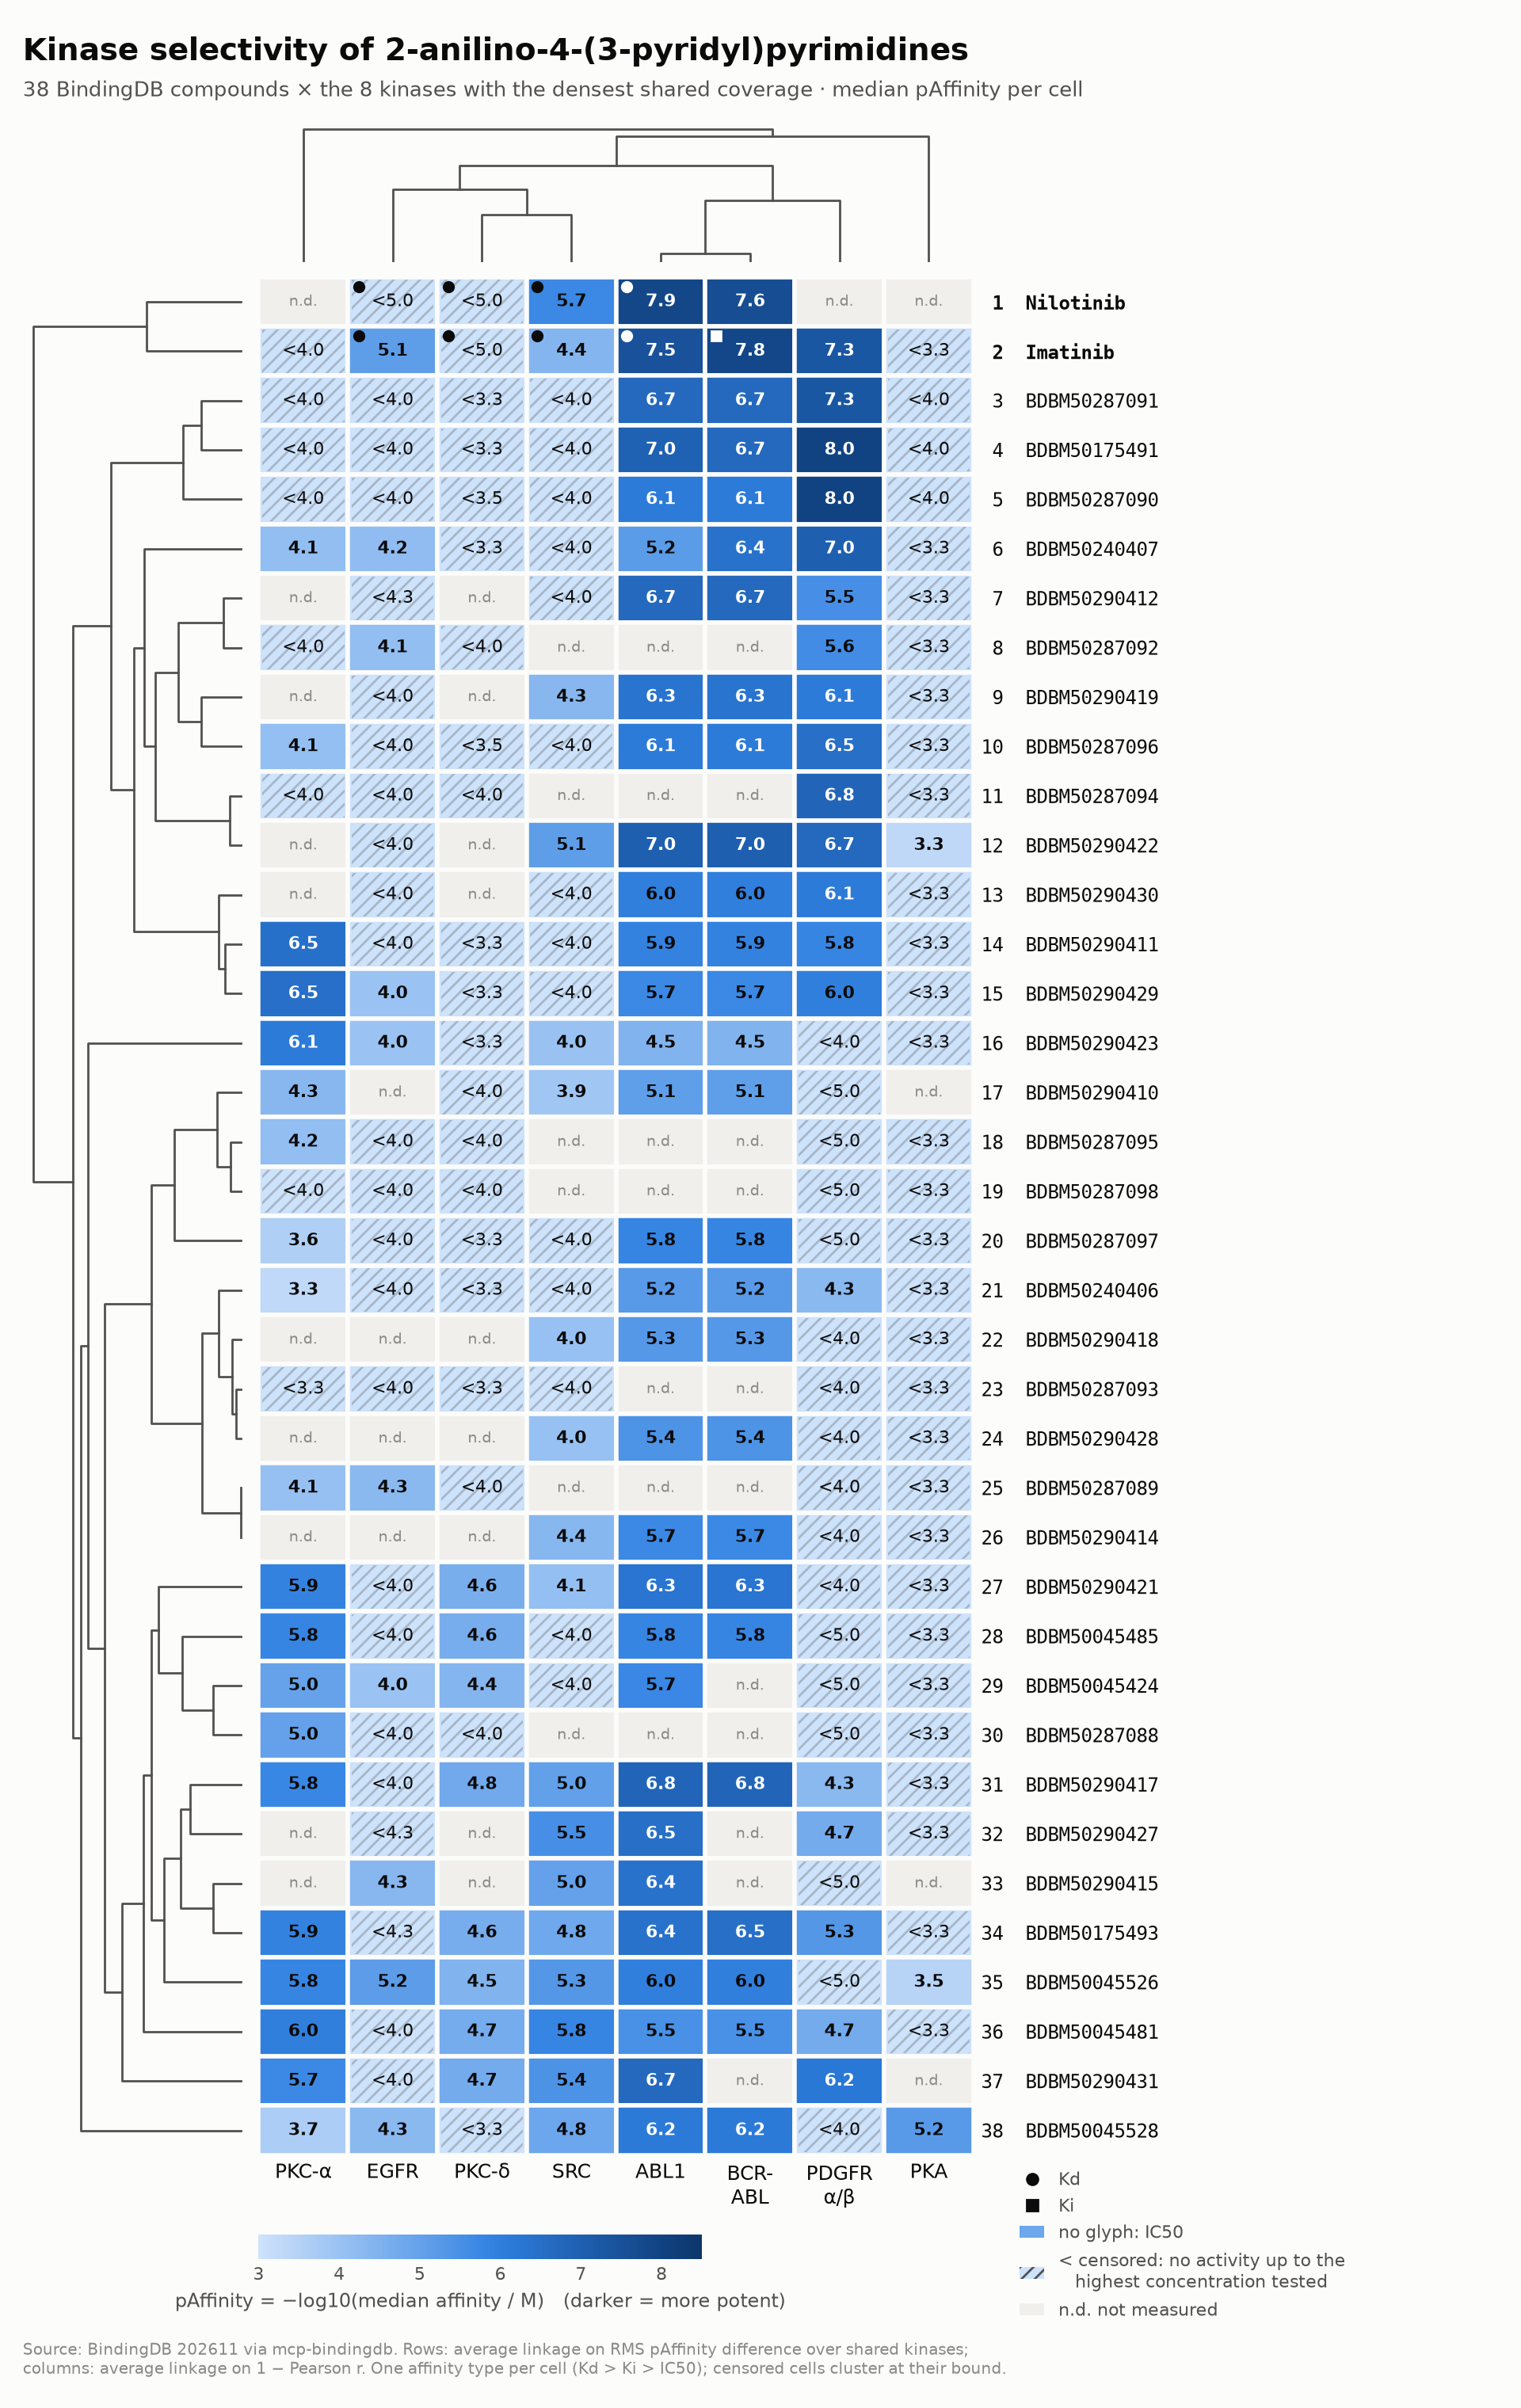

In [ ]:
# Code 1: Scan for the densest block, build and cluster the matrix, draw the heat map, write the CSVs
# The code is in selectivity_heatmap.py, next to this notebook (311 lines).
from selectivity_heatmap import *

drugs = {replay.result(1)['rows'][0]['monomerid']: 'Imatinib', replay.result(2)['rows'][0]['monomerid']: 'Nilotinib'}
scan(replay.result(6), replay.result(7))
blk, cells, tinfo = make_cells(replay.result(8))
cl = cluster(cells, drugs)
summary(cells, tinfo, cl, drugs, replay.result(8))
plot_heatmap(cells, tinfo, cl, drugs, 'kinase_selectivity_heatmap.png')
write_files(cells, tinfo, cl, drugs, replay.result(4), replay.result(8))

**Figure 2: 2-Anilino-4-(3-pyridyl)pyrimidines, heat-map rows 1–15: ABL/PDGFR-active cluster.** _(as recorded)_

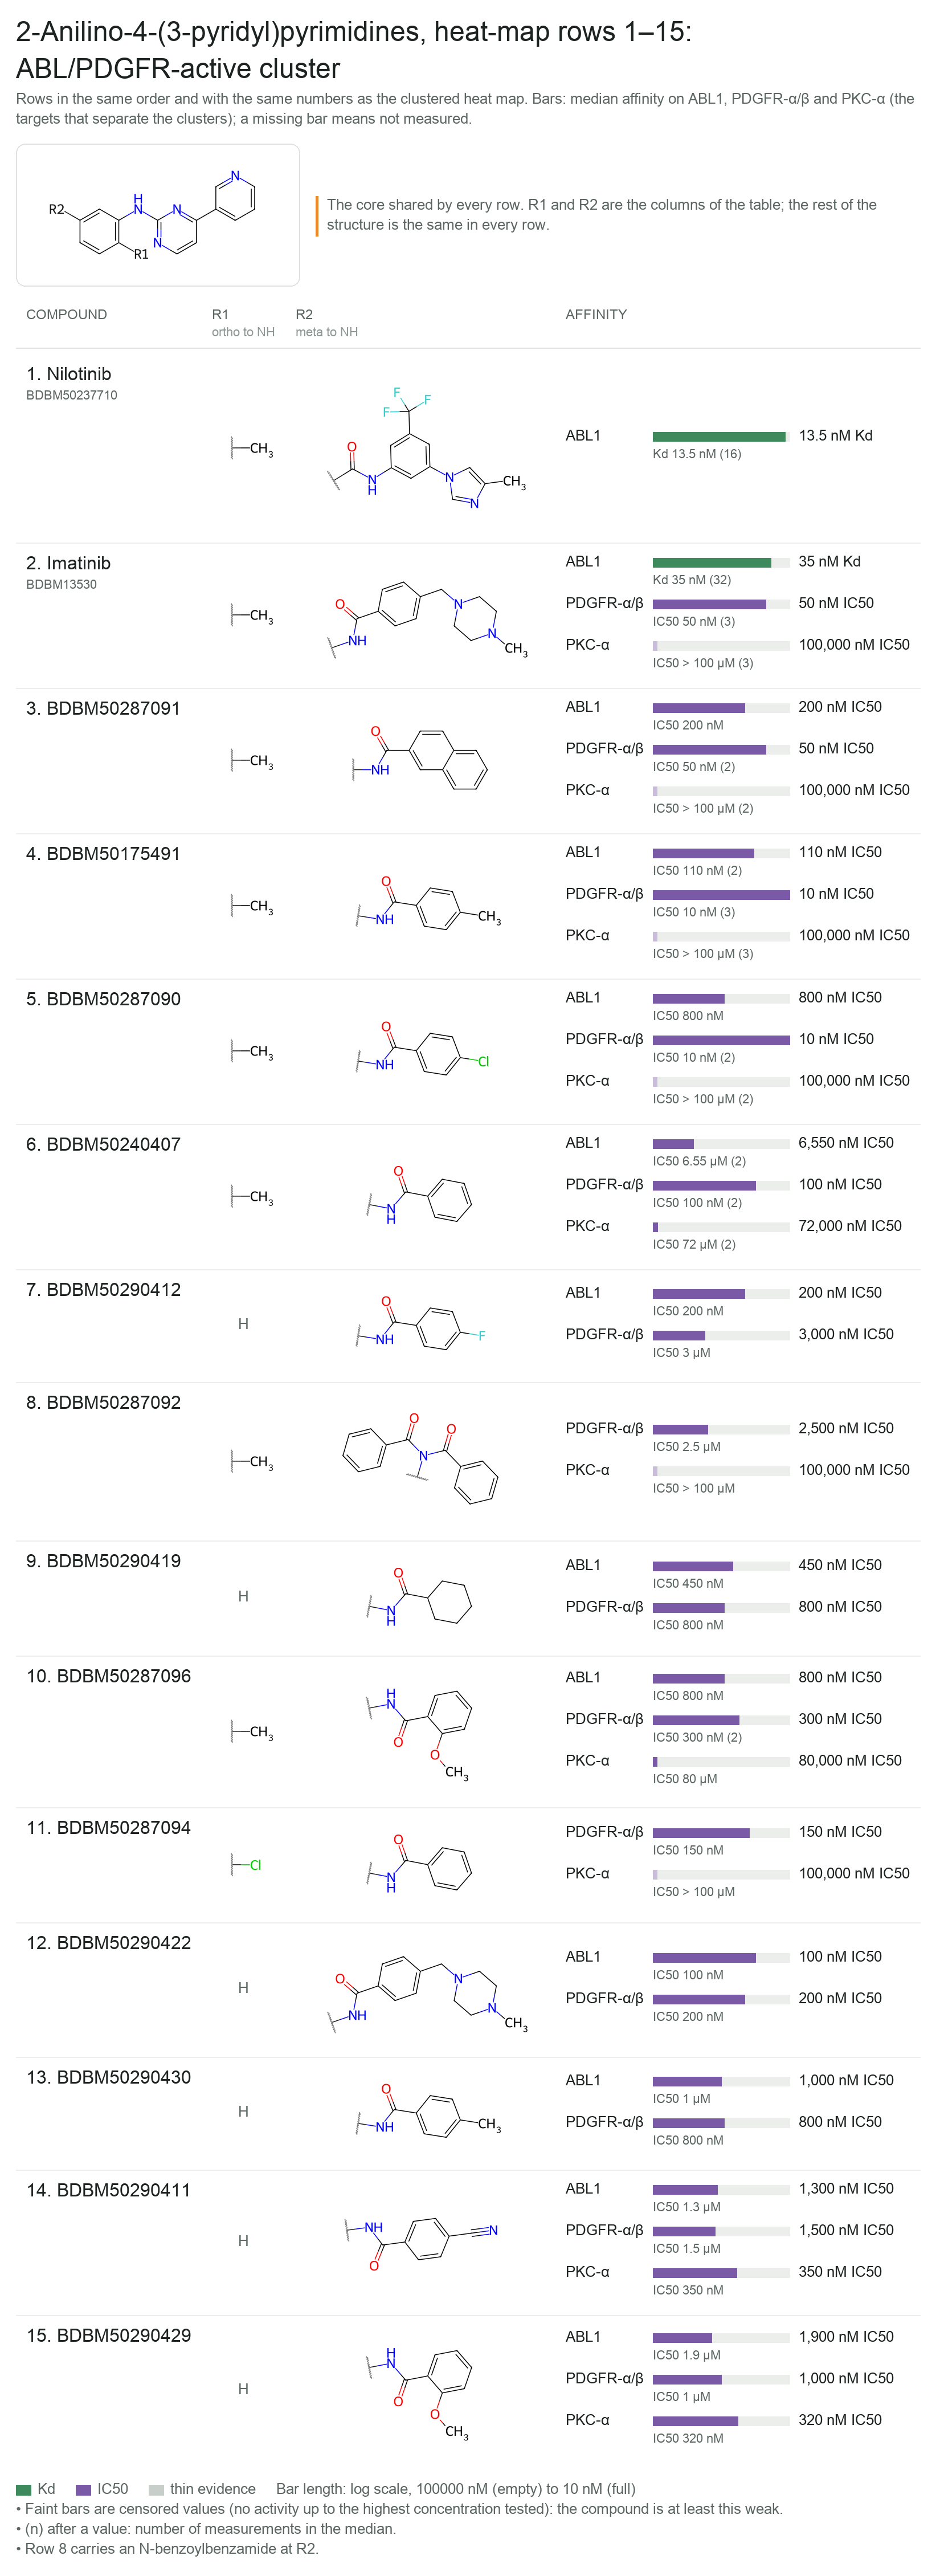

In [ ]:
# Figure 2 · draw_r_group_table draws it again
arguments = {
    'title': '2-Anilino-4-(3-pyridyl)pyrimidines, heat-map rows 1–15: ABL/PDGFR-active cluster',
    'core': 'c1cncc(-c2ccnc(Nc3cc([*:2])ccc3[*:1])n2)c1',
    'rows': [
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'Cc1cn(-c2cc(NC(=O)[*:2])cc(C(F)(F)F)c2)cn1'},
            'title': '1. Nilotinib',
            'subtitle': 'BDBM50237710',
            'bars': [{'label': 'ABL1', 'value_nm': 13.5, 'type': 'Kd', 'note': 'Kd 13.5 nM (16)'}],
        },
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'CN1CCN(Cc2ccc(C(=O)N[*:2])cc2)CC1'},
            'title': '2. Imatinib',
            'subtitle': 'BDBM13530',
            'bars': [
                {'label': 'ABL1', 'value_nm': 35.0, 'type': 'Kd', 'note': 'Kd 35 nM (32)'},
                {'label': 'PDGFR-α/β', 'value_nm': 50.0, 'type': 'IC50', 'note': 'IC50 50 nM (3)'},
                {
                    'label': 'PKC-α',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM (3)',
                    'faint': True,
                },
            ],
        },
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'O=C(N[*:2])c1ccc2ccccc2c1'},
            'title': '3. BDBM50287091',
            'bars': [
                {'label': 'ABL1', 'value_nm': 200.0, 'type': 'IC50', 'note': 'IC50 200 nM'},
                {'label': 'PDGFR-α/β', 'value_nm': 50.0, 'type': 'IC50', 'note': 'IC50 50 nM (2)'},
                {
                    'label': 'PKC-α',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM (2)',
                    'faint': True,
                },
            ],
        },
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'Cc1ccc(C(=O)N[*:2])cc1'},
            'title': '4. BDBM50175491',
            'bars': [
                {'label': 'ABL1', 'value_nm': 110.0, 'type': 'IC50', 'note': 'IC50 110 nM (2)'},
                {'label': 'PDGFR-α/β', 'value_nm': 10.0, 'type': 'IC50', 'note': 'IC50 10 nM (3)'},
                {
                    'label': 'PKC-α',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM (3)',
                    'faint': True,
                },
            ],
        },
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'O=C(N[*:2])c1ccc(Cl)cc1'},
            'title': '5. BDBM50287090',
            'bars': [
                {'label': 'ABL1', 'value_nm': 800.0, 'type': 'IC50', 'note': 'IC50 800 nM'},
                {'label': 'PDGFR-α/β', 'value_nm': 10.0, 'type': 'IC50', 'note': 'IC50 10 nM (2)'},
                {
                    'label': 'PKC-α',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM (2)',
                    'faint': True,
                },
            ],
        },
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'O=C(N[*:2])c1ccccc1'},
            'title': '6. BDBM50240407',
            'bars': [
                {'label': 'ABL1', 'value_nm': 6550.0, 'type': 'IC50', 'note': 'IC50 6.55 µM (2)'},
                {'label': 'PDGFR-α/β', 'value_nm': 100.0, 'type': 'IC50', 'note': 'IC50 100 nM (2)'},
                {'label': 'PKC-α', 'value_nm': 72000.0, 'type': 'IC50', 'note': 'IC50 72 µM (2)'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'O=C(N[*:2])c1ccc(F)cc1'},
            'title': '7. BDBM50290412',
            'bars': [
                {'label': 'ABL1', 'value_nm': 200.0, 'type': 'IC50', 'note': 'IC50 200 nM'},
                {'label': 'PDGFR-α/β', 'value_nm': 3000.0, 'type': 'IC50', 'note': 'IC50 3 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'O=C(c1ccccc1)N(C(=O)c1ccccc1)[*:2]'},
            'title': '8. BDBM50287092',
            'bars': [
                {'label': 'PDGFR-α/β', 'value_nm': 2500.0, 'type': 'IC50', 'note': 'IC50 2.5 µM'},
                {
                    'label': 'PKC-α',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM',
                    'faint': True,
                },
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'O=C(N[*:2])C1CCCCC1'},
            'title': '9. BDBM50290419',
            'bars': [
                {'label': 'ABL1', 'value_nm': 450.0, 'type': 'IC50', 'note': 'IC50 450 nM'},
                {'label': 'PDGFR-α/β', 'value_nm': 800.0, 'type': 'IC50', 'note': 'IC50 800 nM'},
            ],
        },
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'COc1ccccc1C(=O)N[*:2]'},
            'title': '10. BDBM50287096',
            'bars': [
                {'label': 'ABL1', 'value_nm': 800.0, 'type': 'IC50', 'note': 'IC50 800 nM'},
                {'label': 'PDGFR-α/β', 'value_nm': 300.0, 'type': 'IC50', 'note': 'IC50 300 nM (2)'},
                {'label': 'PKC-α', 'value_nm': 80000.0, 'type': 'IC50', 'note': 'IC50 80 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'Cl[*:1]', 'R2': 'O=C(N[*:2])c1ccccc1'},
            'title': '11. BDBM50287094',
            'bars': [
                {'label': 'PDGFR-α/β', 'value_nm': 150.0, 'type': 'IC50', 'note': 'IC50 150 nM'},
                {
                    'label': 'PKC-α',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM',
                    'faint': True,
                },
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'CN1CCN(Cc2ccc(C(=O)N[*:2])cc2)CC1'},
            'title': '12. BDBM50290422',
            'bars': [
                {'label': 'ABL1', 'value_nm': 100.0, 'type': 'IC50', 'note': 'IC50 100 nM'},
                {'label': 'PDGFR-α/β', 'value_nm': 200.0, 'type': 'IC50', 'note': 'IC50 200 nM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'Cc1ccc(C(=O)N[*:2])cc1'},
            'title': '13. BDBM50290430',
            'bars': [
                {'label': 'ABL1', 'value_nm': 1000.0, 'type': 'IC50', 'note': 'IC50 1 µM'},
                {'label': 'PDGFR-α/β', 'value_nm': 800.0, 'type': 'IC50', 'note': 'IC50 800 nM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'N#Cc1ccc(C(=O)N[*:2])cc1'},
            'title': '14. BDBM50290411',
            'bars': [
                {'label': 'ABL1', 'value_nm': 1300.0, 'type': 'IC50', 'note': 'IC50 1.3 µM'},
                {'label': 'PDGFR-α/β', 'value_nm': 1500.0, 'type': 'IC50', 'note': 'IC50 1.5 µM'},
                {'label': 'PKC-α', 'value_nm': 350.0, 'type': 'IC50', 'note': 'IC50 350 nM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'COc1ccccc1C(=O)N[*:2]'},
            'title': '15. BDBM50290429',
            'bars': [
                {'label': 'ABL1', 'value_nm': 1900.0, 'type': 'IC50', 'note': 'IC50 1.9 µM'},
                {'label': 'PDGFR-α/β', 'value_nm': 1000.0, 'type': 'IC50', 'note': 'IC50 1 µM'},
                {'label': 'PKC-α', 'value_nm': 320.0, 'type': 'IC50', 'note': 'IC50 320 nM'},
            ],
        },
    ],
    'description': 'Rows in the same order and with the same numbers as the clustered heat map. Bars: median affinity on ABL1, PDGFR-α/β and PKC-α (the targets that separate the clusters); a missing bar means not measured.',
    'column_notes': {'R1': 'ortho to NH', 'R2': 'meta to NH'},
    'notes': [
        'Faint bars are censored values (no activity up to the highest concentration tested): the compound is at least this weak.',
        '(n) after a value: number of measurements in the median.',
        'Row 8 carries an N-benzoylbenzamide at R2.',
    ],
    'row_heading': 'Compound',
}
await replay.figure(2, 'draw_r_group_table', arguments)

**Figure 3: 2-Anilino-4-(3-pyridyl)pyrimidines, heat-map rows 16–38: weak analogues and the PKC-active cluster.** _(as recorded)_

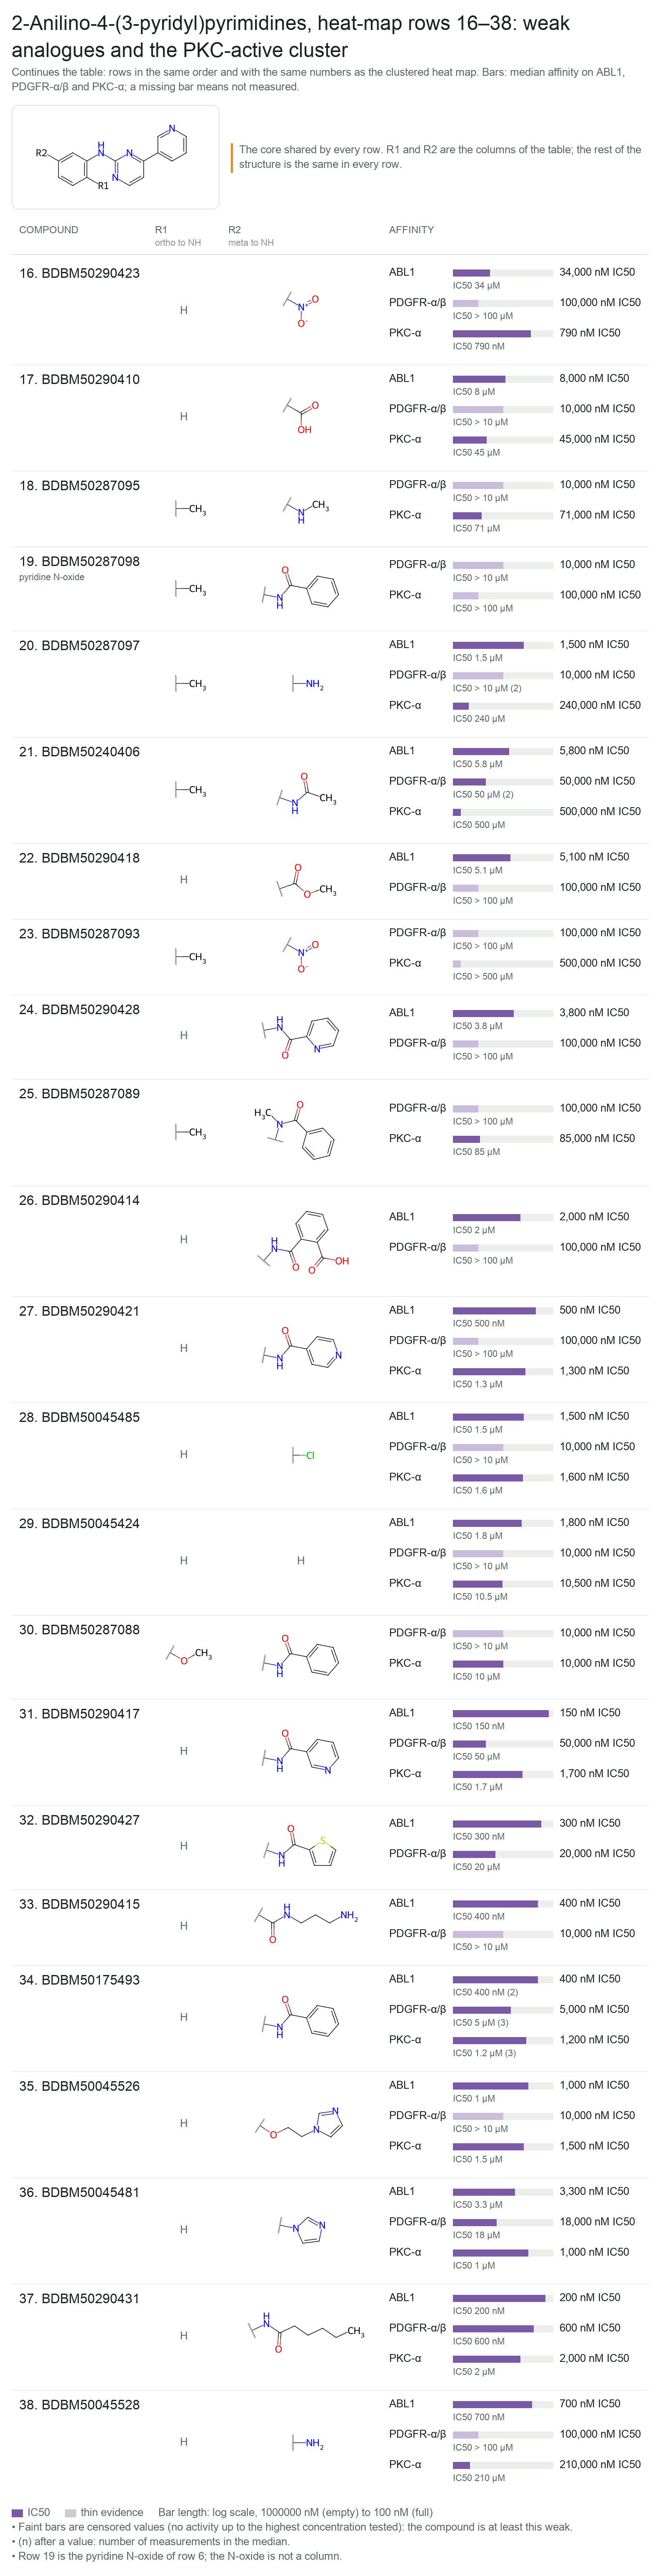

In [ ]:
# Figure 3 · draw_r_group_table draws it again
arguments = {
    'title': '2-Anilino-4-(3-pyridyl)pyrimidines, heat-map rows 16–38: weak analogues and the PKC-active cluster',
    'core': 'c1cncc(-c2ccnc(Nc3cc([*:2])ccc3[*:1])n2)c1',
    'rows': [
        {
            'r_groups': {'R1': 'H', 'R2': 'O=[N+]([O-])[*:2]'},
            'title': '16. BDBM50290423',
            'bars': [
                {'label': 'ABL1', 'value_nm': 34000.0, 'type': 'IC50', 'note': 'IC50 34 µM'},
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM',
                    'faint': True,
                },
                {'label': 'PKC-α', 'value_nm': 790.0, 'type': 'IC50', 'note': 'IC50 790 nM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'O=C(O)[*:2]'},
            'title': '17. BDBM50290410',
            'bars': [
                {'label': 'ABL1', 'value_nm': 8000.0, 'type': 'IC50', 'note': 'IC50 8 µM'},
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 10000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 10 µM',
                    'faint': True,
                },
                {'label': 'PKC-α', 'value_nm': 45000.0, 'type': 'IC50', 'note': 'IC50 45 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'CN[*:2]'},
            'title': '18. BDBM50287095',
            'bars': [
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 10000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 10 µM',
                    'faint': True,
                },
                {'label': 'PKC-α', 'value_nm': 71000.0, 'type': 'IC50', 'note': 'IC50 71 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'O=C(N[*:2])c1ccccc1'},
            'title': '19. BDBM50287098',
            'subtitle': 'pyridine N-oxide',
            'bars': [
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 10000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 10 µM',
                    'faint': True,
                },
                {
                    'label': 'PKC-α',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM',
                    'faint': True,
                },
            ],
        },
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'N[*:2]'},
            'title': '20. BDBM50287097',
            'bars': [
                {'label': 'ABL1', 'value_nm': 1500.0, 'type': 'IC50', 'note': 'IC50 1.5 µM'},
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 10000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 10 µM (2)',
                    'faint': True,
                },
                {'label': 'PKC-α', 'value_nm': 240000.0, 'type': 'IC50', 'note': 'IC50 240 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'CC(=O)N[*:2]'},
            'title': '21. BDBM50240406',
            'bars': [
                {'label': 'ABL1', 'value_nm': 5800.0, 'type': 'IC50', 'note': 'IC50 5.8 µM'},
                {'label': 'PDGFR-α/β', 'value_nm': 50000.0, 'type': 'IC50', 'note': 'IC50 50 µM (2)'},
                {'label': 'PKC-α', 'value_nm': 500000.0, 'type': 'IC50', 'note': 'IC50 500 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'COC(=O)[*:2]'},
            'title': '22. BDBM50290418',
            'bars': [
                {'label': 'ABL1', 'value_nm': 5100.0, 'type': 'IC50', 'note': 'IC50 5.1 µM'},
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM',
                    'faint': True,
                },
            ],
        },
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'O=[N+]([O-])[*:2]'},
            'title': '23. BDBM50287093',
            'bars': [
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM',
                    'faint': True,
                },
                {
                    'label': 'PKC-α',
                    'value_nm': 500000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 500 µM',
                    'faint': True,
                },
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'O=C(N[*:2])c1ccccn1'},
            'title': '24. BDBM50290428',
            'bars': [
                {'label': 'ABL1', 'value_nm': 3800.0, 'type': 'IC50', 'note': 'IC50 3.8 µM'},
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM',
                    'faint': True,
                },
            ],
        },
        {
            'r_groups': {'R1': 'C[*:1]', 'R2': 'CN(C(=O)c1ccccc1)[*:2]'},
            'title': '25. BDBM50287089',
            'bars': [
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM',
                    'faint': True,
                },
                {'label': 'PKC-α', 'value_nm': 85000.0, 'type': 'IC50', 'note': 'IC50 85 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'O=C(O)c1ccccc1C(=O)N[*:2]'},
            'title': '26. BDBM50290414',
            'bars': [
                {'label': 'ABL1', 'value_nm': 2000.0, 'type': 'IC50', 'note': 'IC50 2 µM'},
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM',
                    'faint': True,
                },
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'O=C(N[*:2])c1ccncc1'},
            'title': '27. BDBM50290421',
            'bars': [
                {'label': 'ABL1', 'value_nm': 500.0, 'type': 'IC50', 'note': 'IC50 500 nM'},
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM',
                    'faint': True,
                },
                {'label': 'PKC-α', 'value_nm': 1300.0, 'type': 'IC50', 'note': 'IC50 1.3 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'Cl[*:2]'},
            'title': '28. BDBM50045485',
            'bars': [
                {'label': 'ABL1', 'value_nm': 1500.0, 'type': 'IC50', 'note': 'IC50 1.5 µM'},
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 10000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 10 µM',
                    'faint': True,
                },
                {'label': 'PKC-α', 'value_nm': 1600.0, 'type': 'IC50', 'note': 'IC50 1.6 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'H'},
            'title': '29. BDBM50045424',
            'bars': [
                {'label': 'ABL1', 'value_nm': 1800.0, 'type': 'IC50', 'note': 'IC50 1.8 µM'},
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 10000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 10 µM',
                    'faint': True,
                },
                {'label': 'PKC-α', 'value_nm': 10500.0, 'type': 'IC50', 'note': 'IC50 10.5 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'CO[*:1]', 'R2': 'O=C(N[*:2])c1ccccc1'},
            'title': '30. BDBM50287088',
            'bars': [
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 10000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 10 µM',
                    'faint': True,
                },
                {'label': 'PKC-α', 'value_nm': 10000.0, 'type': 'IC50', 'note': 'IC50 10 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'O=C(N[*:2])c1cccnc1'},
            'title': '31. BDBM50290417',
            'bars': [
                {'label': 'ABL1', 'value_nm': 150.0, 'type': 'IC50', 'note': 'IC50 150 nM'},
                {'label': 'PDGFR-α/β', 'value_nm': 50000.0, 'type': 'IC50', 'note': 'IC50 50 µM'},
                {'label': 'PKC-α', 'value_nm': 1700.0, 'type': 'IC50', 'note': 'IC50 1.7 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'O=C(N[*:2])c1cccs1'},
            'title': '32. BDBM50290427',
            'bars': [
                {'label': 'ABL1', 'value_nm': 300.0, 'type': 'IC50', 'note': 'IC50 300 nM'},
                {'label': 'PDGFR-α/β', 'value_nm': 20000.0, 'type': 'IC50', 'note': 'IC50 20 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'NCCCNC(=O)[*:2]'},
            'title': '33. BDBM50290415',
            'bars': [
                {'label': 'ABL1', 'value_nm': 400.0, 'type': 'IC50', 'note': 'IC50 400 nM'},
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 10000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 10 µM',
                    'faint': True,
                },
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'O=C(N[*:2])c1ccccc1'},
            'title': '34. BDBM50175493',
            'bars': [
                {'label': 'ABL1', 'value_nm': 400.0, 'type': 'IC50', 'note': 'IC50 400 nM (2)'},
                {'label': 'PDGFR-α/β', 'value_nm': 5000.0, 'type': 'IC50', 'note': 'IC50 5 µM (3)'},
                {'label': 'PKC-α', 'value_nm': 1200.0, 'type': 'IC50', 'note': 'IC50 1.2 µM (3)'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'c1cn(CCO[*:2])cn1'},
            'title': '35. BDBM50045526',
            'bars': [
                {'label': 'ABL1', 'value_nm': 1000.0, 'type': 'IC50', 'note': 'IC50 1 µM'},
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 10000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 10 µM',
                    'faint': True,
                },
                {'label': 'PKC-α', 'value_nm': 1500.0, 'type': 'IC50', 'note': 'IC50 1.5 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'c1cn([*:2])cn1'},
            'title': '36. BDBM50045481',
            'bars': [
                {'label': 'ABL1', 'value_nm': 3300.0, 'type': 'IC50', 'note': 'IC50 3.3 µM'},
                {'label': 'PDGFR-α/β', 'value_nm': 18000.0, 'type': 'IC50', 'note': 'IC50 18 µM'},
                {'label': 'PKC-α', 'value_nm': 1000.0, 'type': 'IC50', 'note': 'IC50 1 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'CCCCCC(=O)N[*:2]'},
            'title': '37. BDBM50290431',
            'bars': [
                {'label': 'ABL1', 'value_nm': 200.0, 'type': 'IC50', 'note': 'IC50 200 nM'},
                {'label': 'PDGFR-α/β', 'value_nm': 600.0, 'type': 'IC50', 'note': 'IC50 600 nM'},
                {'label': 'PKC-α', 'value_nm': 2000.0, 'type': 'IC50', 'note': 'IC50 2 µM'},
            ],
        },
        {
            'r_groups': {'R1': 'H', 'R2': 'N[*:2]'},
            'title': '38. BDBM50045528',
            'bars': [
                {'label': 'ABL1', 'value_nm': 700.0, 'type': 'IC50', 'note': 'IC50 700 nM'},
                {
                    'label': 'PDGFR-α/β',
                    'value_nm': 100000.0,
                    'type': 'IC50',
                    'note': 'IC50 > 100 µM',
                    'faint': True,
                },
                {'label': 'PKC-α', 'value_nm': 210000.0, 'type': 'IC50', 'note': 'IC50 210 µM'},
            ],
        },
    ],
    'description': 'Continues the table: rows in the same order and with the same numbers as the clustered heat map. Bars: median affinity on ABL1, PDGFR-α/β and PKC-α; a missing bar means not measured.',
    'column_notes': {'R1': 'ortho to NH', 'R2': 'meta to NH'},
    'notes': [
        'Faint bars are censored values (no activity up to the highest concentration tested): the compound is at least this weak.',
        '(n) after a value: number of measurements in the median.',
        'Row 19 is the pyridine N-oxide of row 6; the N-oxide is not a column.',
    ],
    'row_heading': 'Compound',
}
await replay.figure(3, 'draw_r_group_table', arguments)

**🧠 Assistant**

## The scaffold in BindingDB

A substructure search for the 2-anilino-4-(3-pyridyl)pyrimidine core over all 1,466,457 compounds finds **460 matches**, 453 of them with a Ki, Kd, IC50 or EC50: 3,151 measurements against 492 targets. Restricted to kinases, that is 397 compounds × 397 kinase targets with only 1,716 filled cells (1.1%). Plotted whole, the matrix would be almost entirely empty.

## Choosing an informative block

The measurements come in blocks: one paper profiles a series against the same handful of kinases. So I looked for the densest block, repeatedly dropping kinases measured on too few of the compounds and compounds measured on too few of the kinases:

| min. compounds per kinase | min. kinases per compound | block | filled |
|---|---|---|---|
| 8 | 3 | 140 × 17 | 25% |
| 10 | 3 | 123 × 12 | 35% |
| 20 | 3 | 104 × 10 | 44% |
| 8 | 4 | 38 × 8 | 83% |
| 8 | 6 | 26 × 8 | 93% |

The **38 × 8 block** is the one to plot. It keeps 38 compounds, imatinib and nilotinib among them, and 252 of its 304 cells are filled (416 measurements). It is the classic phenylaminopyrimidine selectivity panel: ABL1, BCR-ABL, PDGFR-α/β, SRC, EGFR, PKC-α, PKC-δ and PKA. Requiring 6 kinases per compound fills 93% of the cells but drops 12 compounds, including several of the PKC-active ones.

## How the cells were filled

- **One affinity type per cell**, preferring Kd, then Ki, IC50, EC50, so a cell never mixes binding constants with inhibition values: 243 IC50, 8 Kd and 1 Ki cell. The Kd and Ki cells are all in the imatinib and nilotinib rows.
- **Median** of the measurements of that type; 59 cells combine two or more.
- **Censored values** (reported as "> x nM": no activity up to the highest concentration tested) are kept, because "inactive at 100 µM" is the informative result for selectivity. Where a cell has exact and censored values, the exact ones decide. A censored cell is shown pale and hatched, with "<" before its pAffinity, since the true pAffinity is below the bound.
- **Clustering:** compounds by average linkage on the root-mean-square pAffinity difference over the kinases both were measured on; kinases by average linkage on 1 − Pearson r. Censored cells enter the clustering at their bound.

## The heat map

Figure 1 shows the clustered block; the R-group tables (Figures 2 and 3) keep its row order and numbering.

**Kinases.** ABL1 and BCR-ABL join first, then PDGFR-α/β: the targets the series was optimised for. PKC-α is the outgroup, because across the compounds its potency runs against ABL/PDGFR. PKA is inactive for almost every compound (31 of 34 cells censored). The ABL1-BCR-ABL pairing is partly an artefact (see the caveats).

**Compounds**, top to bottom:

- **Rows 1-2, nilotinib and imatinib**, are the only compounds below 50 nM on ABL1 (Kd 13.5 nM and 35 nM). Imatinib is inactive on PKC-α and PKC-δ.
- **Rows 3-15, the ABL/PDGFR cluster.** The *ortho-methyl benzamides* (rows 3-6) are the most potent PDGFR inhibitors in the set (10-100 nM); rows 3-5 are inactive on PKC-α up to 100 µM and row 6 reaches it only at 72 µM. Rows 7-15 are mostly the same amides *without the methyl* (rows 8 and 10 keep it, row 11 has a chlorine instead): 100 nM-1.9 µM on ABL1, 150 nM-3 µM on PDGFR, and rows 14-15 already hit PKC-α at about 350 and 320 nM.
- **Rows 16-26: weak and truncated analogues.** The meta position carries a nitro, acid, ester, amine, an acetamide, a picolinamide or an N-methylated amide, or the pyridine is an N-oxide (row 19). These are micromolar at best and mostly inactive on PDGFR; they cluster on shared inactivity. Row 16 (nitro) is the odd one out: weak on ABL1 (34 µM) but 790 nM on PKC-α.
- **Rows 27-38: the PKC-active cluster.** None carries an ortho-methyl (row 30 has an ortho-methoxy) and the meta group is small or heteroaryl: unsubstituted (row 29), chloro, imidazolyl, or nicotin-, isonicotin- and thiophene-amides. They hit PKC-α at 1-2 µM (row 38, an amino compound, is an exception at 210 µM), ABL1 at 150 nM-3.3 µM, and PDGFR barely.

**The methyl ortho to the NH** (the "flag methyl" of imatinib) is what the clusters separate on. With the same amide on the other side, adding it:

| meta amide | without methyl → with methyl | PKC-α | PDGFR-α/β |
|---|---|---|---|
| benzamide | row 34 → row 6 | 1.2 µM → 72 µM (60× weaker) | 5 µM → 100 nM (50× stronger) |
| 2-methoxybenzamide | row 15 → row 10 | 320 nM → 80 µM (250× weaker) | 1 µM → 300 nM (3× stronger) |
| 4-methylbenzamide | row 13 → row 4 | not measured → > 100 µM | 800 nM → 10 nM (80× stronger) |

The methyl removes PKC activity and gains PDGFR potency. It does less for ABL1: the effect there is inconsistent (row 13 → 4: 1 µM → 110 nM; row 15 → 10: 1.9 µM → 800 nM).

## R-group decomposition

All 38 compounds decompose on the core with two positions: **R1 ortho** and **R2 meta** to the anilino NH. A third position, the pyridine nitrogen, is substituted only in the N-oxide (row 19) and is noted on that row rather than given a column. Figures 2 and 3 show the series in heat-map order, split at the main cluster boundary (rows 1-15 and 16-38), with each compound's median affinity on ABL1, PDGFR-α/β and PKC-α. Faint bars are censored values.

## Caveats about data coverage

- **The analogues come from two papers.** 262 of the analogues' measurements in the block are from two Bioorg. Med. Chem. Lett. papers of 1996 (doi 10.1016/0960-894X(96)00197-7, 15 compounds) and 1997 (doi 10.1016/S0960-894X(96)00601-4, 29 compounds). BindingDB holds neither under a PubMed id, so they are found only by DOI. One lab ran one assay panel, so the values are comparable with each other, but the gaps follow the papers: the 1996 paper did not test ABL1, which is why rows 8, 11, 18, 19, 23, 25 and 30 have no ABL1 or BCR-ABL value.
- **The BCR-ABL column is mostly not an independent assay.** 25 of the analogues' BCR-ABL values come from a 2013 paper (doi 10.1016/j.bmcl.2013.01.113), and for 22 of the 27 compounds with both an ABL1 and a BCR-ABL cell the two values are the same, rounded through pIC50 (1,900 nM becomes 1,905 nM). That is why ABL1 and BCR-ABL join first in the kinase tree. Only imatinib, nilotinib and three analogues (rows 4, 6 and 34) have BCR-ABL data that differ from ABL1.
- **Censoring is heavy:** 115 of the 252 filled cells (46%) are censored. Each is a ceiling on pAffinity, not a value, so the selectivity windows are at least as wide as shown. Clustering them at their bound packs the inactive compounds closer together than the data justify.
- **The drugs' rows are not like the others.** Imatinib and nilotinib cells pool up to 32 measurements from dozens of papers and use Kd where it exists. The analogues have one or two IC50 values from the papers above. Compare the drugs with the analogues by rank, not by fold.
- **One median is a compromise.** Row 6's ABL1 cell combines 400 nM (1997) with 12.7 µM (2011, doi 10.1016/j.bmcl.2011.09.127), so its median, 6.55 µM, matches neither measurement. Its BCR-ABL value (about 400 nM, from two later papers) agrees with the 1997 value.
- **Two targets are BindingDB complexes**, PDGFR-α/β and PKA (catalytic subunits α/β/γ), as is BCR-ABL, so the isoform behind each value is not specified. Complexes also carry no organism.
- **The block covers 38 of the 453 measured compounds.** Newer analogues measured against KIT, ABL2 or EGFR mutants were profiled on panels that barely overlap this one, and adding those kinases would mostly add empty cells.

## Files in this folder

| File | Contents |
|---|---|
| kinase_selectivity_heatmap.png | The clustered heat map |
| heatmap_matrix.csv | The 38 × 8 pAffinity matrix in heat-map order ("<" marks censored cells) |
| heatmap_data_long.csv | One row per cell: affinity type, median nM, pAffinity, censoring, number of measurements |
| rgroup_table.csv | The R-group decomposition in heat-map order, with each compound's sources |
| selectivity_heatmap.py | The Python that scans for the block, fills and clusters the matrix, draws the heat map and prepares the R-group tables |

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 8 tool calls, 2 figures to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 5.8 — Clustered selectivity heat map and R-groups of the imatinib core, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```